In [1]:
# ==================================================
# RECUPERAR CONEXIÓN CON SQL SERVER
# ==================================================

import sys
from pathlib import Path

import pandas as pd
from sqlalchemy import text
from dotenv import load_dotenv

# Carpeta principal del proyecto
RUTA_PROYECTO = Path.cwd()

# Cargar configuración del proyecto
load_dotenv(RUTA_PROYECTO / ".env")

# Localizar el archivo database.py
RUTA_SRC = RUTA_PROYECTO / "src"

if str(RUTA_SRC) not in sys.path:
    sys.path.insert(0, str(RUTA_SRC))

# Importar conexión original
from database import engine_sqlserver

# Conectar con SQL Server
engine = engine_sqlserver()

with engine.connect() as conexion:
    nombre_bd = conexion.execute(
        text("SELECT DB_NAME()")
    ).scalar_one()

print("Conexión establecida correctamente.")
print("Base de datos:", nombre_bd)


Conexión establecida correctamente.
Base de datos: RedSaludCarazoDW_V2



## PASO 2. Carga y verificación del dataset predictivo

### Objetivo
Extraer los registros de citas médicas desde SQL Server y comprobar que el conjunto de datos está preparado para las siguientes etapas de minería de datos.

### Actividades
- Cargar los registros de dbo.dm_dataset_prediccion.
- Identificar las columnas y sus tipos de datos.
- Verificar los valores faltantes.
- Comprobar la variable objetivo no_asistio.
- Verificar los identificadores y las fechas.
- Analizar la distribución mensual de las citas.
- Guardar evidencias en archivos CSV.

### Resultado esperado
Obtener un conjunto de datos verificable para su posterior preparación, división cronológica y entrenamiento de modelos predictivos.


In [11]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 2. CARGA Y VERIFICACIÓN DEL DATASET
# ============================================================

import pandas as pd
from pathlib import Path
from sqlalchemy import text
from IPython.display import display


# ============================================================
# 1. CARGAR DATASET PREDICTIVO
# ============================================================

consulta = text("""
    SELECT *
    FROM dbo.dm_dataset_prediccion
""")

with engine.connect() as conexion:

    datos_predictivos = pd.read_sql_query(
        consulta,
        conexion
    )

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("PASO 2. VERIFICACIÓN DEL DATASET PREDICTIVO")
print("=" * 70)

print("\n1. DIMENSIONES DEL DATASET")
print("Registros:", len(datos_predictivos))
print("Columnas:", len(datos_predictivos.columns))

if datos_predictivos.empty:
    raise ValueError(
        "El dataset predictivo está vacío."
    )


# ============================================================
# 2. IDENTIFICAR COLUMNAS
# ============================================================

diccionario_columnas = pd.DataFrame({
    "Columna": datos_predictivos.columns,
    "Tipo_dato": [
        str(tipo)
        for tipo in datos_predictivos.dtypes
    ],
    "Valores_nulos": [
        int(datos_predictivos[campo].isna().sum())
        for campo in datos_predictivos.columns
    ],
    "Valores_distintos": [
        int(datos_predictivos[campo].nunique(
            dropna=True
        ))
        for campo in datos_predictivos.columns
    ]
})

print("\n2. DICCIONARIO DE COLUMNAS")
display(diccionario_columnas)


# ============================================================
# 3. REVISAR VALORES FALTANTES
# ============================================================

resumen_nulos = pd.DataFrame({
    "Columna": datos_predictivos.columns,
    "Nulos": datos_predictivos.isna().sum().values
})

resumen_nulos["Porcentaje_nulos"] = (
    resumen_nulos["Nulos"]
    / len(datos_predictivos)
    * 100
).round(2)

print("\n3. VALORES FALTANTES")
display(resumen_nulos)

print(
    "Total de valores nulos:",
    int(datos_predictivos.isna().sum().sum())
)


# ============================================================
# 4. VERIFICAR VARIABLE OBJETIVO
# ============================================================

objetivo = "no_asistio"

if objetivo not in datos_predictivos.columns:
    raise ValueError(
        "No se encontró la variable objetivo no_asistio."
    )

valores_objetivo = pd.to_numeric(
    datos_predictivos[objetivo],
    errors="coerce"
)

if not valores_objetivo.isin([0, 1]).all():
    raise ValueError(
        "La variable objetivo contiene valores "
        "nulos o diferentes de 0 y 1."
    )

distribucion_objetivo = (
    valores_objetivo
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("no_asistio")
    .reset_index(name="Cantidad")
)

distribucion_objetivo["Porcentaje"] = (
    distribucion_objetivo["Cantidad"]
    / len(datos_predictivos)
    * 100
).round(2)

distribucion_objetivo["Resultado"] = (
    distribucion_objetivo["no_asistio"]
    .map({
        0: "Asistió",
        1: "No asistió"
    })
)

print("\n4. DISTRIBUCIÓN DE LA VARIABLE OBJETIVO")
display(
    distribucion_objetivo[
        [
            "no_asistio",
            "Resultado",
            "Cantidad",
            "Porcentaje"
        ]
    ]
)


# ============================================================
# 5. VERIFICAR IDENTIFICADORES
# ============================================================

if "id_cita" not in datos_predictivos.columns:
    raise ValueError(
        "No se encontró la columna id_cita."
    )

ids_duplicados = int(
    datos_predictivos["id_cita"].duplicated().sum()
)

ids_nulos = int(
    datos_predictivos["id_cita"].isna().sum()
)

print("\n5. VERIFICACIÓN DE IDENTIFICADORES")
print("Identificadores duplicados:", ids_duplicados)
print("Identificadores nulos:", ids_nulos)

if ids_duplicados > 0 or ids_nulos > 0:
    raise ValueError(
        "Se detectaron problemas en los identificadores."
    )


# ============================================================
# 6. VERIFICAR FECHAS
# ============================================================

if "fecha_cita" not in datos_predictivos.columns:
    raise ValueError(
        "No se encontró fecha_cita."
    )

fechas = pd.to_datetime(
    datos_predictivos["fecha_cita"],
    errors="coerce"
)

fechas_invalidas = int(fechas.isna().sum())

print("\n6. VERIFICACIÓN DE FECHAS")
print("Fechas inválidas:", fechas_invalidas)

if fechas_invalidas > 0:
    raise ValueError(
        "Se encontraron fechas inválidas."
    )

print("Fecha mínima:", fechas.min())
print("Fecha máxima:", fechas.max())


# ============================================================
# 7. DISTRIBUCIÓN MENSUAL
# ============================================================

tabla_mensual = (
    pd.DataFrame({
        "Periodo": fechas.dt.to_period("M"),
        "no_asistio": valores_objetivo.astype(int)
    })
    .groupby("Periodo")
    .agg(
        Citas=("no_asistio", "size"),
        Inasistencias=("no_asistio", "sum")
    )
    .reset_index()
)

tabla_mensual["Asistencias"] = (
    tabla_mensual["Citas"]
    - tabla_mensual["Inasistencias"]
)

tabla_mensual["Tasa_inasistencia_pct"] = (
    tabla_mensual["Inasistencias"]
    / tabla_mensual["Citas"]
    * 100
).round(2)

tabla_mensual["Periodo"] = (
    tabla_mensual["Periodo"].astype(str)
)

print("\n7. DISTRIBUCIÓN MENSUAL")
display(tabla_mensual)


# ============================================================
# 8. MOSTRAR REGISTROS DE EJEMPLO
# ============================================================

print("\n8. PRIMEROS CINCO REGISTROS")
display(datos_predictivos.head())



# ============================================================
# 9. GUARDAR EVIDENCIAS
# ============================================================

# Identificar la carpeta de trabajo
proyecto = Path.cwd()

# Definir carpeta donde guardaremos los CSV
carpeta_fuentes = (
    proyecto
    / "resultados"
    / "01_fuentes"
)

# Crear carpetas si todavía no existen
carpeta_fuentes.mkdir(
    parents=True,
    exist_ok=True
)

# Guardar diccionario de columnas
diccionario_columnas.to_csv(
    carpeta_fuentes / "diccionario_columnas.csv",
    index=False,
    encoding="utf-8-sig"
)

# Guardar revisión de valores faltantes
resumen_nulos.to_csv(
    carpeta_fuentes / "valores_faltantes.csv",
    index=False,
    encoding="utf-8-sig"
)

# Guardar distribución de asistencia
distribucion_objetivo.to_csv(
    carpeta_fuentes / "distribucion_objetivo.csv",
    index=False,
    encoding="utf-8-sig"
)

# Guardar distribución mensual
tabla_mensual.to_csv(
    carpeta_fuentes / "distribucion_mensual.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nARCHIVOS GUARDADOS CORRECTAMENTE")
print("Ubicación:", carpeta_fuentes)

for archivo in carpeta_fuentes.glob("*.csv"):
    print("-", archivo.name)


# ============================================================
# 10. RESULTADO FINAL
# ============================================================

print("\n" + "=" * 70)
print("PASO 2 FINALIZADO")
print("=" * 70)

print("Dataset cargado correctamente.")
print("Registros verificados:", len(datos_predictivos))
print("Columnas verificadas:", len(datos_predictivos.columns))
print("Variable objetivo: no_asistio")
print("Evidencias guardadas en:", carpeta_fuentes)
print("Modelos entrenados: 0")
print("SQL Server: SIN MODIFICACIONES")


RED SALUD INTEGRAL CARAZO
PASO 2. VERIFICACIÓN DEL DATASET PREDICTIVO

1. DIMENSIONES DEL DATASET
Registros: 8996
Columnas: 13

2. DICCIONARIO DE COLUMNAS


,Columna,Tipo_dato,Valores_nulos,Valores_distintos
0,id_cita,str,0,8996
1,fecha_cita,object,0,181
2,anio,int64,0,1
3,mes,int64,0,6
4,centro_salud,str,0,4
5,especialidad,str,0,5
6,canal_agendamiento,str,0,4
7,grupo_edad,str,0,4
8,tipo_cobertura,str,0,3
9,espera_dias,int64,0,61



3. VALORES FALTANTES


,Columna,Nulos,Porcentaje_nulos
0,id_cita,0,0.0
1,fecha_cita,0,0.0
2,anio,0,0.0
3,mes,0,0.0
4,centro_salud,0,0.0
5,especialidad,0,0.0
6,canal_agendamiento,0,0.0
7,grupo_edad,0,0.0
8,tipo_cobertura,0,0.0
9,espera_dias,0,0.0


Total de valores nulos: 0

4. DISTRIBUCIÓN DE LA VARIABLE OBJETIVO


...


5. VERIFICACIÓN DE IDENTIFICADORES
Identificadores duplicados: 0
Identificadores nulos: 0

6. VERIFICACIÓN DE FECHAS
Fechas inválidas: 0
Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-06-30 00:00:00

7. DISTRIBUCIÓN MENSUAL


,Periodo,Citas,Inasistencias,Asistencias,Tasa_inasistencia_pct
0,2026-01,1539,597,942,38.79
1,2026-02,1362,510,852,37.44
2,2026-03,1519,582,937,38.31
3,2026-04,1528,569,959,37.24
4,2026-05,1511,560,951,37.06
5,2026-06,1537,563,974,36.63



8. PRIMEROS CINCO REGISTROS


,id_cita,fecha_cita,anio,mes,centro_salud,especialidad,canal_agendamiento,grupo_edad,tipo_cobertura,espera_dias,citas_previas_perdidas,recordatorios_enviados,no_asistio
0,RSV2-000001,2026-04-09,2026,4,DIRIAMBA,MEDICINA GENERAL,WEB,60+,MIXTA,33,1,3,0
1,RSV2-000002,2026-04-30,2026,4,JINOTEPE,LABORATORIO,VENTANILLA,45-59,PRIVADA,6,4,3,1
2,RSV2-000004,2026-03-28,2026,3,DIRIAMBA,GINECOLOGÍA,WEB,30-44,PRIVADA,11,0,1,0
3,RSV2-000006,2026-01-06,2026,1,JINOTEPE,LABORATORIO,CALL CENTER,60+,PÚBLICA,35,4,2,1
4,RSV2-000007,2026-04-27,2026,4,SAN MARCOS,LABORATORIO,VENTANILLA,30-44,PÚBLICA,12,1,0,0



ARCHIVOS GUARDADOS CORRECTAMENTE
Ubicación: c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\01_fuentes
- diccionario_columnas.csv
- diccionario_datos.csv
- distribucion_mensual.csv
- distribucion_objetivo.csv
- valores_faltantes.csv

PASO 2 FINALIZADO
Dataset cargado correctamente.
Registros verificados: 8996
Columnas verificadas: 13
Variable objetivo: no_asistio
Evidencias guardadas en: c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\01_fuentes
Modelos entrenados: 0
SQL Server: SIN MODIFICACIONES



## PASO 3. Preparación de variables predictoras

### Objetivo
Seleccionar y preparar las características del dataset que servirán para entrenar modelos predictivos de inasistencia a citas médicas.

### Variables numéricas
- espera_dias
- citas_previas_perdidas

### Variables categóricas
- centro_salud
- especialidad
- canal_agendamiento
- grupo_edad
- tipo_cobertura
- mes

### Variable objetivo
no_asistio:
- 0: Asistió.
- 1: No asistió.

### Criterios de preparación
- Validar los tipos de datos.
- Comprobar valores faltantes o inválidos.
- Verificar la consistencia de año y mes.
- Excluir identificadores de las variables predictoras.
- Conservar las evidencias para su posterior auditoría.

### Consideración metodológica
La variable citas_previas_perdidas se incorpora a un experimento exploratorio para contrastar el rendimiento histórico. Su disponibilidad temporal deberá verificarse antes de considerar definitivos los modelos.

Las transformaciones de aprendizaje automático se ajustarán posteriormente únicamente sobre los registros de entrenamiento.


In [12]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 3. PREPARACIÓN DE VARIABLES PREDICTORAS
# ============================================================

import pandas as pd
from pathlib import Path
from IPython.display import display


# ============================================================
# 1. PREPARAR EL ENTORNO
# ============================================================

proyecto = Path.cwd()

if "datos_predictivos" not in globals():
    raise RuntimeError(
        "Primero debes ejecutar el PASO 2."
    )

df_modelo = datos_predictivos.copy()

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("PASO 3. PREPARACIÓN DE VARIABLES")
print("=" * 70)

print("\nRegistros iniciales:", len(df_modelo))
print("Columnas iniciales:", len(df_modelo.columns))


# ============================================================
# 2. DEFINIR VARIABLE OBJETIVO
# ============================================================

OBJETIVO = "no_asistio"


# ============================================================
# 3. DEFINIR VARIABLES PREDICTORAS
# ============================================================

# Variables numéricas
NUM = [
    "espera_dias",
    "citas_previas_perdidas"
]

# Variables categóricas
CAT = [
    "centro_salud",
    "especialidad",
    "canal_agendamiento",
    "grupo_edad",
    "tipo_cobertura",
    "mes"
]

# Lista de todas las variables predictoras
FEATURES = NUM + CAT

# Variables auxiliares de auditoría
IDENTIFICADOR = "id_cita"
FECHA = "fecha_cita"


# ============================================================
# 4. VERIFICAR COLUMNAS OBLIGATORIAS
# ============================================================

columnas_requeridas = (
    FEATURES
    + [OBJETIVO, IDENTIFICADOR, FECHA, "anio"]
)

faltantes = set(columnas_requeridas) - set(
    df_modelo.columns
)

if faltantes:
    raise ValueError(
        f"Columnas faltantes: {sorted(faltantes)}"
    )

print("\nColumnas obligatorias: VERIFICADAS")


# ============================================================
# 5. PREPARAR Y VERIFICAR FECHAS
# ============================================================

df_modelo[FECHA] = pd.to_datetime(
    df_modelo[FECHA],
    errors="coerce"
)

fechas_invalidas = int(
    df_modelo[FECHA].isna().sum()
)

if fechas_invalidas > 0:
    raise ValueError(
        f"Fechas inválidas: {fechas_invalidas}"
    )

# Comprobar el año y mes registrados en SQL Server
anios_originales = pd.to_numeric(
    df_modelo["anio"],
    errors="coerce"
)

meses_originales = pd.to_numeric(
    df_modelo["mes"],
    errors="coerce"
)

errores_anio = int(
    (
        anios_originales
        != df_modelo[FECHA].dt.year
    ).sum()
)

errores_mes = int(
    (
        meses_originales
        != df_modelo[FECHA].dt.month
    ).sum()
)

if errores_anio > 0 or errores_mes > 0:
    raise ValueError(
        "Existen inconsistencias entre fecha_cita, "
        "anio y mes."
    )

print("\nFechas válidas:", len(df_modelo))
print("Inconsistencias de año:", errores_anio)
print("Inconsistencias de mes:", errores_mes)


# ============================================================
# 6. PREPARAR VARIABLE OBJETIVO
# ============================================================

df_modelo[OBJETIVO] = pd.to_numeric(
    df_modelo[OBJETIVO],
    errors="coerce"
)

if not df_modelo[OBJETIVO].isin([0, 1]).all():
    raise ValueError(
        "La variable objetivo contiene valores inválidos."
    )

df_modelo[OBJETIVO] = (
    df_modelo[OBJETIVO].astype(int)
)


# ============================================================
# 7. PREPARAR VARIABLES NUMÉRICAS
# ============================================================

for columna in NUM:

    df_modelo[columna] = pd.to_numeric(
        df_modelo[columna],
        errors="coerce"
    )

    nulos = df_modelo[columna].isna().sum()

    negativos = (
        df_modelo[columna] < 0
    ).sum()

    decimales = (
        df_modelo[columna].notna()
        & (
            df_modelo[columna]
            != df_modelo[columna].round()
        )
    ).sum()

    if nulos or negativos or decimales:

        raise ValueError(
            f"Variable {columna}: "
            f"nulos={nulos}, "
            f"negativos={negativos}, "
            f"no_enteros={decimales}"
        )

print("\nVariables numéricas: VERIFICADAS")


# ============================================================
# 8. PREPARAR VARIABLES CATEGÓRICAS
# ============================================================

for columna in CAT:

    if columna == "mes":

        # Representar el mes como categoría
        # y no como valor numérico continuo.

        df_modelo[columna] = (
            df_modelo[FECHA]
            .dt.month
            .astype(str)
        )

    else:

        df_modelo[columna] = (
            df_modelo[columna]
            .astype("string")
            .str.strip()
        )

        if (
            df_modelo[columna].isna().any()
            or df_modelo[columna].eq("").any()
        ):
            raise ValueError(
                f"Existen categorías vacías en {columna}."
            )

        # Conservar valores como texto estándar
        df_modelo[columna] = (
            df_modelo[columna].astype(str)
        )

print("Variables categóricas: VERIFICADAS")


# ============================================================
# 9. VERIFICAR IDENTIFICADORES
# ============================================================

if (
    df_modelo[IDENTIFICADOR].isna().any()
    or df_modelo[IDENTIFICADOR].duplicated().any()
):
    raise ValueError(
        "Existen identificadores nulos o duplicados."
    )


# ============================================================
# 10. DEFINIR DATASET PARA MODELADO
# ============================================================

# Conservar ID y fecha para auditoría.
# NO serán variables predictoras.

columnas_modelado = [
    IDENTIFICADOR,
    FECHA
] + FEATURES + [OBJETIVO]

dataset_modelado = (
    df_modelo[columnas_modelado]
    .copy()
)

# Preparar conjunto de predictores y objetivo.
# Todavía NO se entrenarán modelos.

X = dataset_modelado[FEATURES].copy()
y = dataset_modelado[OBJETIVO].copy()

assert OBJETIVO not in X.columns
assert IDENTIFICADOR not in X.columns
assert FECHA not in X.columns

assert len(X) == len(y)
assert len(X) == len(df_modelo)


# ============================================================
# 11. CONSTRUIR DICCIONARIO DE VARIABLES
# ============================================================

resumen_variables = []

for columna in FEATURES:

    tipo_variable = (
        "NUMERICA"
        if columna in NUM
        else "CATEGORICA"
    )

    estado_temporal = (
        "PENDIENTE_VERIFICACION"
        if columna == "citas_previas_perdidas"
        else "REVISAR_DISPONIBILIDAD_PREVIA"
    )

    resumen_variables.append({
        "Variable": columna,
        "Tipo": tipo_variable,
        "Valores_distintos": int(
            dataset_modelado[columna].nunique()
        ),
        "Valores_faltantes": int(
            dataset_modelado[columna].isna().sum()
        ),
        "Estado_temporal": estado_temporal
    })

tabla_variables = pd.DataFrame(
    resumen_variables
)


# ============================================================
# 12. ESTADÍSTICAS NUMÉRICAS
# ============================================================

print("\n" + "=" * 70)
print("1. VARIABLES PREDICTORAS")
print("=" * 70)

display(tabla_variables)

print("\n2. ESTADÍSTICAS NUMÉRICAS")

display(
    dataset_modelado[NUM]
    .describe()
    .round(2)
)


# ============================================================
# 13. DISTRIBUCIÓN DEL OBJETIVO
# ============================================================

tabla_objetivo = (
    dataset_modelado[OBJETIVO]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("no_asistio")
    .reset_index(name="Cantidad")
)

tabla_objetivo["Porcentaje"] = (
    tabla_objetivo["Cantidad"]
    / len(dataset_modelado)
    * 100
).round(2)

print("\n3. DISTRIBUCIÓN DEL OBJETIVO")
display(tabla_objetivo)


# ============================================================
# 14. DISTRIBUCIÓN DE CITAS PREVIAS PERDIDAS
# ============================================================

tabla_citas_previas = (
    dataset_modelado
    .groupby("citas_previas_perdidas")
    .agg(
        Total_citas=(OBJETIVO, "size"),
        Inasistencias=(OBJETIVO, "sum")
    )
    .reset_index()
)

tabla_citas_previas["Tasa_inasistencia_pct"] = (
    tabla_citas_previas["Inasistencias"]
    / tabla_citas_previas["Total_citas"]
    * 100
).round(2)

print("\n4. INASISTENCIA SEGÚN CITAS PREVIAS")
display(tabla_citas_previas)


# ============================================================
# 15. VERIFICAR DIMENSIONES
# ============================================================

print("\n" + "=" * 70)
print("5. DATASET PREPARADO")
print("=" * 70)

print("Registros:", len(dataset_modelado))
print("Variables predictoras:", len(FEATURES))
print("Variables numéricas:", len(NUM))
print("Variables categóricas:", len(CAT))
print("Variable objetivo:", OBJETIVO)

print("\nDimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)


# ============================================================
# 16. GUARDAR EVIDENCIAS
# ============================================================

carpeta_preparacion = (
    proyecto
    / "resultados"
    / "03_preparacion"
)

carpeta_preparacion.mkdir(
    parents=True,
    exist_ok=True
)

tabla_variables.to_csv(
    carpeta_preparacion
    / "diccionario_variables_modelado.csv",
    index=False,
    encoding="utf-8-sig"
)

tabla_citas_previas.to_csv(
    carpeta_preparacion
    / "analisis_citas_previas.csv",
    index=False,
    encoding="utf-8-sig"
)

dataset_modelado.to_csv(
    carpeta_preparacion
    / "dataset_preparado.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 17. RESULTADO FINAL
# ============================================================

print("\n" + "=" * 70)
print("PASO 3 FINALIZADO")
print("=" * 70)

print("Dataset preparado correctamente.")
print("Variables predictoras definidas:", len(FEATURES))
print("Objetivo separado correctamente.")
print("Archivos guardados en:", carpeta_preparacion)
print("Modelos entrenados: 0")
print("SQL Server: SIN MODIFICACIONES")

print(
    "\nADVERTENCIA: citas_previas_perdidas "
    "sigue pendiente de verificación temporal."
)


RED SALUD INTEGRAL CARAZO
PASO 3. PREPARACIÓN DE VARIABLES

Registros iniciales: 8996
Columnas iniciales: 13

Columnas obligatorias: VERIFICADAS

Fechas válidas: 8996
Inconsistencias de año: 0
Inconsistencias de mes: 0

Variables numéricas: VERIFICADAS
Variables categóricas: VERIFICADAS

1. VARIABLES PREDICTORAS


,Variable,Tipo,Valores_distintos,Valores_faltantes,Estado_temporal
0,espera_dias,NUMERICA,61,0,REVISAR_DISPONIBILIDAD_PREVIA
1,citas_previas_perdidas,NUMERICA,5,0,PENDIENTE_VERIFICACION
2,centro_salud,CATEGORICA,4,0,REVISAR_DISPONIBILIDAD_PREVIA
3,especialidad,CATEGORICA,5,0,REVISAR_DISPONIBILIDAD_PREVIA
4,canal_agendamiento,CATEGORICA,4,0,REVISAR_DISPONIBILIDAD_PREVIA
5,grupo_edad,CATEGORICA,4,0,REVISAR_DISPONIBILIDAD_PREVIA
6,tipo_cobertura,CATEGORICA,3,0,REVISAR_DISPONIBILIDAD_PREVIA
7,mes,CATEGORICA,6,0,REVISAR_DISPONIBILIDAD_PREVIA



2. ESTADÍSTICAS NUMÉRICAS


,espera_dias,citas_previas_perdidas
count,8996.00,8996.00
mean,19.93,1.41
std,16.19,1.26
min,0.00,0.00
25%,7.00,0.00
50%,15.00,1.00
75%,29.00,2.00
max,60.00,4.00



3. DISTRIBUCIÓN DEL OBJETIVO


,no_asistio,Cantidad,Porcentaje
0,0,5615,62.42
1,1,3381,37.58



4. INASISTENCIA SEGÚN CITAS PREVIAS


,citas_previas_perdidas,Total_citas,Inasistencias,Tasa_inasistencia_pct
0,0,2809,232,8.26
1,1,2282,425,18.62
2,2,2013,1117,55.49
3,3,1193,966,80.97
4,4,699,641,91.70



5. DATASET PREPARADO
Registros: 8996
Variables predictoras: 8
Variables numéricas: 2
Variables categóricas: 6
Variable objetivo: no_asistio

Dimensiones de X: (8996, 8)
Dimensiones de y: (8996,)

PASO 3 FINALIZADO
Dataset preparado correctamente.
Variables predictoras definidas: 8
Objetivo separado correctamente.
Archivos guardados en: c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\03_preparacion
Modelos entrenados: 0
SQL Server: SIN MODIFICACIONES

ADVERTENCIA: citas_previas_perdidas sigue pendiente de verificación temporal.



## PASO 4. División cronológica del dataset

### Objetivo
Separar los registros predictivos en tres conjuntos independientes para entrenar, validar y evaluar los modelos de minería de datos.

### Distribución temporal
- Entrenamiento: enero a abril de 2026.
- Validación: mayo de 2026.
- Prueba final: junio de 2026.

### Criterios metodológicos
- Todos los algoritmos utilizarán la misma división.
- Los modelos se entrenarán exclusivamente con enero-abril.
- La comparación y selección de los mejores modelos se realizará con mayo.
- Junio se reservará para la evaluación final de los tres modelos seleccionados.
- Se verificará que no existan identificadores repetidos entre conjuntos.
- Las variables predictoras estarán separadas de la variable objetivo.

### Consideración
La variable citas_previas_perdidas permanece pendiente de verificación temporal antes de considerar definitivos los resultados predictivos.


In [13]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 4. DIVISIÓN CRONOLÓGICA DEL DATASET
# ============================================================

import pandas as pd
from pathlib import Path
from IPython.display import display


# ============================================================
# 1. VERIFICAR DATOS DEL PASO 3
# ============================================================

if "dataset_modelado" not in globals():
    raise RuntimeError(
        "Debes ejecutar primero el PASO 3."
    )

if "FEATURES" not in globals():
    raise RuntimeError(
        "No se encontraron las variables predictoras."
    )

if "OBJETIVO" not in globals():
    raise RuntimeError(
        "No se encontró la variable objetivo."
    )

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("PASO 4. DIVISIÓN CRONOLÓGICA")
print("=" * 70)


# ============================================================
# 2. PREPARAR COPIA DE LOS DATOS
# ============================================================

df_particion = dataset_modelado.copy()

df_particion["fecha_cita"] = pd.to_datetime(
    df_particion["fecha_cita"],
    errors="coerce"
)

if df_particion["fecha_cita"].isna().any():
    raise ValueError(
        "Existen fechas inválidas."
    )

if df_particion["id_cita"].duplicated().any():
    raise ValueError(
        "Existen identificadores duplicados."
    )

if not df_particion[OBJETIVO].isin([0, 1]).all():
    raise ValueError(
        "La variable objetivo contiene valores inválidos."
    )


# ============================================================
# 3. DIVISIÓN CRONOLÓGICA
# ============================================================

# Entrenamiento: enero a abril
train = df_particion.loc[
    (df_particion["fecha_cita"] >= "2026-01-01")
    & (df_particion["fecha_cita"] < "2026-05-01")
].copy()

# Validación: mayo
val = df_particion.loc[
    (df_particion["fecha_cita"] >= "2026-05-01")
    & (df_particion["fecha_cita"] < "2026-06-01")
].copy()

# Prueba final: junio
test = df_particion.loc[
    (df_particion["fecha_cita"] >= "2026-06-01")
    & (df_particion["fecha_cita"] < "2026-07-01")
].copy()


# ============================================================
# 4. VERIFICAR LAS PARTICIONES
# ============================================================

conjuntos = {
    "ENTRENAMIENTO": train,
    "VALIDACION": val,
    "PRUEBA": test
}

for nombre, datos in conjuntos.items():

    if datos.empty:
        raise ValueError(
            f"El conjunto {nombre} está vacío."
        )

    if datos[OBJETIVO].nunique() != 2:
        raise ValueError(
            f"{nombre} no contiene ambas clases."
        )

total_particiones = (
    len(train) + len(val) + len(test)
)

if total_particiones != len(df_particion):
    raise ValueError(
        "Existen registros fuera de los períodos."
    )

# Comprobar separación temporal
assert (
    train["fecha_cita"].max()
    < val["fecha_cita"].min()
)

assert (
    val["fecha_cita"].max()
    < test["fecha_cita"].min()
)

# Comprobar que no se repiten citas
ids_train = set(train["id_cita"])
ids_val = set(val["id_cita"])
ids_test = set(test["id_cita"])

assert ids_train.isdisjoint(ids_val)
assert ids_train.isdisjoint(ids_test)
assert ids_val.isdisjoint(ids_test)


# ============================================================
# 5. SEPARAR PREDICTORAS Y OBJETIVO
# ============================================================

X_train = train[FEATURES].copy()
y_train = train[OBJETIVO].astype(int).copy()

X_val = val[FEATURES].copy()
y_val = val[OBJETIVO].astype(int).copy()

# La prueba final permanecerá reservada.
X_test = test[FEATURES].copy()
y_test = test[OBJETIVO].astype(int).copy()

# Verificar que no hay columnas excluidas
assert OBJETIVO not in X_train.columns
assert "id_cita" not in X_train.columns
assert "fecha_cita" not in X_train.columns

assert list(X_train.columns) == list(X_val.columns)
assert list(X_val.columns) == list(X_test.columns)


# ============================================================
# 6. CONSTRUIR TABLA DE DISTRIBUCIÓN
# ============================================================

resumen = []

for nombre, datos in conjuntos.items():

    total = len(datos)

    inasistencias = int(
        datos[OBJETIVO].sum()
    )

    asistencias = total - inasistencias

    resumen.append({
        "Conjunto": nombre,
        "Registros": total,
        "Asistencias": asistencias,
        "Inasistencias": inasistencias,
        "Tasa_inasistencia_pct": round(
            inasistencias / total * 100,
            2
        ),
        "Fecha_minima": str(
            datos["fecha_cita"].min().date()
        ),
        "Fecha_maxima": str(
            datos["fecha_cita"].max().date()
        )
    })

tabla_particiones = pd.DataFrame(resumen)


# ============================================================
# 7. MOSTRAR RESULTADOS
# ============================================================

print("\n1. DISTRIBUCIÓN DE LOS CONJUNTOS")
display(tabla_particiones)

print("\n2. DIMENSIONES DE ENTRENAMIENTO")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\n3. DIMENSIONES DE VALIDACIÓN")

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\n4. DIMENSIONES DE PRUEBA FINAL")

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\n5. CONTROLES")

print("Variables predictoras:", len(FEATURES))
print("Variable objetivo:", OBJETIVO)
print("Total de registros:", total_particiones)
print("Identificadores compartidos: 0")
print("Separación temporal: VERIFICADA")


# ============================================================
# 8. GUARDAR EVIDENCIAS
# ============================================================

proyecto = Path.cwd()

carpeta_particion = (
    proyecto
    / "resultados"
    / "03_preparacion"
)

carpeta_particion.mkdir(
    parents=True,
    exist_ok=True
)

tabla_particiones.to_csv(
    carpeta_particion
    / "division_cronologica.csv",
    index=False,
    encoding="utf-8-sig"
)

# Evidencia de qué registros pertenecen
# a cada conjunto, sin entrenar modelos.

auditoria_particiones = pd.concat(
    [
        train.assign(
            Conjunto="ENTRENAMIENTO"
        ),
        val.assign(
            Conjunto="VALIDACION"
        ),
        test.assign(
            Conjunto="PRUEBA"
        )
    ],
    ignore_index=True
)

auditoria_particiones[
    [
        "id_cita",
        "fecha_cita",
        "Conjunto",
        OBJETIVO
    ]
].to_csv(
    carpeta_particion
    / "auditoria_particiones.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 9. RESULTADO FINAL
# ============================================================

print("\n" + "=" * 70)
print("PASO 4 FINALIZADO")
print("=" * 70)

print("División cronológica: CORRECTA")
print("Entrenamiento:", len(train))
print("Validación:", len(val))
print("Prueba final:", len(test))

print("\nArchivos guardados en:")
print(carpeta_particion)

print("\nModelos entrenados: 0")
print("Datos de junio evaluados por modelos: NO")
print("SQL Server: SIN MODIFICACIONES")


RED SALUD INTEGRAL CARAZO
PASO 4. DIVISIÓN CRONOLÓGICA

1. DISTRIBUCIÓN DE LOS CONJUNTOS


,Conjunto,Registros,Asistencias,Inasistencias,Tasa_inasistencia_pct,Fecha_minima,Fecha_maxima
0,ENTRENAMIENTO,5948,3690,2258,37.96,2026-01-01,2026-04-30
1,VALIDACION,1511,951,560,37.06,2026-05-01,2026-05-31
2,PRUEBA,1537,974,563,36.63,2026-06-01,2026-06-30



2. DIMENSIONES DE ENTRENAMIENTO
X_train: (5948, 8)
y_train: (5948,)

3. DIMENSIONES DE VALIDACIÓN
X_val: (1511, 8)
y_val: (1511,)

4. DIMENSIONES DE PRUEBA FINAL
X_test: (1537, 8)
y_test: (1537,)

5. CONTROLES
Variables predictoras: 8
Variable objetivo: no_asistio
Total de registros: 8996
Identificadores compartidos: 0
Separación temporal: VERIFICADA

PASO 4 FINALIZADO
División cronológica: CORRECTA
Entrenamiento: 5948
Validación: 1511
Prueba final: 1537

Archivos guardados en:
c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\03_preparacion

Modelos entrenados: 0
Datos de junio evaluados por modelos: NO
SQL Server: SIN MODIFICACIONES



## PASO 5. Configuración del preprocesamiento y los algoritmos

### Objetivo
Configurar siete algoritmos de aprendizaje automático para comparar su capacidad de predecir la inasistencia a citas médicas.

### Algoritmos seleccionados
1. Regresión Logística.
2. Árbol de Decisión.
3. Random Forest.
4. Gradient Boosting.
5. KNN (k=10).
6. Naive Bayes.
7. SVM (RBF).

### Preprocesamiento
- Imputación por mediana para las variables numéricas.
- Estandarización numérica para los algoritmos que la requieren.
- Imputación por moda para las variables categóricas.
- Codificación One-Hot para las categorías.
- Uso de Pipeline para prevenir que el preprocesamiento aprenda información de validación o prueba.

### Evaluación posterior
La comparación se realizará sobre mayo de 2026 utilizando Accuracy, Precision, Recall, F1, F2, ROC-AUC y PR-AUC.

Se seleccionarán tres modelos diferentes por su rendimiento de validación.

### Indicadores del proyecto
- KPI-M01: ROC-AUC.
- KPI-M02: Recall.
- KPI-C01: Completitud de los registros predictivos.

### Control metodológico
La procedencia temporal de citas_previas_perdidas deberá verificarse antes de considerar válidos los resultados predictivos finales.


In [14]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 5. CONFIGURACIÓN DE SIETE MODELOS
# ============================================================

import sys
import pandas as pd
import sklearn

from pathlib import Path
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC


# ============================================================
# 1. VERIFICAR LOS DATOS PREPARADOS
# ============================================================

variables_necesarias = [
    "NUM",
    "CAT",
    "FEATURES",
    "X_train",
    "y_train",
    "X_val",
    "y_val"
]

faltantes = [
    nombre
    for nombre in variables_necesarias
    if nombre not in globals()
]

if faltantes:
    raise RuntimeError(
        "Ejecuta primero los PASOS 3 y 4. "
        f"Faltan: {faltantes}"
    )

assert len(X_train) == 5948
assert len(X_val) == 1511

assert len(FEATURES) == 8
assert len(NUM) == 2
assert len(CAT) == 6

assert list(X_train.columns) == FEATURES
assert list(X_val.columns) == FEATURES

assert "no_asistio" not in X_train.columns
assert "id_cita" not in X_train.columns

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("PASO 5. CONFIGURACIÓN DE SIETE MODELOS")
print("=" * 70)

print("\nVersión de Python:", sys.version.split()[0])
print("Versión de scikit-learn:", sklearn.__version__)

print("\nEntrenamiento:", len(X_train))
print("Validación:", len(X_val))
print("Variables predictoras:", len(FEATURES))


# ============================================================
# 2. CREAR FUNCIÓN DE PREPROCESAMIENTO
# ============================================================

def crear_preprocesador(escalar=False):

    # Preparar variables numéricas
    pasos_numericos = [
        (
            "imputador",
            SimpleImputer(strategy="median")
        )
    ]

    if escalar:

        pasos_numericos.append(
            (
                "escalador",
                StandardScaler()
            )
        )

    preprocesamiento_numerico = Pipeline(
        pasos_numericos
    )

    # Compatibilidad con distintas versiones
    # de scikit-learn
    try:

        codificador = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )

    except TypeError:

        codificador = OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        )

    preprocesamiento_categorico = Pipeline([
        (
            "imputador",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "codificador",
            codificador
        )
    ])

    # Integrar preprocesamiento
    preprocesador = ColumnTransformer(
        transformers=[
            (
                "numericas",
                preprocesamiento_numerico,
                NUM
            ),
            (
                "categoricas",
                preprocesamiento_categorico,
                CAT
            )
        ],
        remainder="drop"
    )

    return preprocesador


# ============================================================
# 3. CREAR FUNCIÓN PARA CONSTRUIR MODELOS
# ============================================================

def crear_pipeline(clasificador, escalar=False):

    return Pipeline([
        (
            "preprocesamiento",
            crear_preprocesador(
                escalar=escalar
            )
        ),
        (
            "clasificador",
            clasificador
        )
    ])


# ============================================================
# 4. CONFIGURAR LOS SIETE MODELOS
# ============================================================

modelos = {

    # MODELO 1. REGRESIÓN LOGÍSTICA
    "Regresión Logística": crear_pipeline(
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ),
        escalar=True
    ),

    # MODELO 2. ÁRBOL DE DECISIÓN
    "Árbol de Decisión": crear_pipeline(
        DecisionTreeClassifier(
            max_depth=8,
            min_samples_split=20,
            min_samples_leaf=10,
            class_weight="balanced",
            random_state=42
        ),
        escalar=False
    ),

    # MODELO 3. RANDOM FOREST
    "Random Forest": crear_pipeline(
        RandomForestClassifier(
            n_estimators=300,
            max_depth=4,
            min_samples_leaf=10,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        ),
        escalar=False
    ),

    # MODELO 4. GRADIENT BOOSTING
    "Gradient Boosting": crear_pipeline(
        GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ),
        escalar=False
    ),

    # MODELO 5. KNN
    "KNN (k=10)": crear_pipeline(
        KNeighborsClassifier(
            n_neighbors=10,
            weights="distance",
            n_jobs=-1
        ),
        escalar=True
    ),

    # MODELO 6. NAIVE BAYES
    "Naive Bayes": crear_pipeline(
        GaussianNB(),
        escalar=False
    ),

    # MODELO 7. SVM
    "SVM (RBF)": crear_pipeline(
        SVC(
            kernel="rbf",
            probability=True,
            class_weight="balanced",
            random_state=42
        ),
        escalar=True
    )
}


# ============================================================
# 5. DEFINIR MÉTRICAS DE COMPARACIÓN
# ============================================================

metricas_comparacion = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-Score (%)",
    "F2-Score (%)",
    "ROC-AUC",
    "PR-AUC",
    "Tiempo (s)"
]

UMBRAL = 0.50


# ============================================================
# 6. CREAR TABLA DE CONFIGURACIÓN
# ============================================================

descripcion_modelos = {
    "Regresión Logística": "Clasificación lineal",
    "Árbol de Decisión": "Reglas de decisión",
    "Random Forest": "Conjunto de árboles",
    "Gradient Boosting": "Árboles secuenciales",
    "KNN (k=10)": "Vecinos más cercanos",
    "Naive Bayes": "Clasificador probabilístico",
    "SVM (RBF)": "Máquina de vectores de soporte"
}

configuracion = []

for numero, (nombre, pipeline) in enumerate(
    modelos.items(),
    start=1
):

    clasificador = pipeline.named_steps[
        "clasificador"
    ]

    parametros = clasificador.get_params()

    usa_escalado = nombre in [
        "Regresión Logística",
        "KNN (k=10)",
        "SVM (RBF)"
    ]

    configuracion.append({
        "Numero": numero,
        "Modelo": nombre,
        "Descripcion": descripcion_modelos[nombre],
        "Escalado": "SI" if usa_escalado else "NO",
        "Parametros": str(parametros)
    })

tabla_configuracion = pd.DataFrame(
    configuracion
)


# ============================================================
# 7. MOSTRAR RESULTADOS
# ============================================================

print("\n1. MODELOS CONFIGURADOS")

display(
    tabla_configuracion[
        [
            "Numero",
            "Modelo",
            "Descripcion",
            "Escalado"
        ]
    ]
)

print("\n2. VARIABLES PREDICTORAS")

display(
    pd.DataFrame({
        "Variable": FEATURES,
        "Tipo": [
            "NUMERICA"
            if variable in NUM
            else "CATEGORICA"
            for variable in FEATURES
        ]
    })
)

print("\n3. MÉTRICAS QUE UTILIZAREMOS")

for metrica in metricas_comparacion:
    print("-", metrica)

print("\n4. CONFIGURACIÓN GENERAL")

print("Modelos configurados:", len(modelos))
print("Registros de entrenamiento:", len(X_train))
print("Registros de validación:", len(X_val))
print("Umbral de clasificación:", UMBRAL)

print("Transformaciones ajustadas:", "NO")
print("Modelos entrenados:", 0)


# ============================================================
# 8. VERIFICAR LOS SIETE ALGORITMOS
# ============================================================

assert len(modelos) == 7

assert len(set(modelos.keys())) == 7

for nombre, modelo in modelos.items():

    assert isinstance(modelo, Pipeline)

    assert "preprocesamiento" in modelo.named_steps

    assert "clasificador" in modelo.named_steps

print("\nVERIFICACIÓN DE MODELOS: CORRECTA")


# ============================================================
# 9. GUARDAR CONFIGURACIÓN
# ============================================================

proyecto = Path.cwd()

carpeta_modelos = (
    proyecto
    / "resultados"
    / "04_modelos"
)

carpeta_modelos.mkdir(
    parents=True,
    exist_ok=True
)

tabla_configuracion.to_csv(
    carpeta_modelos
    / "configuracion_siete_modelos.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n" + "=" * 70)
print("PASO 5 FINALIZADO")
print("=" * 70)

print("Algoritmos configurados: 7")
print("Entrenamiento realizado: NO")
print("Validación realizada: NO")
print("Evaluación de junio realizada: NO")
print("SQL Server: SIN MODIFICACIONES")


RED SALUD INTEGRAL CARAZO
PASO 5. CONFIGURACIÓN DE SIETE MODELOS

Versión de Python: 3.14.3
Versión de scikit-learn: 1.9.1

Entrenamiento: 5948
Validación: 1511
Variables predictoras: 8

1. MODELOS CONFIGURADOS


,Numero,Modelo,Descripcion,Escalado
0,1,Regresión Logística,Clasificación lineal,SI
1,2,Árbol de Decisión,Reglas de decisión,NO
2,3,Random Forest,Conjunto de árboles,NO
3,4,Gradient Boosting,Árboles secuenciales,NO
4,5,KNN (k=10),Vecinos más cercanos,SI
5,6,Naive Bayes,Clasificador probabilístico,NO
6,7,SVM (RBF),Máquina de vectores de soporte,SI



2. VARIABLES PREDICTORAS


,Variable,Tipo
0,espera_dias,NUMERICA
1,citas_previas_perdidas,NUMERICA
2,centro_salud,CATEGORICA
3,especialidad,CATEGORICA
4,canal_agendamiento,CATEGORICA
5,grupo_edad,CATEGORICA
6,tipo_cobertura,CATEGORICA
7,mes,CATEGORICA



3. MÉTRICAS QUE UTILIZAREMOS
- Accuracy (%)
- Precision (%)
- Recall (%)
- F1-Score (%)
- F2-Score (%)
- ROC-AUC
- PR-AUC
- Tiempo (s)

4. CONFIGURACIÓN GENERAL
Modelos configurados: 7
Registros de entrenamiento: 5948
Registros de validación: 1511
Umbral de clasificación: 0.5
Transformaciones ajustadas: NO
Modelos entrenados: 0

VERIFICACIÓN DE MODELOS: CORRECTA

PASO 5 FINALIZADO
Algoritmos configurados: 7
Entrenamiento realizado: NO
Validación realizada: NO
Evaluación de junio realizada: NO
SQL Server: SIN MODIFICACIONES



## PASO 5. Configuración del preprocesamiento y los algoritmos

### Objetivo
Configurar siete algoritmos de aprendizaje automático para comparar su capacidad de predecir la inasistencia a citas médicas.

### Algoritmos seleccionados
1. Regresión Logística.
2. Árbol de Decisión.
3. Random Forest.
4. Gradient Boosting.
5. KNN (k=10).
6. Naive Bayes.
7. SVM (RBF).

### Preprocesamiento
- Imputación por mediana para las variables numéricas.
- Estandarización numérica para los algoritmos que la requieren.
- Imputación por moda para las variables categóricas.
- Codificación One-Hot para las categorías.
- Uso de Pipeline para prevenir que el preprocesamiento aprenda información de validación o prueba.

### Evaluación posterior
La comparación se realizará sobre mayo de 2026 utilizando Accuracy, Precision, Recall, F1, F2, ROC-AUC y PR-AUC.

Se seleccionarán tres modelos diferentes por su rendimiento de validación.

### Indicadores del proyecto
- KPI-M01: ROC-AUC.
- KPI-M02: Recall.
- KPI-C01: Completitud de los registros predictivos.

### Control metodológico
La procedencia temporal de citas_previas_perdidas deberá verificarse antes de considerar válidos los resultados predictivos finales.


In [15]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 5. CONFIGURACIÓN DE SIETE MODELOS
# ============================================================

import sys
import pandas as pd
import sklearn

from pathlib import Path
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC


# ============================================================
# 1. VERIFICAR LOS DATOS PREPARADOS
# ============================================================

variables_necesarias = [
    "NUM",
    "CAT",
    "FEATURES",
    "X_train",
    "y_train",
    "X_val",
    "y_val"
]

faltantes = [
    nombre
    for nombre in variables_necesarias
    if nombre not in globals()
]

if faltantes:
    raise RuntimeError(
        "Ejecuta primero los PASOS 3 y 4. "
        f"Faltan: {faltantes}"
    )

assert len(X_train) == 5948
assert len(X_val) == 1511

assert len(FEATURES) == 8
assert len(NUM) == 2
assert len(CAT) == 6

assert list(X_train.columns) == FEATURES
assert list(X_val.columns) == FEATURES

assert "no_asistio" not in X_train.columns
assert "id_cita" not in X_train.columns

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("PASO 5. CONFIGURACIÓN DE SIETE MODELOS")
print("=" * 70)

print("\nVersión de Python:", sys.version.split()[0])
print("Versión de scikit-learn:", sklearn.__version__)

print("\nEntrenamiento:", len(X_train))
print("Validación:", len(X_val))
print("Variables predictoras:", len(FEATURES))


# ============================================================
# 2. CREAR FUNCIÓN DE PREPROCESAMIENTO
# ============================================================

def crear_preprocesador(escalar=False):

    # Preparar variables numéricas
    pasos_numericos = [
        (
            "imputador",
            SimpleImputer(strategy="median")
        )
    ]

    if escalar:

        pasos_numericos.append(
            (
                "escalador",
                StandardScaler()
            )
        )

    preprocesamiento_numerico = Pipeline(
        pasos_numericos
    )

    # Compatibilidad con distintas versiones
    # de scikit-learn
    try:

        codificador = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )

    except TypeError:

        codificador = OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        )

    preprocesamiento_categorico = Pipeline([
        (
            "imputador",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "codificador",
            codificador
        )
    ])

    # Integrar preprocesamiento
    preprocesador = ColumnTransformer(
        transformers=[
            (
                "numericas",
                preprocesamiento_numerico,
                NUM
            ),
            (
                "categoricas",
                preprocesamiento_categorico,
                CAT
            )
        ],
        remainder="drop"
    )

    return preprocesador


# ============================================================
# 3. CREAR FUNCIÓN PARA CONSTRUIR MODELOS
# ============================================================

def crear_pipeline(clasificador, escalar=False):

    return Pipeline([
        (
            "preprocesamiento",
            crear_preprocesador(
                escalar=escalar
            )
        ),
        (
            "clasificador",
            clasificador
        )
    ])


# ============================================================
# 4. CONFIGURAR LOS SIETE MODELOS
# ============================================================

modelos = {

    # MODELO 1. REGRESIÓN LOGÍSTICA
    "Regresión Logística": crear_pipeline(
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ),
        escalar=True
    ),

    # MODELO 2. ÁRBOL DE DECISIÓN
    "Árbol de Decisión": crear_pipeline(
        DecisionTreeClassifier(
            max_depth=8,
            min_samples_split=20,
            min_samples_leaf=10,
            class_weight="balanced",
            random_state=42
        ),
        escalar=False
    ),

    # MODELO 3. RANDOM FOREST
    "Random Forest": crear_pipeline(
        RandomForestClassifier(
            n_estimators=300,
            max_depth=4,
            min_samples_leaf=10,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        ),
        escalar=False
    ),

    # MODELO 4. GRADIENT BOOSTING
    "Gradient Boosting": crear_pipeline(
        GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ),
        escalar=False
    ),

    # MODELO 5. KNN
    "KNN (k=10)": crear_pipeline(
        KNeighborsClassifier(
            n_neighbors=10,
            weights="distance",
            n_jobs=-1
        ),
        escalar=True
    ),

    # MODELO 6. NAIVE BAYES
    "Naive Bayes": crear_pipeline(
        GaussianNB(),
        escalar=False
    ),

    # MODELO 7. SVM
    "SVM (RBF)": crear_pipeline(
        SVC(
            kernel="rbf",
            probability=True,
            class_weight="balanced",
            random_state=42
        ),
        escalar=True
    )
}


# ============================================================
# 5. DEFINIR MÉTRICAS DE COMPARACIÓN
# ============================================================

metricas_comparacion = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-Score (%)",
    "F2-Score (%)",
    "ROC-AUC",
    "PR-AUC",
    "Tiempo (s)"
]

UMBRAL = 0.50


# ============================================================
# 6. CREAR TABLA DE CONFIGURACIÓN
# ============================================================

descripcion_modelos = {
    "Regresión Logística": "Clasificación lineal",
    "Árbol de Decisión": "Reglas de decisión",
    "Random Forest": "Conjunto de árboles",
    "Gradient Boosting": "Árboles secuenciales",
    "KNN (k=10)": "Vecinos más cercanos",
    "Naive Bayes": "Clasificador probabilístico",
    "SVM (RBF)": "Máquina de vectores de soporte"
}

configuracion = []

for numero, (nombre, pipeline) in enumerate(
    modelos.items(),
    start=1
):

    clasificador = pipeline.named_steps[
        "clasificador"
    ]

    parametros = clasificador.get_params()

    usa_escalado = nombre in [
        "Regresión Logística",
        "KNN (k=10)",
        "SVM (RBF)"
    ]

    configuracion.append({
        "Numero": numero,
        "Modelo": nombre,
        "Descripcion": descripcion_modelos[nombre],
        "Escalado": "SI" if usa_escalado else "NO",
        "Parametros": str(parametros)
    })

tabla_configuracion = pd.DataFrame(
    configuracion
)


# ============================================================
# 7. MOSTRAR RESULTADOS
# ============================================================

print("\n1. MODELOS CONFIGURADOS")

display(
    tabla_configuracion[
        [
            "Numero",
            "Modelo",
            "Descripcion",
            "Escalado"
        ]
    ]
)

print("\n2. VARIABLES PREDICTORAS")

display(
    pd.DataFrame({
        "Variable": FEATURES,
        "Tipo": [
            "NUMERICA"
            if variable in NUM
            else "CATEGORICA"
            for variable in FEATURES
        ]
    })
)

print("\n3. MÉTRICAS QUE UTILIZAREMOS")

for metrica in metricas_comparacion:
    print("-", metrica)

print("\n4. CONFIGURACIÓN GENERAL")

print("Modelos configurados:", len(modelos))
print("Registros de entrenamiento:", len(X_train))
print("Registros de validación:", len(X_val))
print("Umbral de clasificación:", UMBRAL)

print("Transformaciones ajustadas:", "NO")
print("Modelos entrenados:", 0)


# ============================================================
# 8. VERIFICAR LOS SIETE ALGORITMOS
# ============================================================

assert len(modelos) == 7

assert len(set(modelos.keys())) == 7

for nombre, modelo in modelos.items():

    assert isinstance(modelo, Pipeline)

    assert "preprocesamiento" in modelo.named_steps

    assert "clasificador" in modelo.named_steps

print("\nVERIFICACIÓN DE MODELOS: CORRECTA")


# ============================================================
# 9. GUARDAR CONFIGURACIÓN
# ============================================================

proyecto = Path.cwd()

carpeta_modelos = (
    proyecto
    / "resultados"
    / "04_modelos"
)

carpeta_modelos.mkdir(
    parents=True,
    exist_ok=True
)

tabla_configuracion.to_csv(
    carpeta_modelos
    / "configuracion_siete_modelos.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n" + "=" * 70)
print("PASO 5 FINALIZADO")
print("=" * 70)

print("Algoritmos configurados: 7")
print("Entrenamiento realizado: NO")
print("Validación realizada: NO")
print("Evaluación de junio realizada: NO")
print("SQL Server: SIN MODIFICACIONES")


RED SALUD INTEGRAL CARAZO
PASO 5. CONFIGURACIÓN DE SIETE MODELOS

Versión de Python: 3.14.3
Versión de scikit-learn: 1.9.1

Entrenamiento: 5948
Validación: 1511
Variables predictoras: 8

1. MODELOS CONFIGURADOS


,Numero,Modelo,Descripcion,Escalado
0,1,Regresión Logística,Clasificación lineal,SI
1,2,Árbol de Decisión,Reglas de decisión,NO
2,3,Random Forest,Conjunto de árboles,NO
3,4,Gradient Boosting,Árboles secuenciales,NO
4,5,KNN (k=10),Vecinos más cercanos,SI
5,6,Naive Bayes,Clasificador probabilístico,NO
6,7,SVM (RBF),Máquina de vectores de soporte,SI



2. VARIABLES PREDICTORAS


,Variable,Tipo
0,espera_dias,NUMERICA
1,citas_previas_perdidas,NUMERICA
2,centro_salud,CATEGORICA
3,especialidad,CATEGORICA
4,canal_agendamiento,CATEGORICA
5,grupo_edad,CATEGORICA
6,tipo_cobertura,CATEGORICA
7,mes,CATEGORICA



3. MÉTRICAS QUE UTILIZAREMOS
- Accuracy (%)
- Precision (%)
- Recall (%)
- F1-Score (%)
- F2-Score (%)
- ROC-AUC
- PR-AUC
- Tiempo (s)

4. CONFIGURACIÓN GENERAL
Modelos configurados: 7
Registros de entrenamiento: 5948
Registros de validación: 1511
Umbral de clasificación: 0.5
Transformaciones ajustadas: NO
Modelos entrenados: 0

VERIFICACIÓN DE MODELOS: CORRECTA

PASO 5 FINALIZADO
Algoritmos configurados: 7
Entrenamiento realizado: NO
Validación realizada: NO
Evaluación de junio realizada: NO
SQL Server: SIN MODIFICACIONES



## PASO 6. Entrenamiento y comparación de siete modelos

### Objetivo
Entrenar y comparar siete algoritmos de clasificación para identificar los modelos con mejor capacidad de predecir la inasistencia a citas médicas.

### Metodología
- Entrenamiento: enero a abril de 2026.
- Validación: mayo de 2026.
- Prueba final: junio de 2026, reservada.
- Umbral de clasificación: 0.50.
- Todos los modelos utilizarán las mismas ocho variables predictoras.

### Métricas de evaluación
- Accuracy.
- Precision.
- Recall.
- F1-Score.
- F2-Score.
- ROC-AUC.
- Average Precision (resumen de precisión-recall).
- Tiempo de entrenamiento y evaluación.

### Resultado esperado
Una tabla comparativa de los siete modelos, matrices de confusión y archivos de evidencia para justificar posteriormente la selección de los tres mejores.

### Precaución
Los resultados son exploratorios mientras esté pendiente la comprobación de que citas_previas_perdidas contiene únicamente antecedentes conocidos antes de cada cita.


In [16]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 6. ENTRENAMIENTO Y COMPARACIÓN DE SIETE MODELOS
# ============================================================

import time
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)


# ============================================================
# 1. VERIFICAR CONFIGURACIÓN
# ============================================================

if "modelos" not in globals():
    raise RuntimeError(
        "Primero debes ejecutar el PASO 5."
    )

if len(modelos) != 7:
    raise ValueError(
        "Se requieren siete modelos configurados."
    )

if list(X_train.columns) != list(X_val.columns):
    raise ValueError(
        "Las variables de entrenamiento y "
        "validación no coinciden."
    )

if not set(y_train.unique()) == {0, 1}:
    raise ValueError(
        "Entrenamiento debe contener ambas clases."
    )

if not set(y_val.unique()) == {0, 1}:
    raise ValueError(
        "Validación debe contener ambas clases."
    )

if len(X_train) != 5948 or len(X_val) != 1511:
    raise ValueError(
        "Las particiones no tienen las dimensiones esperadas."
    )

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("PASO 6. ENTRENAMIENTO Y COMPARACIÓN")
print("=" * 70)

print("\nRegistros de entrenamiento:", len(X_train))
print("Registros de validación:", len(X_val))
print("Modelos por entrenar:", len(modelos))
print("Umbral de clasificación:", UMBRAL)


# ============================================================
# 2. PREPARAR RESULTADOS Y CARPETAS
# ============================================================

resultados_comparacion = []
modelos_entrenados = {}
predicciones_validacion = []

proyecto = Path.cwd()

carpeta_comparacion = (
    proyecto
    / "resultados"
    / "04_modelos"
    / "comparacion_siete"
)

carpeta_comparacion.mkdir(
    parents=True,
    exist_ok=True
)

identificador_ejecucion = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%SZ")


# ============================================================
# 3. ENTRENAR LOS SIETE ALGORITMOS
# ============================================================

for numero, (nombre, modelo) in enumerate(
    modelos.items(),
    start=1
):

    print("\n" + "-" * 70)
    print(f"MODELO {numero}/7: {nombre}")
    print("-" * 70)

    inicio = time.perf_counter()

    # Entrenar únicamente con enero-abril.
    # El Pipeline ajustará automáticamente
    # su preprocesamiento sobre X_train.

    modelo.fit(
        X_train,
        y_train
    )

    # Identificar la clase positiva:
    # 1 = no asistió.

    clases = list(modelo.classes_)

    if 1 not in clases:
        raise ValueError(
            f"{nombre}: no existe la clase positiva 1."
        )

    indice_positivo = clases.index(1)

    # Probabilidades para mayo
    probabilidades = modelo.predict_proba(
        X_val
    )[:, indice_positivo]

    # Predicción con umbral 0.50
    predicciones = (
        probabilidades >= UMBRAL
    ).astype(int)

    # ========================================================
    # 4. CALCULAR MÉTRICAS
    # ========================================================

    accuracy = accuracy_score(
        y_val,
        predicciones
    )

    precision = precision_score(
        y_val,
        predicciones,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        predicciones,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        predicciones,
        zero_division=0
    )

    f2 = fbeta_score(
        y_val,
        predicciones,
        beta=2,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_val,
        probabilidades
    )

    # Average Precision: resumen del
    # comportamiento precisión-recall.
    average_precision = average_precision_score(
        y_val,
        probabilidades
    )

    # ========================================================
    # 5. MATRIZ DE CONFUSIÓN
    # ========================================================

    vn, fp, fn, vp = confusion_matrix(
        y_val,
        predicciones,
        labels=[0, 1]
    ).ravel()

    tiempo = time.perf_counter() - inicio

    # ========================================================
    # 6. REGISTRAR RESULTADOS
    # ========================================================

    resultados_comparacion.append({

        "Modelo": nombre,

        "Accuracy (%)": accuracy * 100,

        "Precision (%)": precision * 100,

        "Recall (%)": recall * 100,

        "F1-Score (%)": f1 * 100,

        "F2-Score (%)": f2 * 100,

        "ROC-AUC": roc_auc,

        "PR-AUC": average_precision,

        "Tiempo (s)": tiempo,

        "VP": int(vp),
        "VN": int(vn),
        "FP": int(fp),
        "FN": int(fn)

    })

    modelos_entrenados[nombre] = modelo

    # ========================================================
    # 7. REGISTRAR PREDICCIONES INDIVIDUALES
    # ========================================================

    detalle = pd.DataFrame({

        "id_cita": val["id_cita"].to_numpy(),

        "fecha_cita": val["fecha_cita"].to_numpy(),

        "Modelo": nombre,

        "Valor_real": y_val.to_numpy(),

        "Prediccion": predicciones,

        "Probabilidad_inasistencia": probabilidades

    })

    predicciones_validacion.append(detalle)

    # Guardar modelo entrenado
    ruta_modelo = (
        carpeta_comparacion
        / f"modelo_{numero}_{identificador_ejecucion}.joblib"
    )

    joblib.dump(
        modelo,
        ruta_modelo
    )

    # Mostrar métricas individuales
    print("Accuracy:", f"{accuracy * 100:.2f}%")
    print("Precision:", f"{precision * 100:.2f}%")
    print("Recall:", f"{recall * 100:.2f}%")
    print("F1-Score:", f"{f1 * 100:.2f}%")
    print("F2-Score:", f"{f2 * 100:.2f}%")
    print("ROC-AUC:", f"{roc_auc:.4f}")
    print("PR-AUC (AP):", f"{average_precision:.4f}")
    print("Tiempo:", f"{tiempo:.2f} segundos")


# ============================================================
# 8. CONSTRUIR TABLA COMPARATIVA
# ============================================================

tabla_comparativa = pd.DataFrame(
    resultados_comparacion
)

tabla_comparativa = (
    tabla_comparativa
    .sort_values(
        by="ROC-AUC",
        ascending=False
    )
    .reset_index(drop=True)
)

columnas_metricas = [
    "Modelo",
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-Score (%)",
    "F2-Score (%)",
    "ROC-AUC",
    "PR-AUC",
    "Tiempo (s)"
]

print("\n" + "=" * 70)
print("TABLA COMPARATIVA - VALIDACIÓN MAYO 2026")
print("=" * 70)

display(
    tabla_comparativa[
        columnas_metricas
    ].round(4)
)


# ============================================================
# 9. MOSTRAR MATRICES DE CONFUSIÓN
# ============================================================

print("\nMATRICES DE CONFUSIÓN")

display(
    tabla_comparativa[
        [
            "Modelo",
            "VP",
            "VN",
            "FP",
            "FN"
        ]
    ]
)


# ============================================================
# 10. COMPROBAR RESULTADOS
# ============================================================

assert len(resultados_comparacion) == 7

assert len(modelos_entrenados) == 7

assert tabla_comparativa["Modelo"].nunique() == 7

for registro in resultados_comparacion:

    assert (
        registro["VP"]
        + registro["VN"]
        + registro["FP"]
        + registro["FN"]
    ) == len(y_val)

detalle_predicciones = pd.concat(
    predicciones_validacion,
    ignore_index=True
)

assert len(detalle_predicciones) == (
    len(X_val) * 7
)

print("\nVERIFICACIONES")
print("Modelos entrenados: 7/7")
print("Modelos comparados: 7/7")
print("Predicciones auditables:", len(detalle_predicciones))
print("Conjunto utilizado para validar: MAYO")
print("Conjunto de junio evaluado: NO")


# ============================================================
# 11. GUARDAR EVIDENCIAS
# ============================================================

tabla_comparativa.to_csv(
    carpeta_comparacion
    / "comparacion_validacion_mayo.csv",
    index=False,
    encoding="utf-8-sig"
)

detalle_predicciones.to_csv(
    carpeta_comparacion
    / "predicciones_validacion_mayo.csv",
    index=False,
    encoding="utf-8-sig"
)

tabla_comparativa[
    ["Modelo", "VP", "VN", "FP", "FN"]
].to_csv(
    carpeta_comparacion
    / "matrices_confusion_mayo.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 12. RESULTADO FINAL
# ============================================================

print("\n" + "=" * 70)
print("PASO 6 FINALIZADO")
print("=" * 70)

print("Algoritmos evaluados:", len(modelos_entrenados))

print("Comparación realizada correctamente.")

print("\nEvidencias guardadas en:")
print(carpeta_comparacion)

print("\nIMPORTANTE:")
print(
    "La procedencia temporal de citas_previas_perdidas "
    "sigue pendiente de verificación."
)

print("Modelos definitivos seleccionados: NO")
print("Prueba final de junio: NO REALIZADA")
print("SQL Server: SIN MODIFICACIONES")


RED SALUD INTEGRAL CARAZO
PASO 6. ENTRENAMIENTO Y COMPARACIÓN

Registros de entrenamiento: 5948
Registros de validación: 1511
Modelos por entrenar: 7
Umbral de clasificación: 0.5

----------------------------------------------------------------------
MODELO 1/7: Regresión Logística
----------------------------------------------------------------------
Accuracy: 79.75%
Precision: 69.72%
Recall: 80.18%
F1-Score: 74.58%
F2-Score: 77.84%
ROC-AUC: 0.8777
PR-AUC (AP): 0.8309
Tiempo: 0.26 segundos

----------------------------------------------------------------------
MODELO 2/7: Árbol de Decisión
----------------------------------------------------------------------
Accuracy: 80.08%
Precision: 70.39%
Recall: 79.82%
F1-Score: 74.81%
F2-Score: 77.74%
ROC-AUC: 0.8672
PR-AUC (AP): 0.8154
Tiempo: 0.14 segundos

----------------------------------------------------------------------
MODELO 3/7: Random Forest
----------------------------------------------------------------------
Accuracy: 84.45%
Pre

C:\Users\Usuario\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Accuracy: 82.93%
Precision: 79.61%
Recall: 72.50%
F1-Score: 75.89%
F2-Score: 73.82%
ROC-AUC: 0.8746
PR-AUC (AP): 0.8203
Tiempo: 13.48 segundos

TABLA COMPARATIVA - VALIDACIÓN MAYO 2026


,Modelo,Accuracy (%),Precision (%),Recall (%),F1-Score (%),F2-Score (%),ROC-AUC,PR-AUC,Tiempo (s)
0,Gradient Boosting,84.3150,84.2887,70.8929,77.0126,73.2202,0.8854,0.8411,2.2475
1,Random Forest,84.4474,84.6482,70.8929,77.1623,73.2743,0.8841,0.8371,1.6981
2,Regresión Logística,79.7485,69.7205,80.1786,74.5847,77.8433,0.8777,0.8309,0.2650
3,SVM (RBF),82.9252,79.6078,72.5000,75.8879,73.8182,0.8746,0.8203,13.4796
4,Árbol de Decisión,80.0794,70.3937,79.8214,74.8117,77.7391,0.8672,0.8154,0.1384
5,Naive Bayes,81.0060,77.5758,68.5714,72.7962,70.2011,0.8619,0.8090,0.1277
6,KNN (k=10),79.1529,75.2577,65.1786,69.8565,66.9725,0.8402,0.7815,0.3627



MATRICES DE CONFUSIÓN


,Modelo,VP,VN,FP,FN
0,Gradient Boosting,397,877,74,163
1,Random Forest,397,879,72,163
2,Regresión Logística,449,756,195,111
3,SVM (RBF),406,847,104,154
4,Árbol de Decisión,447,763,188,113
5,Naive Bayes,384,840,111,176
6,KNN (k=10),365,831,120,195



VERIFICACIONES
Modelos entrenados: 7/7
Modelos comparados: 7/7
Predicciones auditables: 10577
Conjunto utilizado para validar: MAYO
Conjunto de junio evaluado: NO

PASO 6 FINALIZADO
Algoritmos evaluados: 7
Comparación realizada correctamente.

Evidencias guardadas en:
c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\04_modelos\comparacion_siete

IMPORTANTE:
La procedencia temporal de citas_previas_perdidas sigue pendiente de verificación.
Modelos definitivos seleccionados: NO
Prueba final de junio: NO REALIZADA
SQL Server: SIN MODIFICACIONES



## PASO 7. Selección de los tres mejores modelos predictivos

### Objetivo
Seleccionar los tres algoritmos con mayor ROC-AUC en el conjunto de validación de mayo de 2026.

### Criterio de selección
Ordenar los siete algoritmos de mayor a menor ROC-AUC y seleccionar los tres primeros.

### Evidencias
- Tabla comparativa de los siete modelos.
- Gráfico comparativo de ROC-AUC.
- Gráfico comparativo de Accuracy.
- Tabla de los tres modelos seleccionados.
- Archivo CSV con la justificación de selección.

### Indicadores posteriores
- KPI-M01: ROC-AUC.
- KPI-M02: Recall.
- KPI-C01: Completitud de los registros predictivos.

### Precaución metodológica
La selección es preliminar hasta verificar que las variables utilizadas, especialmente citas_previas_perdidas, no incorporen información posterior al momento de predicción.


RED SALUD INTEGRAL CARAZO
PASO 7. SELECCIÓN DE LOS TRES MEJORES

1. RANKING DE SIETE MODELOS


,Posicion,Modelo,Accuracy (%),Precision (%),Recall (%),ROC-AUC
0,1,Gradient Boosting,84.3150,84.2887,70.8929,0.8854
1,2,Random Forest,84.4474,84.6482,70.8929,0.8841
2,3,Regresión Logística,79.7485,69.7205,80.1786,0.8777
3,4,SVM (RBF),82.9252,79.6078,72.5000,0.8746
4,5,Árbol de Decisión,80.0794,70.3937,79.8214,0.8672
5,6,Naive Bayes,81.0060,77.5758,68.5714,0.8619
6,7,KNN (k=10),79.1529,75.2577,65.1786,0.8402



2. TRES MODELOS SELECCIONADOS


,Posicion,Modelo,ROC-AUC,Accuracy (%),Precision (%),Recall (%)
0,1,Gradient Boosting,0.8854,84.3150,84.2887,70.8929
1,2,Random Forest,0.8841,84.4474,84.6482,70.8929
2,3,Regresión Logística,0.8777,79.7485,69.7205,80.1786


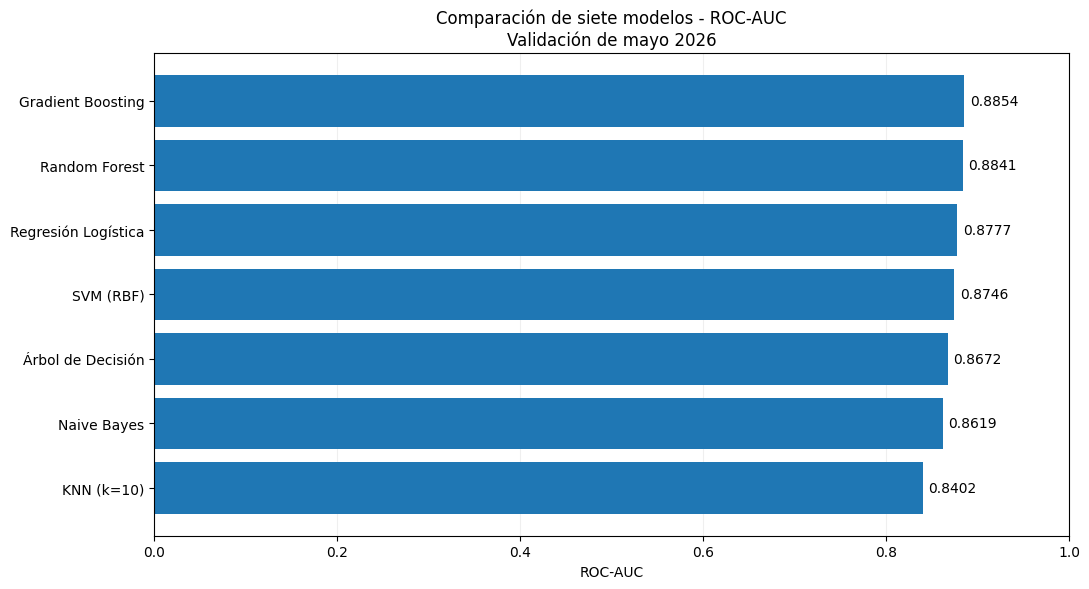

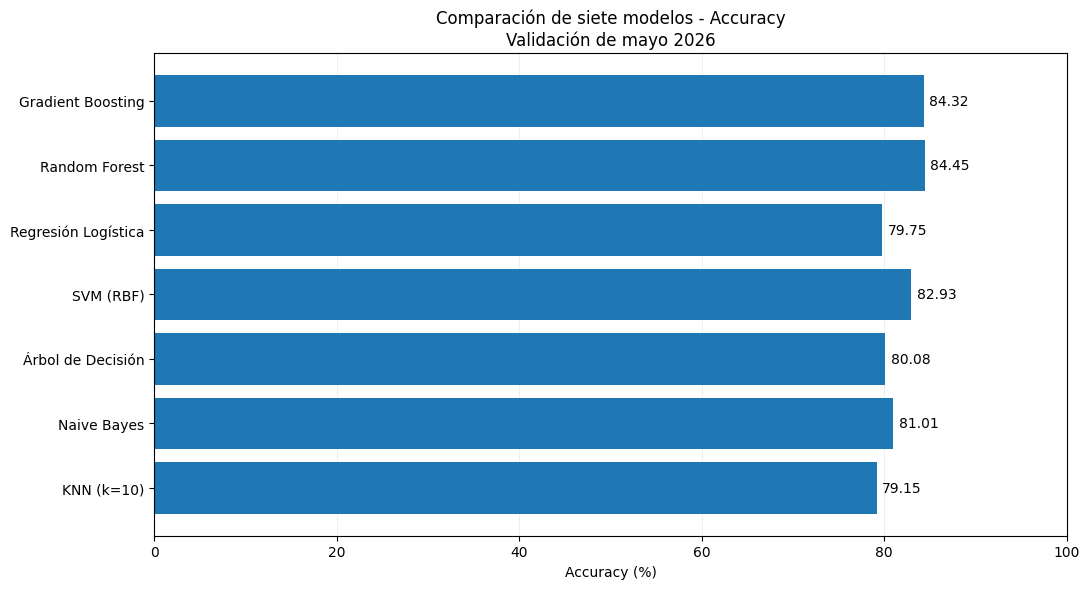


PASO 7 FINALIZADO
Algoritmos comparados: 7
Modelos seleccionados: 3

MODELOS SELECCIONADOS:
1. Gradient Boosting
2. Random Forest
3. Regresión Logística

Evidencias guardadas en:
c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\04_modelos\seleccion

Datos de junio utilizados: NO
Selección: PRELIMINAR
SQL Server: SIN MODIFICACIONES


In [17]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 7. SELECCIÓN DE LOS TRES MEJORES MODELOS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display


# ============================================================
# 1. VERIFICAR RESULTADOS DEL PASO 6
# ============================================================

if "tabla_comparativa" not in globals():
    raise RuntimeError(
        "Primero debes ejecutar el PASO 6."
    )

if "modelos_entrenados" not in globals():
    raise RuntimeError(
        "No se encontraron los modelos entrenados."
    )

if len(tabla_comparativa) != 7:
    raise ValueError(
        "Se requieren los siete modelos comparados."
    )

columnas_requeridas = [
    "Modelo",
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "ROC-AUC"
]

faltantes = set(columnas_requeridas) - set(
    tabla_comparativa.columns
)

if faltantes:
    raise ValueError(
        f"Faltan columnas: {sorted(faltantes)}"
    )


# ============================================================
# 2. ORDENAR MODELOS POR ROC-AUC
# ============================================================

ranking_modelos = (
    tabla_comparativa
    .sort_values(
        by="ROC-AUC",
        ascending=False
    )
    .reset_index(drop=True)
    .copy()
)

ranking_modelos.insert(
    0,
    "Posicion",
    range(1, len(ranking_modelos) + 1)
)

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("PASO 7. SELECCIÓN DE LOS TRES MEJORES")
print("=" * 70)

print("\n1. RANKING DE SIETE MODELOS")

display(
    ranking_modelos[
        [
            "Posicion",
            "Modelo",
            "Accuracy (%)",
            "Precision (%)",
            "Recall (%)",
            "ROC-AUC"
        ]
    ].round(4)
)


# ============================================================
# 3. SELECCIONAR LOS TRES PRIMEROS
# ============================================================

tabla_tres_modelos = (
    ranking_modelos
    .head(3)
    .copy()
    .reset_index(drop=True)
)

modelos_seleccionados = {}

for nombre in tabla_tres_modelos["Modelo"]:

    if nombre not in modelos_entrenados:
        raise KeyError(
            f"No se encontró el modelo: {nombre}"
        )

    modelos_seleccionados[nombre] = (
        modelos_entrenados[nombre]
    )

tabla_tres_modelos["Criterio_seleccion"] = (
    "Top 3 por ROC-AUC de validacion"
)

print("\n2. TRES MODELOS SELECCIONADOS")

display(
    tabla_tres_modelos[
        [
            "Posicion",
            "Modelo",
            "ROC-AUC",
            "Accuracy (%)",
            "Precision (%)",
            "Recall (%)"
        ]
    ].round(4)
)


# ============================================================
# 4. CREAR CARPETA DE EVIDENCIAS
# ============================================================

proyecto = Path.cwd()

carpeta_seleccion = (
    proyecto
    / "resultados"
    / "04_modelos"
    / "seleccion"
)

carpeta_seleccion.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 5. GRAFICO COMPARATIVO DE ROC-AUC
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 6)
)

barras = ax.barh(
    ranking_modelos["Modelo"],
    ranking_modelos["ROC-AUC"]
)

ax.invert_yaxis()

ax.set_xlim(0, 1)

ax.set_xlabel("ROC-AUC")

ax.set_title(
    "Comparación de siete modelos - ROC-AUC\n"
    "Validación de mayo 2026"
)

ax.bar_label(
    barras,
    fmt="%.4f",
    padding=4
)

ax.grid(
    axis="x",
    alpha=0.2
)

ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    carpeta_seleccion
    / "comparacion_roc_auc.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 6. GRAFICO COMPARATIVO DE ACCURACY
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 6)
)

barras = ax.barh(
    ranking_modelos["Modelo"],
    ranking_modelos["Accuracy (%)"]
)

ax.invert_yaxis()

ax.set_xlim(0, 100)

ax.set_xlabel("Accuracy (%)")

ax.set_title(
    "Comparación de siete modelos - Accuracy\n"
    "Validación de mayo 2026"
)

ax.bar_label(
    barras,
    fmt="%.2f",
    padding=4
)

ax.grid(
    axis="x",
    alpha=0.2
)

ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    carpeta_seleccion
    / "comparacion_accuracy.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 7. GUARDAR TABLAS
# ============================================================

ranking_modelos.to_csv(
    carpeta_seleccion
    / "ranking_siete_modelos.csv",
    index=False,
    encoding="utf-8-sig"
)

tabla_tres_modelos.to_csv(
    carpeta_seleccion
    / "tres_modelos_seleccionados.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 8. VERIFICACIONES
# ============================================================

assert len(ranking_modelos) == 7

assert len(tabla_tres_modelos) == 3

assert len(modelos_seleccionados) == 3

assert (
    tabla_tres_modelos["Modelo"].nunique() == 3
)

assert (
    tabla_tres_modelos["ROC-AUC"]
    .is_monotonic_decreasing
)

print("\n" + "=" * 70)
print("PASO 7 FINALIZADO")
print("=" * 70)

print("Algoritmos comparados: 7")
print("Modelos seleccionados: 3")

print("\nMODELOS SELECCIONADOS:")

for posicion, nombre in enumerate(
    modelos_seleccionados,
    start=1
):
    print(f"{posicion}. {nombre}")

print("\nEvidencias guardadas en:")
print(carpeta_seleccion)

print("\nDatos de junio utilizados: NO")
print("Selección: PRELIMINAR")
print("SQL Server: SIN MODIFICACIONES")



## PASO 8. Verificación de procedencia de variables predictoras

### Objetivo
Revisar cómo se construyó la variable citas_previas_perdidas y comprobar si utiliza información disponible antes de la fecha de cada cita médica.

### Justificación
Esta variable presenta una fuerte asociación con la inasistencia. Por tanto, es necesario verificar que no incorpore información futura que produzca una evaluación artificialmente elevada.

### Procedimiento
- Consultar la definición del objeto predictivo en SQL Server.
- Localizar los scripts SQL y Python que utilizan la variable.
- Revisar las expresiones de cálculo y las condiciones temporales.
- Documentar los hallazgos antes de la prueba final de los modelos.

### Alcance
Se realizará una revisión de solo lectura. No se entrenarán modelos nuevos ni se utilizará el conjunto de prueba de junio.


In [4]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 8. AUDITORÍA DE PROCEDENCIA TEMPORAL
# ============================================================

import os
import re
import pandas as pd

from pathlib import Path
from sqlalchemy import text
from IPython.display import display


# ============================================================
# 1. VERIFICAR ENTORNO
# ============================================================

if "engine" not in globals():
    raise RuntimeError(
        "Debes ejecutar primero la conexión SQL Server."
    )

proyecto = Path.cwd()

proyecto_anterior = (
    Path.home()
    / "Downloads"
    / "RedSaludCarazo_proyecto_base"
)

print("=" * 70)
print("PASO 8. AUDITORÍA DE PROCEDENCIA TEMPORAL")
print("=" * 70)


# ============================================================
# 2. VERIFICAR EL OBJETO SQL
# ============================================================

consulta_objeto = text("""
    SELECT
        o.name AS Nombre,
        o.type_desc AS Tipo,
        OBJECT_DEFINITION(o.object_id) AS Definicion
    FROM sys.objects AS o
    INNER JOIN sys.schemas AS s
        ON o.schema_id = s.schema_id
    WHERE s.name = 'dbo'
      AND o.name = 'dm_dataset_prediccion'
""")

with engine.connect() as conexion:
    objetos = pd.read_sql_query(
        consulta_objeto,
        conexion
    )

print("\n1. OBJETO PREDICTIVO EN SQL SERVER")

if objetos.empty:
    print("No se encontró el objeto esperado.")
else:
    print("Nombre:", objetos.iloc[0]["Nombre"])
    print("Tipo:", objetos.iloc[0]["Tipo"])

    definicion = objetos.iloc[0]["Definicion"]

    if pd.notna(definicion):
        print("\nDefinición SQL disponible:")
        print(str(definicion)[:6000])
    else:
        print(
            "\nNo existe una definición SELECT recuperable. "
            "Puede tratarse de una tabla física."
        )


# ============================================================
# 3. LOCALIZAR ARCHIVOS DE TRANSFORMACIÓN
# ============================================================

carpetas = [
    proyecto_anterior,
    proyecto
]

excluidas = {
    ".git",
    ".venv",
    "venv",
    "__pycache__",
    "node_modules",
    "site-packages",
    "resultados"
}

archivos = []
vistos = set()

for raiz in carpetas:

    if not raiz.is_dir():
        continue

    for carpeta, subcarpetas, nombres in os.walk(raiz):

        subcarpetas[:] = [
            nombre
            for nombre in subcarpetas
            if nombre not in excluidas
        ]

        for nombre in nombres:

            ruta = Path(carpeta) / nombre

            if ruta.suffix.lower() not in {".sql", ".py"}:
                continue

            ruta_resuelta = str(ruta.resolve())

            if ruta_resuelta not in vistos:
                vistos.add(ruta_resuelta)
                archivos.append(ruta)


# ============================================================
# 4. BUSCAR REFERENCIAS A LA VARIABLE
# ============================================================

patron = re.compile(
    r"citas_previas_perdidas",
    flags=re.IGNORECASE
)

coincidencias = []

for ruta in archivos:

    try:
        contenido = ruta.read_text(
            encoding="utf-8-sig",
            errors="replace"
        )
    except OSError:
        continue

    lineas = contenido.splitlines()

    for indice, linea in enumerate(lineas):

        if patron.search(linea):

            coincidencias.append({
                "Archivo": str(ruta),
                "Linea": indice + 1,
                "Texto": linea.strip(),
                "Inicio": max(0, indice - 6),
                "Fin": min(len(lineas), indice + 7),
                "Lineas": lineas
            })


# ============================================================
# 5. MOSTRAR HALLAZGOS
# ============================================================

print("\n2. BÚSQUEDA EN ARCHIVOS DEL PROYECTO")

print("Archivos SQL/Python revisados:", len(archivos))
print("Referencias encontradas:", len(coincidencias))

if coincidencias:

    tabla_referencias = pd.DataFrame([
        {
            "Archivo": item["Archivo"],
            "Linea": item["Linea"],
            "Texto": item["Texto"][:180]
        }
        for item in coincidencias
    ])

    display(tabla_referencias)

    print("\n3. FRAGMENTOS DE CÓDIGO ENCONTRADOS")

    for item in coincidencias[:12]:

        print("\n" + "-" * 65)
        print("Archivo:", item["Archivo"])
        print("Línea:", item["Linea"])

        for i in range(
            item["Inicio"],
            item["Fin"]
        ):
            print(
                f"{i + 1:04d}: {item['Lineas'][i]}"
            )

else:
    tabla_referencias = pd.DataFrame(
        columns=["Archivo", "Linea", "Texto"]
    )

    print(
        "No se encontró la variable en los "
        "archivos SQL/Python examinados."
    )


# ============================================================
# 6. GUARDAR EVIDENCIA
# ============================================================

carpeta_auditoria = (
    proyecto
    / "resultados"
    / "03_preparacion"
)

carpeta_auditoria.mkdir(
    parents=True,
    exist_ok=True
)

tabla_referencias.to_csv(
    carpeta_auditoria
    / "auditoria_procedencia_variable.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n" + "=" * 70)
print("PASO 8. REVISIÓN INICIAL FINALIZADA")
print("=" * 70)

print("SQL Server: SIN MODIFICACIONES")
print("Modelos entrenados adicionales: 0")
print("Datos de prueba de junio utilizados: NO")
print(
    "Verificación temporal: PENDIENTE DE "
    "INTERPRETAR EL CÓDIGO FUENTE"
)


PASO 8. AUDITORÍA DE PROCEDENCIA TEMPORAL

1. OBJETO PREDICTIVO EN SQL SERVER
Nombre: dm_dataset_prediccion
Tipo: USER_TABLE

No existe una definición SELECT recuperable. Puede tratarse de una tabla física.

2. BÚSQUEDA EN ARCHIVOS DEL PROYECTO
Archivos SQL/Python revisados: 13
Referencias encontradas: 27


,Archivo,Linea,Texto
0,C:\Users\Usuario\Downloads\RedSaludCarazo_proy...,18,"citas_previas_perdidas INT NULL,"
1,C:\Users\Usuario\Downloads\RedSaludCarazo_proy...,69,"citas_previas_perdidas INT NOT NULL,"
2,C:\Users\Usuario\Downloads\RedSaludCarazo_proy...,28,OR b.citas_previas_perdidas IS NULL
3,C:\Users\Usuario\Downloads\RedSaludCarazo_proy...,33,OR b.citas_previas_perdidas<0 OR b.costo_estim...
4,C:\Users\Usuario\Downloads\RedSaludCarazo_proy...,33,"tipo_cobertura,espera_dias,recordatorios_envia..."
5,C:\Users\Usuario\Downloads\RedSaludCarazo_proy...,37,"q.citas_previas_perdidas,q.costo_estimado_usd,..."
6,C:\Users\Usuario\Downloads\RedSaludCarazo_proy...,57,"h.citas_previas_perdidas,h.costo_estimado_usd,"
7,C:\Users\Usuario\Downloads\RedSaludCarazo_proy...,70,"citas_previas_perdidas,recordatorios_enviados,..."
8,C:\Users\Usuario\Downloads\RedSaludCarazo_proy...,30,"'citas_previas_perdidas',"
9,C:\Users\Usuario\Downloads\RedSaludCarazo_proy...,223,'citas_previas_perdidas'



3. FRAGMENTOS DE CÓDIGO ENCONTRADOS

-----------------------------------------------------------------
Archivo: C:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\RedSaludCarazo_proyecto_base\sql\01_crear_dw_v2.sql
Línea: 18
0012:     canal_agendamiento NVARCHAR(80) NULL,
0013:     grupo_edad NVARCHAR(30) NULL,
0014:     especialidad NVARCHAR(100) NULL,
0015:     costo_estimado_usd DECIMAL(12,2) NULL,
0016:     espera_dias INT NULL,
0017:     recordatorios_enviados INT NULL,
0018:     citas_previas_perdidas INT NULL,
0019:     tipo_cobertura NVARCHAR(50) NULL,
0020:     sistema_origen NVARCHAR(50) NULL,
0021:     no_asistio NVARCHAR(20) NULL,
0022:     consentimiento_contacto NVARCHAR(10) NULL,
0023:     fecha_carga DATE NULL,
0024:     fecha_ingesta DATETIME2 NOT NULL DEFAULT SYSUTCDATETIME()

-----------------------------------------------------------------
Archivo: C:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\RedSaludCarazo_proyecto_base\sql\01_crear_dw_v2.sql
Línea

In [5]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 8.1. IDENTIFICAR EL ORIGEN DE CITAS PREVIAS
# ============================================================

import os
import re
import pandas as pd

from pathlib import Path
from IPython.display import display


# ============================================================
# 1. DEFINIR CARPETAS
# ============================================================

proyecto = Path.cwd()

proyecto_anterior = (
    Path.home()
    / "Downloads"
    / "RedSaludCarazo_proyecto_base"
)

carpetas_busqueda = [
    proyecto_anterior,
    proyecto
]

carpetas_excluidas = {
    ".git",
    ".venv",
    "venv",
    "__pycache__",
    "node_modules",
    "resultados"
}


# ============================================================
# 2. LOCALIZAR ARCHIVOS QUE MENCIONAN LA VARIABLE
# ============================================================

patron_variable = re.compile(
    r"citas_previas_perdidas",
    flags=re.IGNORECASE
)

archivos_encontrados = []
rutas_revisadas = set()

for raiz in carpetas_busqueda:

    if not raiz.exists():
        continue

    for carpeta, subcarpetas, nombres in os.walk(raiz):

        subcarpetas[:] = [
            subcarpeta
            for subcarpeta in subcarpetas
            if subcarpeta not in carpetas_excluidas
        ]

        for nombre in nombres:

            ruta = Path(carpeta) / nombre

            if ruta.suffix.lower() not in {".sql", ".py"}:
                continue

            ruta_unica = str(ruta.resolve())

            if ruta_unica in rutas_revisadas:
                continue

            rutas_revisadas.add(ruta_unica)

            try:
                contenido = ruta.read_text(
                    encoding="utf-8-sig",
                    errors="replace"
                )
            except OSError:
                continue

            coincidencias = list(
                patron_variable.finditer(contenido)
            )

            if not coincidencias:
                continue

            # Priorizar scripts de carga y transformación.
            nombre_minusculas = ruta.name.lower()

            prioridad = (
                0 if any(
                    palabra in nombre_minusculas
                    for palabra in [
                        "carga",
                        "gener",
                        "etl",
                        "seed",
                        "insert",
                        "calidad",
                        "transform"
                    ]
                )
                else 1
            )

            archivos_encontrados.append({
                "Archivo": ruta.name,
                "Ruta": str(ruta),
                "Tipo": ruta.suffix.lower(),
                "Referencias": len(coincidencias),
                "Prioridad": prioridad
            })


# ============================================================
# 3. MOSTRAR ARCHIVOS ENCONTRADOS
# ============================================================

tabla_origen = pd.DataFrame(
    archivos_encontrados
)

print("=" * 70)
print("PASO 8.1. ORIGEN DE CITAS PREVIAS PERDIDAS")
print("=" * 70)

if tabla_origen.empty:
    print("No se encontraron archivos relevantes.")

else:

    tabla_origen = (
        tabla_origen
        .sort_values(
            ["Prioridad", "Archivo"]
        )
        .reset_index(drop=True)
    )

    print("\n1. ARCHIVOS QUE UTILIZAN LA VARIABLE")

    display(
        tabla_origen[
            [
                "Archivo",
                "Tipo",
                "Referencias",
                "Ruta"
            ]
        ]
    )

    print("\n2. RUTAS COMPLETAS")

    for i, fila in tabla_origen.iterrows():

        print(f"\n{i + 1}. {fila['Archivo']}")
        print(f"   {fila['Ruta']}")
        print(f"   Referencias: {fila['Referencias']}")


# ============================================================
# 4. BUSCAR POSIBLES OPERACIONES DE CARGA
# ============================================================

print("\n3. ARCHIVOS QUE PODRÍAN CONSTRUIR EL DATASET")

patron_carga = re.compile(
    r"INSERT\s+INTO"
    r"|UPDATE\s+"
    r"|read_csv"
    r"|to_sql"
    r"|to_csv"
    r"|executemany"
    r"|dm_dataset_prediccion"
    r"|raw_cita",
    flags=re.IGNORECASE
)

if not tabla_origen.empty:

    for _, fila in tabla_origen.iterrows():

        ruta = Path(fila["Ruta"])

        contenido = ruta.read_text(
            encoding="utf-8-sig",
            errors="replace"
        )

        lineas = contenido.splitlines()

        operaciones = [
            numero
            for numero, linea in enumerate(lineas, start=1)
            if patron_carga.search(linea)
        ]

        if operaciones:

            print("\nARCHIVO:", fila["Archivo"])

            for numero in operaciones[:6]:

                print(
                    f"  Línea {numero}: "
                    f"{lineas[numero - 1].strip()[:140]}"
                )


# ============================================================
# 5. GUARDAR EVIDENCIA
# ============================================================

carpeta_auditoria = (
    proyecto
    / "resultados"
    / "03_preparacion"
)

carpeta_auditoria.mkdir(
    parents=True,
    exist_ok=True
)

tabla_origen.to_csv(
    carpeta_auditoria
    / "archivos_origen_citas_previas.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n" + "=" * 70)
print("PASO 8.1 FINALIZADO")
print("=" * 70)

print("Archivos identificados:", len(tabla_origen))
print("SQL Server: SIN MODIFICACIONES")
print("Modelos entrenados adicionales: 0")
print("Prueba de junio realizada: NO")


PASO 8.1. ORIGEN DE CITAS PREVIAS PERDIDAS

1. ARCHIVOS QUE UTILIZAN LA VARIABLE


,Archivo,Tipo,Referencias,Ruta
0,01_cargar_excel.py,.py,2,C:\Users\Usuario\Downloads\RedSaludCarazo_proy...
1,02_calidad_v2.sql,.sql,2,C:\Users\Usuario\Downloads\RedSaludCarazo_proy...
2,validador_calidad.py,.py,5,C:\Users\Usuario\Downloads\RedSaludCarazo_proy...
3,01_crear_dw_v2.sql,.sql,2,C:\Users\Usuario\Downloads\RedSaludCarazo_proy...
4,03_comparacion_modelos.py,.py,1,C:\Users\Usuario\Downloads\RedSaludCarazo_proy...
5,03_dataset_v2.sql,.sql,4,C:\Users\Usuario\Downloads\RedSaludCarazo_proy...
6,03_modelado.py,.py,1,C:\Users\Usuario\Downloads\RedSaludCarazo_proy...
7,03_modelado_v3_random_forest.py,.py,1,C:\Users\Usuario\Downloads\RedSaludCarazo_proy...
8,04_modelo_final_gradient_boosting.py,.py,1,C:\Users\Usuario\Downloads\RedSaludCarazo_proy...
9,05_analisis_factores_inasistencia.py,.py,6,C:\Users\Usuario\Downloads\RedSaludCarazo_proy...



2. RUTAS COMPLETAS

1. 01_cargar_excel.py
   C:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\src\01_cargar_excel.py
   Referencias: 2

2. 02_calidad_v2.sql
   C:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\RedSaludCarazo_proyecto_base\sql\02_calidad_v2.sql
   Referencias: 2

3. validador_calidad.py
   C:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\src\validador_calidad.py
   Referencias: 5

4. 01_crear_dw_v2.sql
   C:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\RedSaludCarazo_proyecto_base\sql\01_crear_dw_v2.sql
   Referencias: 2

5. 03_comparacion_modelos.py
   C:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\src\03_comparacion_modelos.py
   Referencias: 1

6. 03_dataset_v2.sql
   C:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\RedSaludCarazo_proyecto_base\sql\03_dataset_v2.sql
   Referencias: 4

7. 03_modelado.py
   C:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\src\03_modelado.py
   Referencias: 1

8. 03_modelado_v3_random_


## PASO 8.2. Revisión de la procedencia de citas_previas_perdidas

### Objetivo
Examinar los scripts responsables de cargar, validar y construir el dataset predictivo, con especial atención a la variable citas_previas_perdidas.

### Archivos por revisar
- 01_cargar_excel.py
- 02_calidad_v2.sql
- 03_dataset_v2.sql

### Criterio de revisión
Identificar si la variable se calcula a partir del historial de citas anteriores, se importa directamente desde una fuente o se obtiene mediante alguna transformación adicional.

### Resultado esperado
Documentar la procedencia identificada y determinar qué evidencia adicional se necesita para descartar fuga de información temporal.


In [6]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 8.2. REVISIÓN DE SCRIPTS DE ORIGEN
# ============================================================

from pathlib import Path
import re
from IPython.display import display
import pandas as pd


# ============================================================
# 1. LOCALIZAR PROYECTO ANTERIOR
# ============================================================

raiz = (
    Path.home()
    / "Downloads"
    / "RedSaludCarazo_proyecto_base"
)

archivos_objetivo = [
    "01_cargar_excel.py",
    "02_calidad_v2.sql",
    "03_dataset_v2.sql"
]

if not raiz.exists():
    raise FileNotFoundError(
        f"No se encontró el proyecto: {raiz}"
    )


# ============================================================
# 2. DEFINIR EXPRESIONES RELEVANTES
# ============================================================

patron = re.compile(
    r"citas_previas_perdidas"
    r"|dm_dataset_prediccion"
    r"|raw_cita"
    r"|INSERT\s+INTO"
    r"|SELECT\b"
    r"|read_excel"
    r"|read_csv"
    r"|to_sql"
    r"|fecha_cita"
    r"|id_paciente"
    r"|fecha_agendamiento",
    flags=re.IGNORECASE
)


# ============================================================
# 3. LEER ARCHIVOS
# ============================================================

print("=" * 70)
print("PASO 8.2. PROCEDENCIA DE CITAS PREVIAS PERDIDAS")
print("=" * 70)

resumen_archivos = []

for nombre in archivos_objetivo:

    encontrados = sorted(
        raiz.rglob(nombre),
        key=lambda ruta: (len(ruta.parts), str(ruta))
    )

    print("\n" + "=" * 70)
    print("ARCHIVO:", nombre)
    print("=" * 70)

    if not encontrados:

        print("NO ENCONTRADO")

        resumen_archivos.append({
            "Archivo": nombre,
            "Estado": "NO ENCONTRADO",
            "Coincidencias": 0
        })

        continue

    ruta = encontrados[0]

    print("Ubicación:", ruta)

    lineas = ruta.read_text(
        encoding="utf-8-sig",
        errors="replace"
    ).splitlines()

    coincidencias = [
        indice
        for indice, linea in enumerate(lineas)
        if patron.search(linea)
    ]

    resumen_archivos.append({
        "Archivo": nombre,
        "Estado": "ENCONTRADO",
        "Coincidencias": len(coincidencias)
    })

    print("Total de líneas:", len(lineas))
    print("Referencias relevantes:", len(coincidencias))

    # Unir intervalos cercanos para evitar
    # mostrar varias veces las mismas líneas.

    intervalos = []

    for indice in coincidencias:

        inicio = max(0, indice - 5)
        fin = min(len(lineas), indice + 9)

        if intervalos and inicio <= intervalos[-1][1]:

            anterior_inicio, anterior_fin = intervalos[-1]

            intervalos[-1] = (
                anterior_inicio,
                max(anterior_fin, fin)
            )

        else:

            intervalos.append((inicio, fin))

    print("\nFRAGMENTOS RELEVANTES:")

    # Limitar salida para evitar truncamiento.
    for inicio, fin in intervalos[:6]:

        print("\n" + "-" * 55)

        for indice in range(inicio, fin):

            print(
                f"{indice + 1:04d}: {lineas[indice]}"
            )

    if len(intervalos) > 6:

        print(
            f"\nSe omitieron "
            f"{len(intervalos) - 6} fragmentos "
            "para evitar una salida demasiado extensa."
        )


# ============================================================
# 4. MOSTRAR RESUMEN
# ============================================================

tabla_revision = pd.DataFrame(
    resumen_archivos
)

print("\n" + "=" * 70)
print("RESUMEN DE ARCHIVOS REVISADOS")
print("=" * 70)

display(tabla_revision)


# ============================================================
# 5. GUARDAR EVIDENCIA
# ============================================================

proyecto = Path.cwd()

carpeta = (
    proyecto
    / "resultados"
    / "03_preparacion"
)

carpeta.mkdir(
    parents=True,
    exist_ok=True
)

tabla_revision.to_csv(
    carpeta / "revision_scripts_origen.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nPASO 8.2 FINALIZADO")
print("SQL Server: SIN MODIFICACIONES")
print("Datos de junio evaluados: NO")
print("Modelos adicionales entrenados: 0")


PASO 8.2. PROCEDENCIA DE CITAS PREVIAS PERDIDAS

ARCHIVO: 01_cargar_excel.py
Ubicación: C:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\src\01_cargar_excel.py
Total de líneas: 378
Referencias relevantes: 12

FRAGMENTOS RELEVANTES:

-------------------------------------------------------
0017: # 1. COLUMNAS DEL DATASET
0018: # ============================================================
0019: 
0020: COLS = [
0021:     'id_cita',
0022:     'fecha_cita',
0023:     'centro_salud',
0024:     'canal_agendamiento',
0025:     'grupo_edad',
0026:     'especialidad',
0027:     'costo_estimado_usd',
0028:     'espera_dias',
0029:     'recordatorios_enviados',
0030:     'citas_previas_perdidas',
0031:     'tipo_cobertura',
0032:     'sistema_origen',
0033:     'no_asistio',
0034:     'consentimiento_contacto',
0035:     'fecha_carga'
0036: ]
0037: 
0038: 

-------------------------------------------------------
0137:     # PASO 3: Leer Excel
0138:     # ------------------------------------

,Archivo,Estado,Coincidencias
0,01_cargar_excel.py,ENCONTRADO,12
1,02_calidad_v2.sql,ENCONTRADO,9
2,03_dataset_v2.sql,ENCONTRADO,32



PASO 8.2 FINALIZADO
SQL Server: SIN MODIFICACIONES
Datos de junio evaluados: NO
Modelos adicionales entrenados: 0


In [7]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 8.3. REVISIÓN DETALLADA DE PROCEDENCIA
# ============================================================

import re
from pathlib import Path

# ============================================================
# 1. LOCALIZAR LOS ARCHIVOS
# ============================================================

raiz = (
    Path.home()
    / "Downloads"
    / "RedSaludCarazo_proyecto_base"
)

archivos = [
    "01_cargar_excel.py",
    "03_dataset_v2.sql"
]

patron = re.compile(
    r"citas_previas_perdidas"
    r"|read_excel"
    r"|read_csv"
    r"|INSERT\s+INTO"
    r"|SELECT\b"
    r"|dm_dataset_prediccion"
    r"|raw_cita",
    flags=re.IGNORECASE
)

print("=" * 70)
print("PASO 8.3. REVISIÓN DETALLADA DE PROCEDENCIA")
print("=" * 70)

# ============================================================
# 2. EXAMINAR LOS ARCHIVOS
# ============================================================

for nombre in archivos:

    encontrados = list(raiz.rglob(nombre))

    if not encontrados:
        print(f"\nNO ENCONTRADO: {nombre}")
        continue

    ruta = encontrados[0]

    lineas = ruta.read_text(
        encoding="utf-8-sig",
        errors="replace"
    ).splitlines()

    print("\n" + "=" * 70)
    print("ARCHIVO:", nombre)
    print("RUTA:", ruta)
    print("LÍNEAS TOTALES:", len(lineas))
    print("=" * 70)

    coincidencias = [
        i
        for i, linea in enumerate(lineas)
        if patron.search(linea)
    ]

    # Mostrar contextos, evitando repetir líneas
    mostrar = set()

    for i in coincidencias:

        inicio = max(0, i - 5)
        fin = min(len(lineas), i + 9)

        for j in range(inicio, fin):
            mostrar.add(j)

    # Limitar la visualización
    limite = 130 if nombre.endswith(".sql") else 85

    print("\nFRAGMENTOS IDENTIFICADOS:\n")

    for j in sorted(mostrar)[:limite]:
        print(f"{j + 1:04d}: {lineas[j]}")

    if len(mostrar) > limite:
        print(
            f"\nSe omitieron {len(mostrar) - limite} "
            "líneas de contexto."
        )

print("\n" + "=" * 70)
print("PASO 8.3 FINALIZADO")
print("=" * 70)

print("Archivos examinados sin modificaciones.")
print("SQL Server: SIN MODIFICACIONES")
print("Modelos seleccionados: SE CONSERVAN LOS TRES")
print("Evaluación de junio: NO REALIZADA")


PASO 8.3. REVISIÓN DETALLADA DE PROCEDENCIA

ARCHIVO: 01_cargar_excel.py
RUTA: C:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\src\01_cargar_excel.py
LÍNEAS TOTALES: 378

FRAGMENTOS IDENTIFICADOS:

0025:     'grupo_edad',
0026:     'especialidad',
0027:     'costo_estimado_usd',
0028:     'espera_dias',
0029:     'recordatorios_enviados',
0030:     'citas_previas_perdidas',
0031:     'tipo_cobertura',
0032:     'sistema_origen',
0033:     'no_asistio',
0034:     'consentimiento_contacto',
0035:     'fecha_carga'
0036: ]
0037: 
0038: 
0137:     # PASO 3: Leer Excel
0138:     # --------------------------------------------------------
0139: 
0140:     print("\nLeyendo archivo Excel...")
0141: 
0142:     df = pd.read_excel(
0143:         ruta,
0144:         sheet_name='C02_Citas',
0145:         dtype={
0146:             'id_cita': str
0147:         }
0148:     )
0149: 
0150:     print(
0218:     print("\nPreparando columnas numéricas...")
0219: 
0220:     columnas_enteras = [
0221:

In [8]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 8.4. REGISTRO DE AUDITORÍA DE PROCEDENCIA
# ============================================================

import pandas as pd
from pathlib import Path
from IPython.display import display

proyecto = Path.cwd()

carpeta_auditoria = (
    proyecto
    / "resultados"
    / "03_preparacion"
)

carpeta_auditoria.mkdir(
    parents=True,
    exist_ok=True
)

# ============================================================
# 1. DOCUMENTAR HALLAZGOS
# ============================================================

hallazgos = [
    {
        "Control": "Fuente de la variable",
        "Evidencia": (
            "01_cargar_excel.py lee la hoja C02_Citas "
            "del archivo Excel."
        ),
        "Resultado": "IDENTIFICADO"
    },
    {
        "Control": "Preparación en Python",
        "Evidencia": (
            "citas_previas_perdidas se convierte "
            "a número entero."
        ),
        "Resultado": "VERIFICADO"
    },
    {
        "Control": "Transformación SQL",
        "Evidencia": (
            "03_dataset_v2.sql transporta la variable "
            "desde hecho_cita hacia el dataset predictivo."
        ),
        "Resultado": "VERIFICADO"
    },
    {
        "Control": "Cálculo histórico",
        "Evidencia": (
            "Los scripts revisados no muestran "
            "el cálculo de antecedentes por paciente."
        ),
        "Resultado": "NO DEMOSTRADO"
    },
    {
        "Control": "Disponibilidad temporal",
        "Evidencia": (
            "No se ha documentado cuándo se calculó "
            "originalmente el valor del Excel."
        ),
        "Resultado": "PENDIENTE"
    },
    {
        "Control": "Ausencia de fuga temporal",
        "Evidencia": (
            "La procedencia del valor está identificada, "
            "pero su validez temporal no está acreditada."
        ),
        "Resultado": "NO VERIFICADA"
    }
]

tabla_auditoria_temporal = pd.DataFrame(
    hallazgos
)

# ============================================================
# 2. MOSTRAR RESULTADOS
# ============================================================

print("=" * 70)
print("PASO 8.4. AUDITORÍA DE PROCEDENCIA")
print("=" * 70)

display(tabla_auditoria_temporal)

# ============================================================
# 3. GUARDAR EVIDENCIAS
# ============================================================

ruta_evidencia = (
    carpeta_auditoria
    / "auditoria_temporal_citas_previas.csv"
)

tabla_auditoria_temporal.to_csv(
    ruta_evidencia,
    index=False,
    encoding="utf-8-sig"
)

print("\nPASO 8.4 FINALIZADO")
print("Evidencia guardada en:", ruta_evidencia)
print("Procedencia desde Excel: IDENTIFICADA")
print("Validez temporal: NO VERIFICADA")
print("SQL Server: SIN MODIFICACIONES")
print("Modelos seleccionados: SE CONSERVAN LOS TRES")
print("Prueba final de junio: NO REALIZADA")


PASO 8.4. AUDITORÍA DE PROCEDENCIA


,Control,Evidencia,Resultado
0,Fuente de la variable,01_cargar_excel.py lee la hoja C02_Citas del a...,IDENTIFICADO
1,Preparación en Python,citas_previas_perdidas se convierte a número e...,VERIFICADO
2,Transformación SQL,03_dataset_v2.sql transporta la variable desde...,VERIFICADO
3,Cálculo histórico,Los scripts revisados no muestran el cálculo d...,NO DEMOSTRADO
4,Disponibilidad temporal,No se ha documentado cuándo se calculó origina...,PENDIENTE
5,Ausencia de fuga temporal,"La procedencia del valor está identificada, pe...",NO VERIFICADA



PASO 8.4 FINALIZADO
Evidencia guardada en: c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\03_preparacion\auditoria_temporal_citas_previas.csv
Procedencia desde Excel: IDENTIFICADA
Validez temporal: NO VERIFICADA
SQL Server: SIN MODIFICACIONES
Modelos seleccionados: SE CONSERVAN LOS TRES
Prueba final de junio: NO REALIZADA



## PASO 9. Programación de los KPI de Minería de Datos

### Objetivo
Programar y evaluar dos indicadores de rendimiento predictivo para los tres modelos seleccionados mediante la comparación de siete algoritmos.

### KPI-M01. Capacidad de discriminación (ROC-AUC)
Mide la capacidad del modelo para distinguir entre citas con asistencia y citas con inasistencia a partir de sus probabilidades predictivas.

Fórmula: área bajo la curva ROC.

Interpretación: un valor más cercano a 1 indica mayor capacidad de discriminación.

### KPI-M02. Detección de inasistencias (Recall)
Mide la proporción de inasistencias reales que el modelo identifica correctamente.

Fórmula:

Recall (%) = VP / (VP + FN) × 100

Donde:
- VP: inasistencias correctamente identificadas.
- FN: inasistencias que el modelo no detectó.

### Metodología
- Modelos: Gradient Boosting, Random Forest y Regresión Logística, según la selección de validación.
- Entrenamiento original: enero a abril de 2026.
- Período de evaluación de KPI: mayo de 2026.
- Umbral para Recall: 0.50.
- Junio se reserva para evaluación final.

### Evidencia
Se registrarán valores de los KPI, matrices de confusión, métricas complementarias y predicciones individuales.

### Limitación
La disponibilidad temporal de citas_previas_perdidas no está acreditada, por lo que los resultados conservan carácter experimental.


In [18]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 9. PROGRAMACIÓN DE DOS KPI DE MINERÍA
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)


# ============================================================
# 1. VERIFICAR LOS MODELOS Y DATOS
# ============================================================

necesarios = [
    "modelos_seleccionados",
    "tabla_tres_modelos",
    "X_val",
    "y_val",
    "val",
    "UMBRAL"
]

faltantes = [
    variable
    for variable in necesarios
    if variable not in globals()
]

if faltantes:
    raise RuntimeError(
        "Faltan variables de pasos anteriores: "
        f"{faltantes}"
    )

if len(modelos_seleccionados) != 3:
    raise ValueError(
        "Se requieren tres modelos seleccionados."
    )

if len(X_val) != len(y_val):
    raise ValueError(
        "No coinciden X_val e y_val."
    )

if len(X_val) != len(val):
    raise ValueError(
        "No coincide la validación con sus registros."
    )

if not set(y_val.unique()) == {0, 1}:
    raise ValueError(
        "La variable objetivo debe contener 0 y 1."
    )

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("PASO 9. KPI DE MINERÍA DE DATOS")
print("=" * 70)

print("\nRegistros de validación:", len(X_val))
print("Modelos seleccionados:", len(modelos_seleccionados))
print("Período: mayo de 2026")
print("Umbral:", UMBRAL)


# ============================================================
# 2. DEFINIR Y PROGRAMAR LOS DOS KPI
# ============================================================

def calcular_kpi_mineria(
    valores_reales,
    probabilidades,
    umbral=0.50
):

    predicciones = (
        probabilidades >= umbral
    ).astype(int)

    # KPI-M01: área bajo la curva ROC
    kpi_roc_auc = roc_auc_score(
        valores_reales,
        probabilidades
    )

    # KPI-M02: detección de inasistencias
    kpi_recall = recall_score(
        valores_reales,
        predicciones,
        zero_division=0
    ) * 100

    return (
        kpi_roc_auc,
        kpi_recall,
        predicciones
    )


# ============================================================
# 3. EVALUAR LOS TRES MODELOS
# ============================================================

resultados_kpi_mineria = []
auditoria_predicciones_kpi = []

for nombre, modelo in modelos_seleccionados.items():

    print("\nEvaluando KPI del modelo:", nombre)

    # Obtener probabilidades de no_asistio = 1
    clases = list(modelo.classes_)

    if 1 not in clases:
        raise ValueError(
            f"El modelo {nombre} no tiene clase positiva 1."
        )

    indice_positivo = clases.index(1)

    probabilidades = (
        modelo.predict_proba(X_val)[
            :, indice_positivo
        ]
    )

    # Calcular los dos KPI
    roc_auc, recall, predicciones = (
        calcular_kpi_mineria(
            y_val,
            probabilidades,
            umbral=UMBRAL
        )
    )

    # Matriz de confusión
    vn, fp, fn, vp = confusion_matrix(
        y_val,
        predicciones,
        labels=[0, 1]
    ).ravel()

    # Métricas complementarias
    accuracy = accuracy_score(
        y_val,
        predicciones
    ) * 100

    precision = precision_score(
        y_val,
        predicciones,
        zero_division=0
    ) * 100

    f1 = f1_score(
        y_val,
        predicciones,
        zero_division=0
    ) * 100

    f2 = fbeta_score(
        y_val,
        predicciones,
        beta=2,
        zero_division=0
    ) * 100

    pr_auc = average_precision_score(
        y_val,
        probabilidades
    )

    # Guardar resultados calculados
    resultados_kpi_mineria.append({

        "Modelo": nombre,

        "KPI_M01_ROC_AUC": roc_auc,

        "KPI_M02_Recall_pct": recall,

        "Accuracy_pct": accuracy,

        "Precision_pct": precision,

        "F1_pct": f1,

        "F2_pct": f2,

        "PR_AUC_AP": pr_auc,

        "VP": int(vp),
        "VN": int(vn),
        "FP": int(fp),
        "FN": int(fn),

        "Registros_evaluados": len(y_val),

        "Periodo": "2026-05",

        "Umbral": UMBRAL,

        "Validez_temporal": "NO VERIFICADA"
    })

    # Guardar predicciones para auditoría
    detalle = pd.DataFrame({

        "id_cita": val["id_cita"].to_numpy(),

        "fecha_cita": val["fecha_cita"].to_numpy(),

        "Modelo": nombre,

        "Valor_real": y_val.to_numpy(),

        "Prediccion": predicciones,

        "Probabilidad_inasistencia": probabilidades
    })

    auditoria_predicciones_kpi.append(
        detalle
    )


# ============================================================
# 4. CONSOLIDAR RESULTADOS
# ============================================================

tabla_kpi_mineria = pd.DataFrame(
    resultados_kpi_mineria
)

detalle_kpi_mineria = pd.concat(
    auditoria_predicciones_kpi,
    ignore_index=True
)


# ============================================================
# 5. MOSTRAR LOS DOS KPI PRINCIPALES
# ============================================================

print("\n" + "=" * 70)
print("1. RESULTADOS DE KPI DE MINERÍA")
print("=" * 70)

display(
    tabla_kpi_mineria[
        [
            "Modelo",
            "KPI_M01_ROC_AUC",
            "KPI_M02_Recall_pct"
        ]
    ].round(4)
)


# ============================================================
# 6. MOSTRAR MÉTRICAS COMPLEMENTARIAS
# ============================================================

print("\n2. MÉTRICAS COMPLEMENTARIAS")

display(
    tabla_kpi_mineria[
        [
            "Modelo",
            "Accuracy_pct",
            "Precision_pct",
            "F1_pct",
            "F2_pct",
            "PR_AUC_AP"
        ]
    ].round(4)
)


# ============================================================
# 7. MOSTRAR MATRICES DE CONFUSIÓN
# ============================================================

print("\n3. MATRICES DE CONFUSIÓN")

display(
    tabla_kpi_mineria[
        [
            "Modelo",
            "VP",
            "VN",
            "FP",
            "FN"
        ]
    ]
)


# ============================================================
# 8. VERIFICAR CONSISTENCIA CON EL PASO 7
# ============================================================

referencia = tabla_tres_modelos.set_index(
    "Modelo"
)

for _, fila in tabla_kpi_mineria.iterrows():

    nombre = fila["Modelo"]

    if nombre not in referencia.index:
        raise ValueError(
            f"Modelo desconocido: {nombre}"
        )

    roc_anterior = float(
        referencia.loc[
            nombre,
            "ROC-AUC"
        ]
    )

    recall_anterior = float(
        referencia.loc[
            nombre,
            "Recall (%)"
        ]
    )

    if not np.isclose(
        fila["KPI_M01_ROC_AUC"],
        roc_anterior,
        atol=0.00015
    ):
        raise ValueError(
            f"El ROC-AUC de {nombre} no coincide "
            "con el PASO 7."
        )

    if not np.isclose(
        fila["KPI_M02_Recall_pct"],
        recall_anterior,
        atol=0.00015
    ):
        raise ValueError(
            f"El Recall de {nombre} no coincide "
            "con el PASO 7."
        )

    total_matriz = int(
        fila["VP"]
        + fila["VN"]
        + fila["FP"]
        + fila["FN"]
    )

    assert total_matriz == len(y_val)


# ============================================================
# 9. CREAR DICCIONARIO DE KPI
# ============================================================

diccionario_kpi_mineria = pd.DataFrame([

    {
        "Codigo": "KPI-M01",
        "Indicador": "ROC-AUC",
        "Unidad": "Índice de 0 a 1",
        "Formula": "Área bajo la curva ROC",
        "Objetivo": (
            "Medir capacidad de discriminación "
            "entre asistencia e inasistencia"
        ),
        "Periodo": "Mayo 2026"
    },

    {
        "Codigo": "KPI-M02",
        "Indicador": "Recall",
        "Unidad": "Porcentaje",
        "Formula": "VP / (VP + FN) * 100",
        "Objetivo": (
            "Medir el porcentaje de "
            "inasistencias reales detectadas"
        ),
        "Periodo": "Mayo 2026"
    }

])

print("\n4. DICCIONARIO DE LOS DOS KPI")

display(diccionario_kpi_mineria)


# ============================================================
# 10. GUARDAR EVIDENCIAS
# ============================================================

proyecto = Path.cwd()

carpeta_kpi = (
    proyecto
    / "resultados"
    / "05_kpi"
)

carpeta_kpi.mkdir(
    parents=True,
    exist_ok=True
)

tabla_kpi_mineria.to_csv(
    carpeta_kpi / "kpi_mineria_validacion_mayo.csv",
    index=False,
    encoding="utf-8-sig"
)

diccionario_kpi_mineria.to_csv(
    carpeta_kpi / "diccionario_kpi_mineria.csv",
    index=False,
    encoding="utf-8-sig"
)

detalle_kpi_mineria.to_csv(
    carpeta_kpi / "auditoria_kpi_mineria_mayo.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 11. CONFIRMAR RESULTADOS
# ============================================================

assert len(tabla_kpi_mineria) == 3

assert len(diccionario_kpi_mineria) == 2

assert len(detalle_kpi_mineria) == (
    len(X_val) * 3
)

print("\n" + "=" * 70)
print("PASO 9 FINALIZADO")
print("=" * 70)

print("Modelos evaluados:", len(tabla_kpi_mineria))
print("KPI de minería programados: 2")
print(
    "Predicciones auditables:",
    len(detalle_kpi_mineria)
)

print("\nEvidencias guardadas en:")
print(carpeta_kpi)

print("\nModelos reentrenados: NO")
print("Prueba de junio realizada: NO")
print("SQL Server: SIN MODIFICACIONES")
print("Validez temporal: PENDIENTE DE ACREDITAR")


RED SALUD INTEGRAL CARAZO
PASO 9. KPI DE MINERÍA DE DATOS

Registros de validación: 1511
Modelos seleccionados: 3
Período: mayo de 2026
Umbral: 0.5

Evaluando KPI del modelo: Gradient Boosting

Evaluando KPI del modelo: Random Forest

Evaluando KPI del modelo: Regresión Logística

1. RESULTADOS DE KPI DE MINERÍA


,Modelo,KPI_M01_ROC_AUC,KPI_M02_Recall_pct
0,Gradient Boosting,0.8854,70.8929
1,Random Forest,0.8841,70.8929
2,Regresión Logística,0.8777,80.1786



2. MÉTRICAS COMPLEMENTARIAS


,Modelo,Accuracy_pct,Precision_pct,F1_pct,F2_pct,PR_AUC_AP
0,Gradient Boosting,84.3150,84.2887,77.0126,73.2202,0.8411
1,Random Forest,84.4474,84.6482,77.1623,73.2743,0.8371
2,Regresión Logística,79.7485,69.7205,74.5847,77.8433,0.8309



3. MATRICES DE CONFUSIÓN


,Modelo,VP,VN,FP,FN
0,Gradient Boosting,397,877,74,163
1,Random Forest,397,879,72,163
2,Regresión Logística,449,756,195,111



4. DICCIONARIO DE LOS DOS KPI


,Codigo,Indicador,Unidad,Formula,Objetivo,Periodo
0,KPI-M01,ROC-AUC,Índice de 0 a 1,Área bajo la curva ROC,Medir capacidad de discriminación entre asiste...,Mayo 2026
1,KPI-M02,Recall,Porcentaje,VP / (VP + FN) * 100,Medir el porcentaje de inasistencias reales de...,Mayo 2026



PASO 9 FINALIZADO
Modelos evaluados: 3
KPI de minería programados: 2
Predicciones auditables: 4533

Evidencias guardadas en:
c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\05_kpi

Modelos reentrenados: NO
Prueba de junio realizada: NO
SQL Server: SIN MODIFICACIONES
Validez temporal: PENDIENTE DE ACREDITAR



## PASO 10. KPI-C01: Completitud de registros predictivos

### Objetivo
Medir el porcentaje de registros del dataset predictivo que contienen información en todos los campos requeridos.

### Definición del indicador
- Código: KPI-C01.
- Área: Calidad de Datos.
- Nombre: Completitud de registros predictivos.
- Unidad: Porcentaje.
- Fuente: dbo.dm_dataset_prediccion.

### Fórmula
Completitud (%) = (Registros completos / Total de registros evaluados) × 100

### Criterios de evaluación
Un registro se considera completo cuando sus campos no contienen valores NULL ni cadenas vacías.

El indicador evalúa la completitud de los 13 campos originales del dataset predictivo.

### Consideración
Un resultado de 100 % demuestra completitud en el conjunto predictivo evaluado, pero no demuestra que todos los registros de la fuente original hayan superado los controles de calidad ni que estén libres de errores de dominio o fuga temporal.


In [19]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS Y CALIDAD DE DATOS
# PASO 10. PROGRAMACIÓN DEL KPI DE CALIDAD
# ============================================================

import pandas as pd

from pathlib import Path
from sqlalchemy import text
from IPython.display import display


# ============================================================
# 1. VERIFICAR CONEXIÓN
# ============================================================

if "engine" not in globals():
    raise RuntimeError(
        "Primero debes ejecutar el PASO 1."
    )

proyecto = Path.cwd()

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("PASO 10. KPI DE CALIDAD DE DATOS")
print("=" * 70)


# ============================================================
# 2. CARGAR LOS REGISTROS A EVALUAR
# ============================================================

with engine.connect() as conexion:

    datos_calidad = pd.read_sql_query(
        text("""
            SELECT *
            FROM dbo.dm_dataset_prediccion
        """),
        conexion
    )

if datos_calidad.empty:
    raise ValueError(
        "El dataset predictivo está vacío."
    )

print("\n1. INFORMACIÓN GENERAL")

print("Registros evaluados:", len(datos_calidad))
print("Columnas evaluadas:", len(datos_calidad.columns))


# ============================================================
# 3. VERIFICAR COLUMNAS DEL DATASET
# ============================================================

columnas_evaluadas = list(
    datos_calidad.columns
)

if len(columnas_evaluadas) != 13:
    raise ValueError(
        "Se esperaban 13 columnas. "
        "Revisa la estructura del dataset."
    )

if "id_cita" not in columnas_evaluadas:
    raise ValueError(
        "Falta el identificador id_cita."
    )


# ============================================================
# 4. IDENTIFICAR VALORES INCOMPLETOS
# ============================================================

# Verificar valores no nulos.
campos_completos = datos_calidad.notna().copy()

# Considerar incompletas las cadenas vacías
# o compuestas únicamente por espacios.

for columna in columnas_evaluadas:

    serie = datos_calidad[columna]

    if (
        pd.api.types.is_object_dtype(serie.dtype)
        or pd.api.types.is_string_dtype(serie.dtype)
    ):

        valores_vacios = (
            serie.astype("string")
            .str.strip()
            .eq("")
            .fillna(False)
            .astype(bool)
        )

        campos_completos[columna] = (
            campos_completos[columna]
            & ~valores_vacios
        )


# ============================================================
# 5. CALCULAR EL KPI-C01
# ============================================================

# Cada registro es completo solo cuando
# todos sus campos están presentes.

registro_completo = (
    campos_completos.all(axis=1)
)

total_registros = len(datos_calidad)

registros_completos = int(
    registro_completo.sum()
)

registros_incompletos = (
    total_registros - registros_completos
)

completitud_pct = (
    registros_completos
    / total_registros
) * 100


# ============================================================
# 6. CREAR RESULTADO DEL INDICADOR
# ============================================================

tabla_kpi_calidad = pd.DataFrame([{
    "Codigo": "KPI-C01",
    "Area": "Calidad de Datos",
    "Indicador": "Completitud de registros predictivos",
    "Dataset": "dbo.dm_dataset_prediccion",
    "Columnas_evaluadas": len(columnas_evaluadas),
    "Registros_evaluados": total_registros,
    "Registros_completos": registros_completos,
    "Registros_incompletos": registros_incompletos,
    "Resultado_pct": round(completitud_pct, 2),
    "Formula": (
        "Registros completos / "
        "Registros evaluados * 100"
    )
}])

print("\n2. RESULTADO DEL KPI-C01")
display(tabla_kpi_calidad)


# ============================================================
# 7. AUDITORÍA POR COLUMNA
# ============================================================

auditoria_columnas = pd.DataFrame({

    "Columna": columnas_evaluadas,

    "Registros_evaluados": [
        total_registros
        for _ in columnas_evaluadas
    ],

    "Valores_incompletos": [
        int((~campos_completos[col]).sum())
        for col in columnas_evaluadas
    ]

})

auditoria_columnas["Completitud_pct"] = (
    (
        1 - (
            auditoria_columnas["Valores_incompletos"]
            / total_registros
        )
    ) * 100
).round(2)

print("\n3. AUDITORÍA DE COMPLETITUD POR COLUMNA")
display(auditoria_columnas)


# ============================================================
# 8. IDENTIFICAR REGISTROS INCOMPLETOS
# ============================================================

auditoria_incompletos = datos_calidad.loc[
    ~registro_completo
].copy()

print("\n4. CONTROL DE REGISTROS")

print("Registros completos:", registros_completos)
print("Registros incompletos:", registros_incompletos)
print("Completitud general:", f"{completitud_pct:.2f}%")


# ============================================================
# 9. VERIFICAR EL CÁLCULO
# ============================================================

assert (
    registros_completos + registros_incompletos
    == total_registros
)

assert 0 <= completitud_pct <= 100

assert len(auditoria_incompletos) == (
    registros_incompletos
)

print("\n5. VERIFICACIÓN")

print("Fórmula aplicada: CORRECTA")
print("Registros conciliados: SI")
print("KPI programado: KPI-C01")


# ============================================================
# 10. GUARDAR EVIDENCIAS
# ============================================================

carpeta_kpi = (
    proyecto
    / "resultados"
    / "05_kpi"
)

carpeta_kpi.mkdir(
    parents=True,
    exist_ok=True
)

tabla_kpi_calidad.to_csv(
    carpeta_kpi / "kpi_calidad_completitud.csv",
    index=False,
    encoding="utf-8-sig"
)

auditoria_columnas.to_csv(
    carpeta_kpi / "auditoria_completitud_columnas.csv",
    index=False,
    encoding="utf-8-sig"
)

auditoria_incompletos.to_csv(
    carpeta_kpi / "auditoria_registros_incompletos.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 11. RESULTADO FINAL
# ============================================================

print("\n" + "=" * 70)
print("PASO 10 FINALIZADO")
print("=" * 70)

print("KPI de Calidad programados: 1")
print("KPI de Minería programados anteriormente: 2")
print("Total de KPI del proyecto: 3")

print("\nEvidencias guardadas en:")
print(carpeta_kpi)

print("\nModelos reentrenados: NO")
print("Prueba de junio realizada: NO")
print("SQL Server: SIN MODIFICACIONES")


RED SALUD INTEGRAL CARAZO
PASO 10. KPI DE CALIDAD DE DATOS

1. INFORMACIÓN GENERAL
Registros evaluados: 8996
Columnas evaluadas: 13

2. RESULTADO DEL KPI-C01


,Codigo,Area,Indicador,Dataset,Columnas_evaluadas,Registros_evaluados,Registros_completos,Registros_incompletos,Resultado_pct,Formula
0,KPI-C01,Calidad de Datos,Completitud de registros predictivos,dbo.dm_dataset_prediccion,13,8996,8996,0,100.0,Registros completos / Registros evaluados * 100



3. AUDITORÍA DE COMPLETITUD POR COLUMNA


,Columna,Registros_evaluados,Valores_incompletos,Completitud_pct
0,id_cita,8996,0,100.0
1,fecha_cita,8996,0,100.0
2,anio,8996,0,100.0
3,mes,8996,0,100.0
4,centro_salud,8996,0,100.0
5,especialidad,8996,0,100.0
6,canal_agendamiento,8996,0,100.0
7,grupo_edad,8996,0,100.0
8,tipo_cobertura,8996,0,100.0
9,espera_dias,8996,0,100.0



4. CONTROL DE REGISTROS
Registros completos: 8996
Registros incompletos: 0
Completitud general: 100.00%

5. VERIFICACIÓN
Fórmula aplicada: CORRECTA
Registros conciliados: SI
KPI programado: KPI-C01

PASO 10 FINALIZADO
KPI de Calidad programados: 1
KPI de Minería programados anteriormente: 2
Total de KPI del proyecto: 3

Evidencias guardadas en:
c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\05_kpi

Modelos reentrenados: NO
Prueba de junio realizada: NO
SQL Server: SIN MODIFICACIONES



## PASO 11. Evaluación final de los tres modelos seleccionados

### Objetivo
Evaluar con registros de junio de 2026 el rendimiento de los tres modelos seleccionados mediante la comparación de siete algoritmos.

### Modelos seleccionados
- Gradient Boosting.
- Random Forest.
- Regresión Logística.

### Metodología
- Entrenamiento original: enero a abril de 2026.
- Selección de modelos: mayo de 2026.
- Evaluación final: junio de 2026.
- Umbral de clasificación: 0.50.
- No se reentrenan ni ajustan los modelos utilizando junio.

### Indicadores de minería
- KPI-M01: ROC-AUC.
- KPI-M02: Recall.

### Métricas complementarias
- Accuracy.
- Precision.
- F1-Score.
- F2-Score.
- Average Precision.
- Matriz de confusión.

### Evidencias
Se guardarán los resultados por modelo y las predicciones individuales de las citas evaluadas.

### Limitación metodológica
La disponibilidad temporal de citas_previas_perdidas continúa sin acreditarse desde su fuente original. Por ello, esta evaluación es experimental y no demuestra por sí sola ausencia de fuga de información.


In [20]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 11. EVALUACIÓN FINAL DE TRES MODELOS
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)


# ============================================================
# 1. VERIFICAR VARIABLES DE PASOS ANTERIORES
# ============================================================

necesarias = [
    "modelos_seleccionados",
    "tabla_tres_modelos",
    "X_test",
    "y_test",
    "test",
    "FEATURES",
    "OBJETIVO",
    "UMBRAL"
]

faltantes = [
    nombre
    for nombre in necesarias
    if nombre not in globals()
]

if faltantes:
    raise RuntimeError(
        "Faltan variables de los pasos anteriores: "
        f"{faltantes}"
    )

if len(modelos_seleccionados) != 3:
    raise ValueError(
        "Se requieren tres modelos seleccionados."
    )

if len(X_test) != len(y_test):
    raise ValueError(
        "X_test e y_test tienen tamaños diferentes."
    )

if len(X_test) != len(test):
    raise ValueError(
        "No coincide el tamaño de la prueba."
    )

if not X_test.index.equals(test.index):
    raise ValueError(
        "El orden de X_test no coincide con test."
    )

if not y_test.index.equals(test.index):
    raise ValueError(
        "El orden de y_test no coincide con test."
    )

if list(X_test.columns) != FEATURES:
    raise ValueError(
        "Las variables predictoras no coinciden."
    )

if set(y_test.unique()) != {0, 1}:
    raise ValueError(
        "La prueba debe contener ambas clases."
    )

# Confirmar que todos los registros son de junio
fechas_test = pd.to_datetime(
    test["fecha_cita"],
    errors="coerce"
)

if not (
    fechas_test.ge("2026-06-01")
    & fechas_test.lt("2026-07-01")
).all():
    raise ValueError(
        "La prueba contiene citas fuera de junio."
    )


# ============================================================
# 2. MOSTRAR INFORMACIÓN GENERAL
# ============================================================

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("PASO 11. EVALUACIÓN FINAL")
print("=" * 70)

print("\nPeríodo: JUNIO DE 2026")
print("Registros de prueba:", len(X_test))
print("Modelos seleccionados:", len(modelos_seleccionados))
print("Umbral de clasificación:", UMBRAL)

print("\nMODELOS QUE EVALUAREMOS")

for numero, nombre in enumerate(
    modelos_seleccionados,
    start=1
):
    print(f"{numero}. {nombre}")


# ============================================================
# 3. PREPARAR RESULTADOS
# ============================================================

resultados_prueba_final = []
auditoria_prueba_final = []


# ============================================================
# 4. EVALUAR LOS TRES MODELOS
# ============================================================

for nombre, modelo in modelos_seleccionados.items():

    print("\n" + "-" * 65)
    print("EVALUANDO:", nombre)
    print("-" * 65)

    # Obtener probabilidad de inasistencia
    clases = list(modelo.classes_)

    if 1 not in clases:
        raise ValueError(
            f"{nombre} no contiene la clase 1."
        )

    indice_positivo = clases.index(1)

    probabilidades = modelo.predict_proba(
        X_test
    )[:, indice_positivo]

    # Verificar probabilidades
    if not np.isfinite(probabilidades).all():
        raise ValueError(
            f"{nombre} produjo probabilidades inválidas."
        )

    # Clasificar con el umbral existente
    predicciones = (
        probabilidades >= UMBRAL
    ).astype(int)

    # ========================================================
    # 5. CALCULAR LOS DOS KPI DE MINERÍA
    # ========================================================

    roc_auc = roc_auc_score(
        y_test,
        probabilidades
    )

    recall = recall_score(
        y_test,
        predicciones,
        zero_division=0
    ) * 100

    # ========================================================
    # 6. MÉTRICAS COMPLEMENTARIAS
    # ========================================================

    accuracy = accuracy_score(
        y_test,
        predicciones
    ) * 100

    precision = precision_score(
        y_test,
        predicciones,
        zero_division=0
    ) * 100

    f1 = f1_score(
        y_test,
        predicciones,
        zero_division=0
    ) * 100

    f2 = fbeta_score(
        y_test,
        predicciones,
        beta=2,
        zero_division=0
    ) * 100

    average_precision = average_precision_score(
        y_test,
        probabilidades
    )

    # ========================================================
    # 7. MATRIZ DE CONFUSIÓN
    # ========================================================

    vn, fp, fn, vp = confusion_matrix(
        y_test,
        predicciones,
        labels=[0, 1]
    ).ravel()

    assert (
        vn + fp + fn + vp
    ) == len(y_test)

    # ========================================================
    # 8. REGISTRAR MÉTRICAS DEL MODELO
    # ========================================================

    resultados_prueba_final.append({

        "Modelo": nombre,

        "Periodo": "2026-06",

        "Registros": len(y_test),

        "KPI_M01_ROC_AUC": round(
            roc_auc,
            4
        ),

        "KPI_M02_Recall_pct": round(
            recall,
            4
        ),

        "Accuracy_pct": round(
            accuracy,
            4
        ),

        "Precision_pct": round(
            precision,
            4
        ),

        "F1_pct": round(
            f1,
            4
        ),

        "F2_pct": round(
            f2,
            4
        ),

        "Average_Precision": round(
            average_precision,
            4
        ),

        "VP": int(vp),
        "VN": int(vn),
        "FP": int(fp),
        "FN": int(fn),

        "Umbral": UMBRAL,

        "Validez_temporal": "NO VERIFICADA"

    })

    # ========================================================
    # 9. AUDITORÍA DE PREDICCIONES
    # ========================================================

    detalle = pd.DataFrame({

        "id_cita": test["id_cita"].to_numpy(),

        "fecha_cita": fechas_test.to_numpy(),

        "Modelo": nombre,

        "Valor_real": y_test.to_numpy(),

        "Prediccion": predicciones,

        "Probabilidad_inasistencia": probabilidades

    })

    auditoria_prueba_final.append(detalle)

    print("Accuracy:", f"{accuracy:.2f}%")
    print("Precision:", f"{precision:.2f}%")
    print("Recall:", f"{recall:.2f}%")
    print("ROC-AUC:", f"{roc_auc:.4f}")
    print("VP:", vp, "| VN:", vn)
    print("FP:", fp, "| FN:", fn)


# ============================================================
# 10. CONSOLIDAR RESULTADOS
# ============================================================

tabla_prueba_final = pd.DataFrame(
    resultados_prueba_final
)

detalle_prueba_final = pd.concat(
    auditoria_prueba_final,
    ignore_index=True
)


# ============================================================
# 11. MOSTRAR LOS KPI DE MINERÍA
# ============================================================

print("\n" + "=" * 70)
print("1. KPI DE MINERÍA - JUNIO 2026")
print("=" * 70)

display(
    tabla_prueba_final[
        [
            "Modelo",
            "KPI_M01_ROC_AUC",
            "KPI_M02_Recall_pct"
        ]
    ]
)


# ============================================================
# 12. MOSTRAR MÉTRICAS COMPLEMENTARIAS
# ============================================================

print("\n2. MÉTRICAS COMPLEMENTARIAS")

display(
    tabla_prueba_final[
        [
            "Modelo",
            "Accuracy_pct",
            "Precision_pct",
            "F1_pct",
            "F2_pct",
            "Average_Precision"
        ]
    ]
)


# ============================================================
# 13. MOSTRAR MATRICES DE CONFUSIÓN
# ============================================================

print("\n3. MATRICES DE CONFUSIÓN")

display(
    tabla_prueba_final[
        [
            "Modelo",
            "VP",
            "VN",
            "FP",
            "FN"
        ]
    ]
)


# ============================================================
# 14. VERIFICAR CONSISTENCIA
# ============================================================

assert len(tabla_prueba_final) == 3

assert (
    tabla_prueba_final["Modelo"].nunique()
) == 3

assert len(detalle_prueba_final) == (
    len(X_test) * 3
)

assert set(
    tabla_prueba_final["Modelo"]
) == set(modelos_seleccionados.keys())

print("\n4. VERIFICACIONES")

print("Modelos evaluados:", len(tabla_prueba_final))
print("Citas evaluadas por modelo:", len(X_test))
print("Predicciones auditables:", len(detalle_prueba_final))
print("Reentrenamiento realizado: NO")
print("Modelos seleccionados nuevamente: NO")


# ============================================================
# 15. GUARDAR EVIDENCIAS
# ============================================================

proyecto = Path.cwd()

carpeta_prueba = (
    proyecto
    / "resultados"
    / "04_modelos"
    / "prueba_final"
)

carpeta_prueba.mkdir(
    parents=True,
    exist_ok=True
)

tabla_prueba_final.to_csv(
    carpeta_prueba
    / "evaluacion_tres_modelos_junio.csv",
    index=False,
    encoding="utf-8-sig"
)

detalle_prueba_final.to_csv(
    carpeta_prueba
    / "predicciones_tres_modelos_junio.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n" + "=" * 70)
print("PASO 11 FINALIZADO")
print("=" * 70)

print("Resultados y predicciones guardados en:")
print(carpeta_prueba)

print("\nSQL Server: SIN MODIFICACIONES")
print("Validez temporal de citas_previas_perdidas: NO VERIFICADA")


RED SALUD INTEGRAL CARAZO
PASO 11. EVALUACIÓN FINAL

Período: JUNIO DE 2026
Registros de prueba: 1537
Modelos seleccionados: 3
Umbral de clasificación: 0.5

MODELOS QUE EVALUAREMOS
1. Gradient Boosting
2. Random Forest
3. Regresión Logística

-----------------------------------------------------------------
EVALUANDO: Gradient Boosting
-----------------------------------------------------------------
Accuracy: 83.15%
Precision: 80.16%
Recall: 71.76%
ROC-AUC: 0.8886
VP: 404 | VN: 874
FP: 100 | FN: 159

-----------------------------------------------------------------
EVALUANDO: Random Forest
-----------------------------------------------------------------
Accuracy: 83.41%
Precision: 80.80%
Recall: 71.76%
ROC-AUC: 0.8839
VP: 404 | VN: 878
FP: 96 | FN: 159

-----------------------------------------------------------------
EVALUANDO: Regresión Logística
-----------------------------------------------------------------
Accuracy: 79.64%
Precision: 68.55%
Recall: 82.06%
ROC-AUC: 0.8722
VP: 4

,Modelo,KPI_M01_ROC_AUC,KPI_M02_Recall_pct
0,Gradient Boosting,0.8886,71.7584
1,Random Forest,0.8839,71.7584
2,Regresión Logística,0.8722,82.0604



2. MÉTRICAS COMPLEMENTARIAS


,Modelo,Accuracy_pct,Precision_pct,F1_pct,F2_pct,Average_Precision
0,Gradient Boosting,83.1490,80.1587,75.7263,73.2946,0.8280
1,Random Forest,83.4092,80.8000,76.0113,73.4012,0.8211
2,Regresión Logística,79.6357,68.5460,74.6968,78.9474,0.7977



3. MATRICES DE CONFUSIÓN


,Modelo,VP,VN,FP,FN
0,Gradient Boosting,404,874,100,159
1,Random Forest,404,878,96,159
2,Regresión Logística,462,762,212,101



4. VERIFICACIONES
Modelos evaluados: 3
Citas evaluadas por modelo: 1537
Predicciones auditables: 4611
Reentrenamiento realizado: NO
Modelos seleccionados nuevamente: NO

PASO 11 FINALIZADO
Resultados y predicciones guardados en:
c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\04_modelos\prueba_final

SQL Server: SIN MODIFICACIONES
Validez temporal de citas_previas_perdidas: NO VERIFICADA



## PASO 12. Comparación entre validación y prueba final

### Objetivo
Comparar el rendimiento de los tres modelos seleccionados entre mayo y junio de 2026 para analizar la estabilidad de sus resultados.

### Modelos evaluados
- Gradient Boosting.
- Random Forest.
- Regresión Logística.

### Indicadores comparados
- Accuracy.
- ROC-AUC (KPI-M01).
- Recall (KPI-M02).

### Metodología
Se recuperan los resultados de validación de mayo y de prueba final de junio, sin entrenar nuevamente los modelos ni modificar sus parámetros.

### Evidencias
- Tabla comparativa de mayo y junio.
- Gráfico comparativo de Accuracy.
- Gráfico comparativo de ROC-AUC.
- Gráfico comparativo de Recall.

### Consideración
La estabilidad de las métricas es evidencia de comportamiento en distintos períodos, pero no sustituye la verificación de la procedencia temporal de las variables predictoras.


RED SALUD INTEGRAL CARAZO
PASO 12. COMPARACIÓN MAYO VS JUNIO

1. COMPARACIÓN DE LOS TRES MODELOS


,Modelo,Accuracy_mayo,ROC_AUC_mayo,Recall_mayo,Accuracy_junio,ROC_AUC_junio,Recall_junio,Diferencia_Accuracy_pp,Diferencia_Recall_pp,Diferencia_ROC_AUC
0,Gradient Boosting,84.3150,0.8854,70.8929,83.1490,0.8886,71.7584,-1.1660,0.8655,0.0032
1,Random Forest,84.4474,0.8841,70.8929,83.4092,0.8839,71.7584,-1.0382,0.8655,-0.0002
2,Regresión Logística,79.7485,0.8777,80.1786,79.6357,0.8722,82.0604,-0.1128,1.8818,-0.0055



2. GRÁFICO COMPARATIVO DE ACCURACY


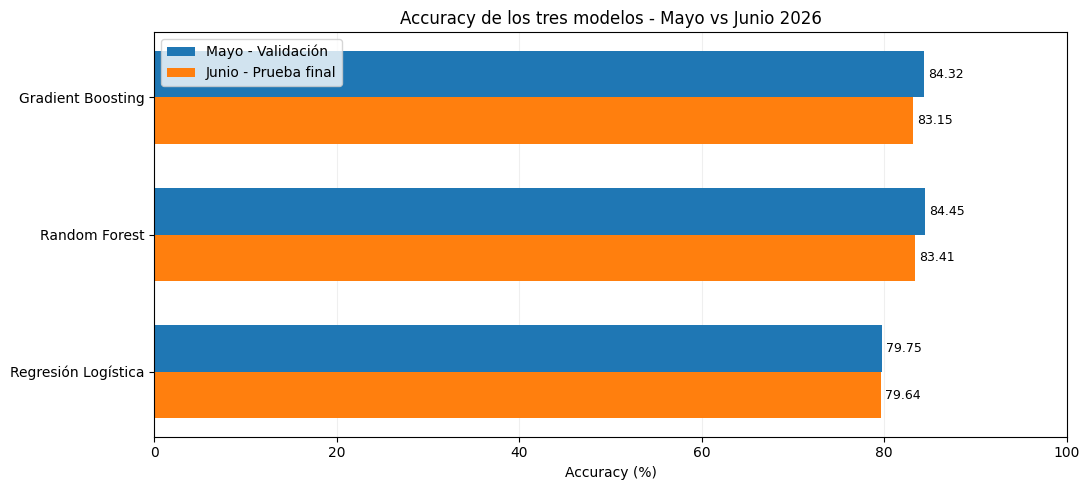

Gráfico guardado: comparacion_accuracy_mayo_junio.png

3. GRÁFICO COMPARATIVO DE ROC-AUC


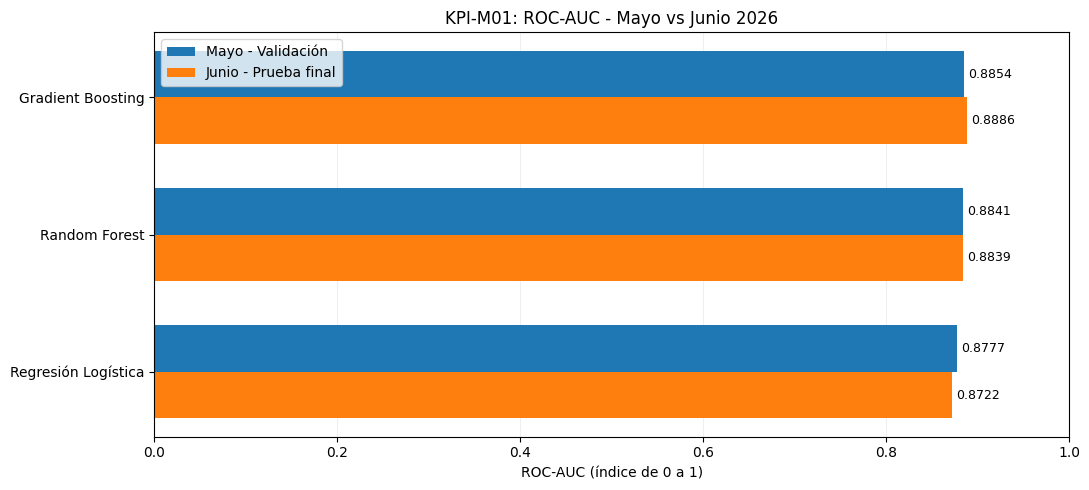

Gráfico guardado: comparacion_roc_auc_mayo_junio.png

4. GRÁFICO COMPARATIVO DE RECALL


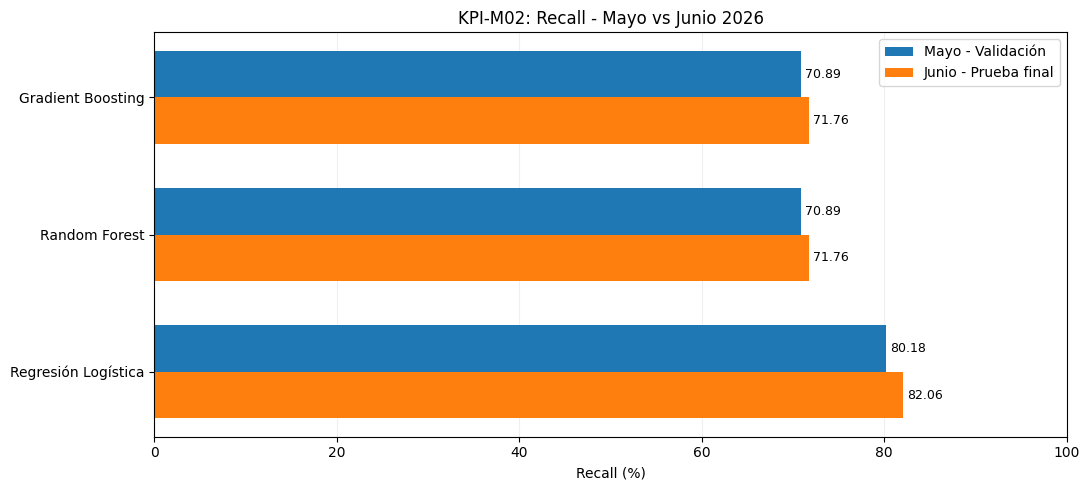

Gráfico guardado: comparacion_recall_mayo_junio.png

PASO 12 FINALIZADO
Modelos comparados: 3
Períodos comparados: MAYO Y JUNIO
Gráficos generados: 3
Tabla comparativa guardada: SI

Ubicación de evidencias:
c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\06_informe

Modelos reentrenados: NO
Selección de modelos modificada: NO
SQL Server: SIN MODIFICACIONES


In [21]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 12. COMPARACIÓN MAYO VS JUNIO
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display


# ============================================================
# 1. VERIFICAR RESULTADOS ANTERIORES
# ============================================================

necesarias = [
    "tabla_tres_modelos",
    "tabla_prueba_final"
]

faltantes = [
    nombre
    for nombre in necesarias
    if nombre not in globals()
]

if faltantes:
    raise RuntimeError(
        "Faltan resultados de los pasos anteriores: "
        f"{faltantes}"
    )

if len(tabla_tres_modelos) != 3:
    raise ValueError(
        "La validación debe contener tres modelos."
    )

if len(tabla_prueba_final) != 3:
    raise ValueError(
        "La prueba final debe contener tres modelos."
    )


# ============================================================
# 2. RECUPERAR RESULTADOS DE MAYO
# ============================================================

mayo = tabla_tres_modelos[
    [
        "Modelo",
        "Accuracy (%)",
        "ROC-AUC",
        "Recall (%)"
    ]
].copy()

mayo = mayo.rename(columns={
    "Accuracy (%)": "Accuracy_mayo",
    "ROC-AUC": "ROC_AUC_mayo",
    "Recall (%)": "Recall_mayo"
})


# ============================================================
# 3. RECUPERAR RESULTADOS DE JUNIO
# ============================================================

junio = tabla_prueba_final[
    [
        "Modelo",
        "Accuracy_pct",
        "KPI_M01_ROC_AUC",
        "KPI_M02_Recall_pct"
    ]
].copy()

junio = junio.rename(columns={
    "Accuracy_pct": "Accuracy_junio",
    "KPI_M01_ROC_AUC": "ROC_AUC_junio",
    "KPI_M02_Recall_pct": "Recall_junio"
})


# ============================================================
# 4. INTEGRAR RESULTADOS
# ============================================================

comparacion_temporal = mayo.merge(
    junio,
    on="Modelo",
    how="inner",
    validate="one_to_one"
)

if len(comparacion_temporal) != 3:
    raise ValueError(
        "No coinciden los tres modelos de mayo y junio."
    )

# Variación en puntos porcentuales.
comparacion_temporal["Diferencia_Accuracy_pp"] = (
    comparacion_temporal["Accuracy_junio"]
    - comparacion_temporal["Accuracy_mayo"]
)

comparacion_temporal["Diferencia_Recall_pp"] = (
    comparacion_temporal["Recall_junio"]
    - comparacion_temporal["Recall_mayo"]
)

# ROC-AUC es un índice entre 0 y 1.
comparacion_temporal["Diferencia_ROC_AUC"] = (
    comparacion_temporal["ROC_AUC_junio"]
    - comparacion_temporal["ROC_AUC_mayo"]
)

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("PASO 12. COMPARACIÓN MAYO VS JUNIO")
print("=" * 70)

print("\n1. COMPARACIÓN DE LOS TRES MODELOS")

display(
    comparacion_temporal.round(4)
)


# ============================================================
# 5. CREAR CARPETA DE INFORME
# ============================================================

proyecto = Path.cwd()

carpeta_informe = (
    proyecto
    / "resultados"
    / "06_informe"
)

carpeta_informe.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 6. FUNCIÓN PARA GENERAR GRÁFICOS
# ============================================================

def grafico_comparativo(
    datos,
    columna_mayo,
    columna_junio,
    titulo,
    etiqueta_eje,
    limite,
    formato,
    archivo
):

    posiciones = np.arange(len(datos))
    altura = 0.34

    fig, ax = plt.subplots(
        figsize=(11, 5)
    )

    barras_mayo = ax.barh(
        posiciones - altura / 2,
        datos[columna_mayo],
        height=altura,
        label="Mayo - Validación"
    )

    barras_junio = ax.barh(
        posiciones + altura / 2,
        datos[columna_junio],
        height=altura,
        label="Junio - Prueba final"
    )

    ax.set_yticks(posiciones)
    ax.set_yticklabels(
        datos["Modelo"]
    )

    ax.invert_yaxis()

    ax.set_xlim(0, limite)
    ax.set_xlabel(etiqueta_eje)
    ax.set_title(titulo)

    ax.legend()

    ax.bar_label(
        barras_mayo,
        fmt=formato,
        padding=3,
        fontsize=9
    )

    ax.bar_label(
        barras_junio,
        fmt=formato,
        padding=3,
        fontsize=9
    )

    ax.grid(
        axis="x",
        alpha=0.2
    )

    ax.set_axisbelow(True)

    plt.tight_layout()

    ruta = carpeta_informe / archivo

    plt.savefig(
        ruta,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Gráfico guardado:", ruta.name)


# ============================================================
# 7. GRÁFICO DE ACCURACY
# ============================================================

print("\n2. GRÁFICO COMPARATIVO DE ACCURACY")

grafico_comparativo(
    datos=comparacion_temporal,
    columna_mayo="Accuracy_mayo",
    columna_junio="Accuracy_junio",
    titulo="Accuracy de los tres modelos - Mayo vs Junio 2026",
    etiqueta_eje="Accuracy (%)",
    limite=100,
    formato="%.2f",
    archivo="comparacion_accuracy_mayo_junio.png"
)


# ============================================================
# 8. GRÁFICO DE ROC-AUC
# ============================================================

print("\n3. GRÁFICO COMPARATIVO DE ROC-AUC")

grafico_comparativo(
    datos=comparacion_temporal,
    columna_mayo="ROC_AUC_mayo",
    columna_junio="ROC_AUC_junio",
    titulo="KPI-M01: ROC-AUC - Mayo vs Junio 2026",
    etiqueta_eje="ROC-AUC (índice de 0 a 1)",
    limite=1,
    formato="%.4f",
    archivo="comparacion_roc_auc_mayo_junio.png"
)


# ============================================================
# 9. GRÁFICO DE RECALL
# ============================================================

print("\n4. GRÁFICO COMPARATIVO DE RECALL")

grafico_comparativo(
    datos=comparacion_temporal,
    columna_mayo="Recall_mayo",
    columna_junio="Recall_junio",
    titulo="KPI-M02: Recall - Mayo vs Junio 2026",
    etiqueta_eje="Recall (%)",
    limite=100,
    formato="%.2f",
    archivo="comparacion_recall_mayo_junio.png"
)


# ============================================================
# 10. GUARDAR TABLA
# ============================================================

ruta_tabla = (
    carpeta_informe
    / "comparacion_modelos_mayo_junio.csv"
)

comparacion_temporal.to_csv(
    ruta_tabla,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 11. VERIFICACIONES
# ============================================================

assert (
    comparacion_temporal["Modelo"].nunique()
    == 3
)

for columna in [
    "Accuracy_mayo",
    "Accuracy_junio",
    "Recall_mayo",
    "Recall_junio"
]:
    assert comparacion_temporal[
        columna
    ].between(0, 100).all()

for columna in [
    "ROC_AUC_mayo",
    "ROC_AUC_junio"
]:
    assert comparacion_temporal[
        columna
    ].between(0, 1).all()


# ============================================================
# 12. RESULTADO FINAL
# ============================================================

print("\n" + "=" * 70)
print("PASO 12 FINALIZADO")
print("=" * 70)

print("Modelos comparados: 3")
print("Períodos comparados: MAYO Y JUNIO")
print("Gráficos generados: 3")
print("Tabla comparativa guardada: SI")

print("\nUbicación de evidencias:")
print(carpeta_informe)

print("\nModelos reentrenados: NO")
print("Selección de modelos modificada: NO")
print("SQL Server: SIN MODIFICACIONES")



## PASO 13. Visualización de las matrices de confusión

### Objetivo
Representar gráficamente los aciertos y errores de los tres modelos predictivos seleccionados durante la prueba final de junio de 2026.

### Modelos
- Gradient Boosting.
- Random Forest.
- Regresión Logística.

### Interpretación de las matrices
- Verdaderos positivos (VP): citas con inasistencia correctamente identificadas.
- Verdaderos negativos (VN): asistencias correctamente identificadas.
- Falsos positivos (FP): citas clasificadas como inasistencias cuando realmente hubo asistencia.
- Falsos negativos (FN): inasistencias reales que el modelo no detectó.

### Metodología
Las matrices se construirán a partir de los resultados calculados en el PASO 11, sin reentrenar modelos ni cambiar los umbrales.

### Evidencias
- Tres matrices de confusión en formato PNG.
- Una tabla CSV con los aciertos y errores de cada modelo.


RED SALUD INTEGRAL CARAZO
PASO 13. MATRICES DE CONFUSIÓN

-----------------------------------------------------------------
MODELO: Gradient Boosting
-----------------------------------------------------------------


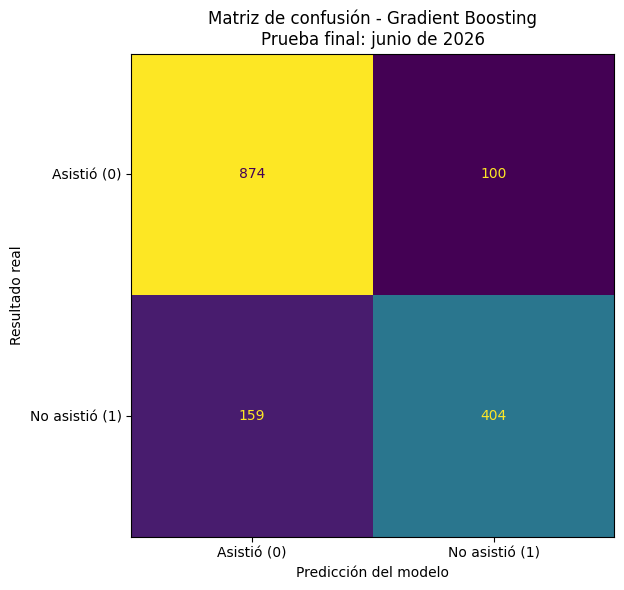

Matriz guardada: matriz_gradient_boosting.png

-----------------------------------------------------------------
MODELO: Random Forest
-----------------------------------------------------------------


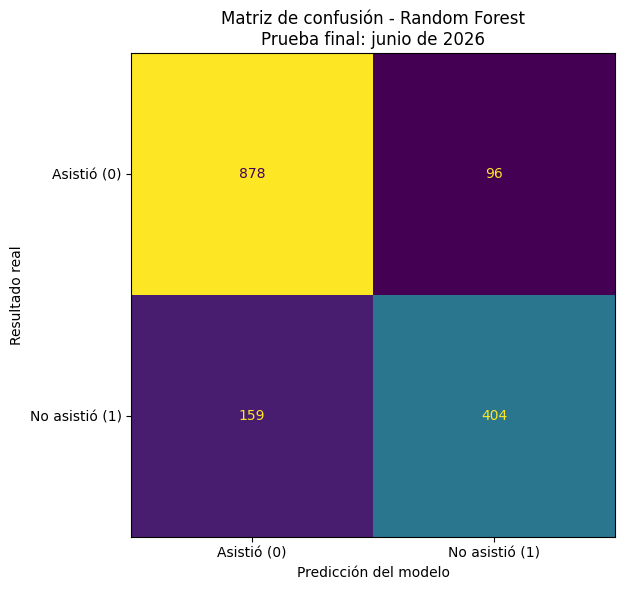

Matriz guardada: matriz_random_forest.png

-----------------------------------------------------------------
MODELO: Regresión Logística
-----------------------------------------------------------------


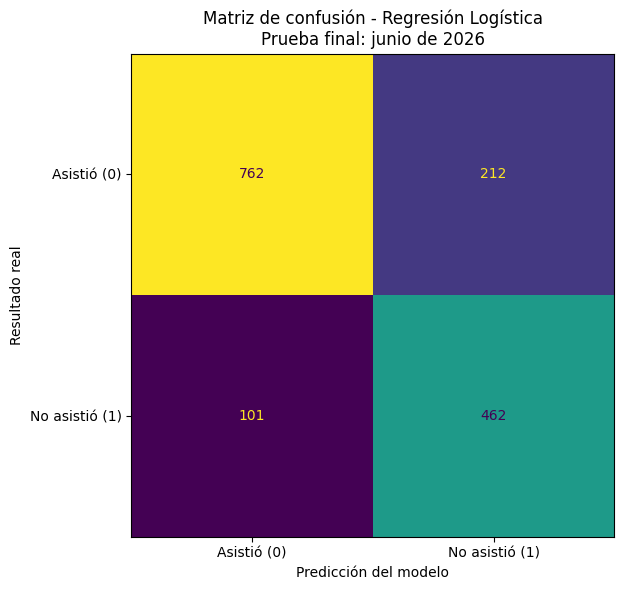

Matriz guardada: matriz_regresion_logistica.png

RESUMEN DE ACIERTOS Y ERRORES


,Modelo,Periodo,Registros,VP,VN,FP,FN,Aciertos,Errores,Recall_pct,Precision_pct,Accuracy_pct
0,Gradient Boosting,2026-06,1537,404,874,100,159,1278,259,71.7584,80.1587,83.1490
1,Random Forest,2026-06,1537,404,878,96,159,1282,255,71.7584,80.8000,83.4092
2,Regresión Logística,2026-06,1537,462,762,212,101,1224,313,82.0604,68.5460,79.6357



PASO 13 FINALIZADO
Matrices de confusión generadas: 3
Modelos evaluados: 3
Registros por modelo: 1537
Consistencia con PASO 11: VERIFICADA

Evidencias guardadas en:
c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\06_informe\matrices_confusion

Modelos reentrenados: NO
Selección modificada: NO
SQL Server: SIN MODIFICACIONES


In [22]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 13. MATRICES DE CONFUSIÓN VISUALES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay


# ============================================================
# 1. VERIFICAR RESULTADOS DEL PASO 11
# ============================================================

if "tabla_prueba_final" not in globals():
    raise RuntimeError(
        "Primero debes ejecutar el PASO 11."
    )

columnas = [
    "Modelo",
    "VP",
    "VN",
    "FP",
    "FN"
]

faltantes = set(columnas) - set(
    tabla_prueba_final.columns
)

if faltantes:
    raise ValueError(
        f"Faltan columnas: {sorted(faltantes)}"
    )

if len(tabla_prueba_final) != 3:
    raise ValueError(
        "Se esperan tres modelos evaluados."
    )

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("PASO 13. MATRICES DE CONFUSIÓN")
print("=" * 70)


# ============================================================
# 2. PREPARAR CARPETA
# ============================================================

proyecto = Path.cwd()

carpeta_matrices = (
    proyecto
    / "resultados"
    / "06_informe"
    / "matrices_confusion"
)

carpeta_matrices.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 3. IDENTIFICAR LOS TRES MODELOS
# ============================================================

nombres_archivos = {
    "Gradient Boosting": "gradient_boosting",
    "Random Forest": "random_forest",
    "Regresión Logística": "regresion_logistica"
}

if set(tabla_prueba_final["Modelo"]) != set(
    nombres_archivos
):
    raise ValueError(
        "Los nombres de los tres modelos no coinciden."
    )


# ============================================================
# 4. GENERAR UNA MATRIZ POR MODELO
# ============================================================

resumen_errores = []

for _, fila in tabla_prueba_final.iterrows():

    nombre = fila["Modelo"]

    vp = int(fila["VP"])
    vn = int(fila["VN"])
    fp = int(fila["FP"])
    fn = int(fila["FN"])

    total = vp + vn + fp + fn

    if total != 1537:
        raise ValueError(
            f"{nombre}: se esperaban 1,537 registros."
        )

    if vp + fn != 563:
        raise ValueError(
            f"{nombre}: el total de inasistencias "
            "no coincide con los datos de junio."
        )

    if vn + fp != 974:
        raise ValueError(
            f"{nombre}: el total de asistencias "
            "no coincide con los datos de junio."
        )

    # Filas = resultado real
    # Columnas = predicción del modelo
    #
    #             Predice 0   Predice 1
    # Real 0         VN          FP
    # Real 1         FN          VP

    matriz = np.array([
        [vn, fp],
        [fn, vp]
    ])

    print("\n" + "-" * 65)
    print("MODELO:", nombre)
    print("-" * 65)

    fig, ax = plt.subplots(
        figsize=(7, 6)
    )

    visualizacion = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=[
            "Asistió (0)",
            "No asistió (1)"
        ]
    )

    visualizacion.plot(
        ax=ax,
        values_format="d",
        colorbar=False
    )

    ax.set_title(
        f"Matriz de confusión - {nombre}\n"
        "Prueba final: junio de 2026"
    )

    ax.set_xlabel(
        "Predicción del modelo"
    )

    ax.set_ylabel(
        "Resultado real"
    )

    plt.tight_layout()

    archivo = (
        carpeta_matrices
        / f"matriz_{nombres_archivos[nombre]}.png"
    )

    plt.savefig(
        archivo,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    # Registrar resultados para auditoría
    resumen_errores.append({
        "Modelo": nombre,
        "Periodo": "2026-06",
        "Registros": total,
        "VP": vp,
        "VN": vn,
        "FP": fp,
        "FN": fn,
        "Aciertos": vp + vn,
        "Errores": fp + fn,
        "Recall_pct": round(
            vp / (vp + fn) * 100,
            4
        ),
        "Precision_pct": round(
            vp / (vp + fp) * 100,
            4
        ),
        "Accuracy_pct": round(
            (vp + vn) / total * 100,
            4
        )
    })

    print("Matriz guardada:", archivo.name)


# ============================================================
# 5. CONSTRUIR TABLA DE AUDITORÍA
# ============================================================

tabla_matrices_junio = pd.DataFrame(
    resumen_errores
)

print("\n" + "=" * 70)
print("RESUMEN DE ACIERTOS Y ERRORES")
print("=" * 70)

display(tabla_matrices_junio)


# ============================================================
# 6. VERIFICAR CONSISTENCIA DE MÉTRICAS
# ============================================================

referencia = tabla_prueba_final.set_index(
    "Modelo"
)

for _, fila in tabla_matrices_junio.iterrows():

    nombre = fila["Modelo"]

    if not np.isclose(
        fila["Recall_pct"],
        referencia.loc[
            nombre,
            "KPI_M02_Recall_pct"
        ],
        atol=0.0002
    ):
        raise ValueError(
            f"Inconsistencia de Recall: {nombre}"
        )

    if not np.isclose(
        fila["Accuracy_pct"],
        referencia.loc[
            nombre,
            "Accuracy_pct"
        ],
        atol=0.0002
    ):
        raise ValueError(
            f"Inconsistencia de Accuracy: {nombre}"
        )

    if not np.isclose(
        fila["Precision_pct"],
        referencia.loc[
            nombre,
            "Precision_pct"
        ],
        atol=0.0002
    ):
        raise ValueError(
            f"Inconsistencia de Precision: {nombre}"
        )


# ============================================================
# 7. GUARDAR EVIDENCIAS
# ============================================================

ruta_resumen = (
    carpeta_matrices
    / "resumen_matrices_junio.csv"
)

tabla_matrices_junio.to_csv(
    ruta_resumen,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 8. RESULTADO FINAL
# ============================================================

print("\n" + "=" * 70)
print("PASO 13 FINALIZADO")
print("=" * 70)

print("Matrices de confusión generadas: 3")
print("Modelos evaluados: 3")
print("Registros por modelo: 1537")
print("Consistencia con PASO 11: VERIFICADA")

print("\nEvidencias guardadas en:")
print(carpeta_matrices)

print("\nModelos reentrenados: NO")
print("Selección modificada: NO")
print("SQL Server: SIN MODIFICACIONES")



## PASO 14. Curvas ROC de los tres modelos seleccionados

### Objetivo
Visualizar y comparar la capacidad de discriminación de Gradient Boosting, Random Forest y Regresión Logística mediante curvas ROC.

### KPI evaluado
**KPI-M01: ROC-AUC**

### Metodología
- Período: junio de 2026.
- Registros por modelo: 1,537.
- Clase positiva: no_asistio = 1.
- Las curvas se calculan utilizando las probabilidades guardadas durante el PASO 11.
- No se reentrenan ni se vuelven a seleccionar modelos.

### Evidencias
- Gráfico ROC comparativo de los tres modelos.
- Tres gráficos ROC individuales.
- Tabla de valores ROC-AUC.
- Archivo CSV con los puntos utilizados para construir cada curva.

### Limitación
La procedencia temporal de citas_previas_perdidas permanece sin verificar.


RED SALUD INTEGRAL CARAZO
PASO 14. CURVAS ROC

Período: junio de 2026
Modelos: 3
Clase positiva: no_asistio = 1

Gradient Boosting: ROC-AUC = 0.8886

Random Forest: ROC-AUC = 0.8839

Regresión Logística: ROC-AUC = 0.8722

1. CURVAS ROC COMPARATIVAS


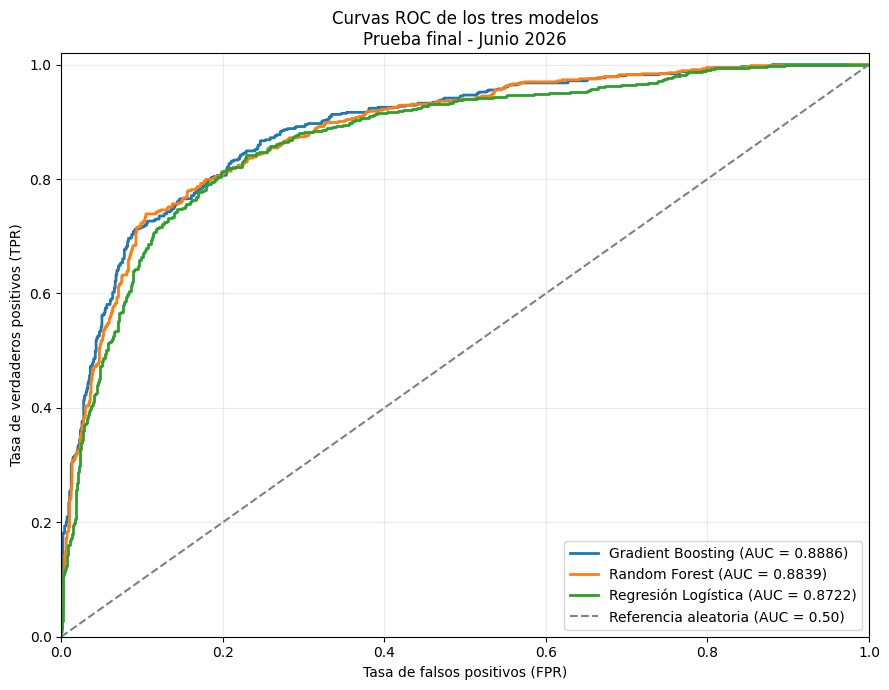


2. CURVAS ROC INDIVIDUALES


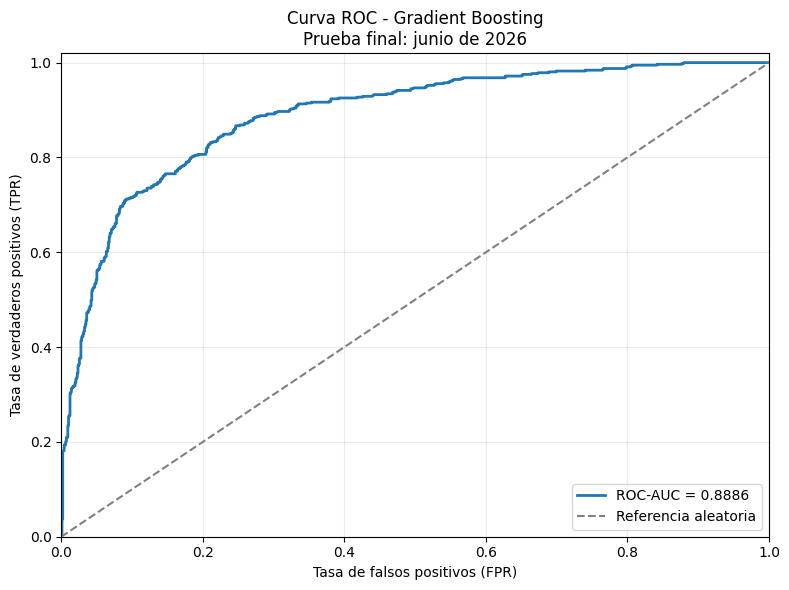

Guardado: roc_gradient_boosting.png


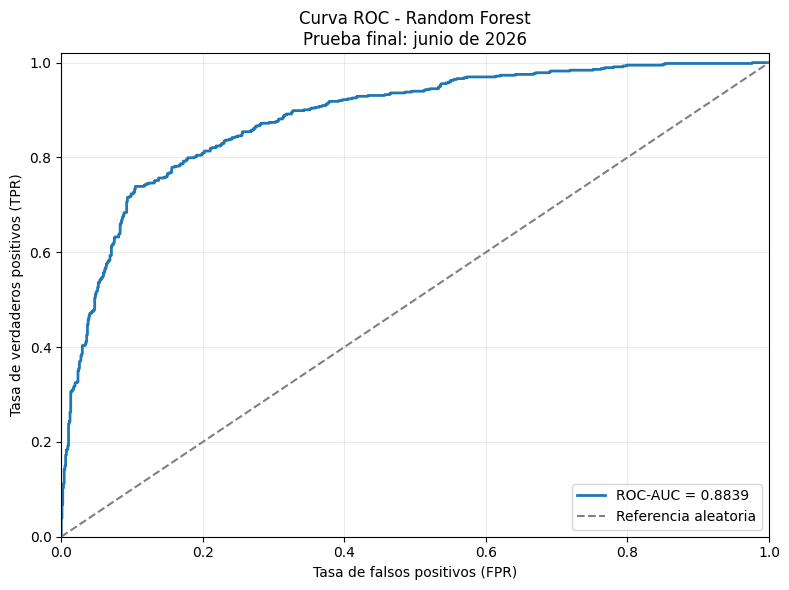

Guardado: roc_random_forest.png


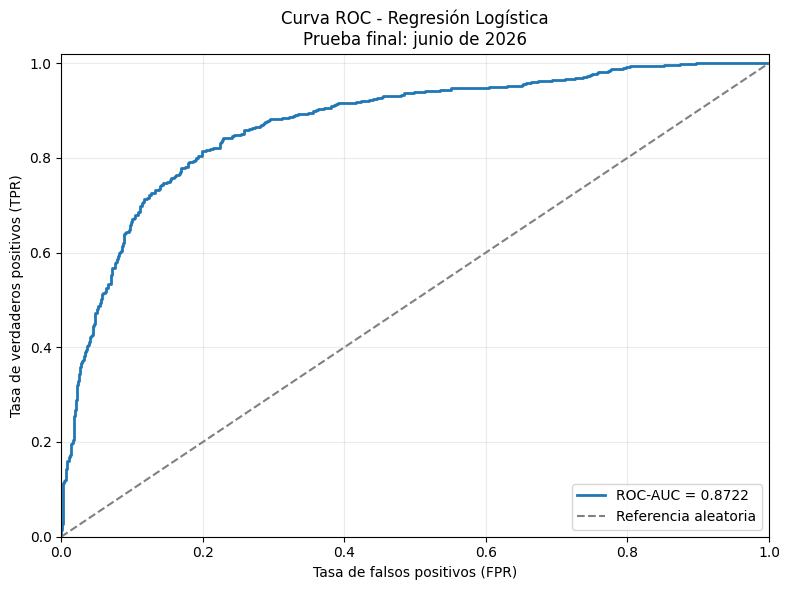

Guardado: roc_regresion_logistica.png

3. RESULTADO DEL KPI-M01


,Modelo,Periodo,Registros,KPI_M01_ROC_AUC,KPI_M01_ROC_AUC_pct,Coincide_paso_11
0,Gradient Boosting,2026-06,1537,0.8886,88.86,SI
1,Random Forest,2026-06,1537,0.8839,88.39,SI
2,Regresión Logística,2026-06,1537,0.8722,87.22,SI



PASO 14 FINALIZADO
Curvas ROC calculadas: 3
Gráfico comparativo generado: 1
Gráficos individuales generados: 3
KPI-M01 verificado con PASO 11: SI

Evidencias guardadas en:
c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\06_informe\curvas_roc

Modelos reentrenados: NO
Selección modificada: NO
SQL Server: SIN MODIFICACIONES
Validez temporal de citas_previas_perdidas: NO VERIFICADA


In [23]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 14. CURVAS ROC DE LOS TRES MODELOS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)


# ============================================================
# 1. VERIFICAR RESULTADOS ANTERIORES
# ============================================================

necesarias = [
    "detalle_prueba_final",
    "tabla_prueba_final"
]

faltantes = [
    nombre
    for nombre in necesarias
    if nombre not in globals()
]

if faltantes:
    raise RuntimeError(
        "Primero debes ejecutar el PASO 11. "
        f"Faltan: {faltantes}"
    )

columnas_predicciones = [
    "id_cita",
    "Modelo",
    "Valor_real",
    "Probabilidad_inasistencia"
]

faltantes_columnas = (
    set(columnas_predicciones)
    - set(detalle_prueba_final.columns)
)

if faltantes_columnas:
    raise ValueError(
        "Faltan columnas de predicciones: "
        f"{sorted(faltantes_columnas)}"
    )

if len(tabla_prueba_final) != 3:
    raise ValueError(
        "Se esperan tres modelos evaluados."
    )

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("PASO 14. CURVAS ROC")
print("=" * 70)

print("\nPeríodo: junio de 2026")
print("Modelos:", len(tabla_prueba_final))
print("Clase positiva: no_asistio = 1")


# ============================================================
# 2. PREPARAR CARPETA DE EVIDENCIAS
# ============================================================

proyecto = Path.cwd()

carpeta_roc = (
    proyecto
    / "resultados"
    / "06_informe"
    / "curvas_roc"
)

carpeta_roc.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 3. DEFINIR LOS MODELOS
# ============================================================

nombres_archivos = {
    "Gradient Boosting": "gradient_boosting",
    "Random Forest": "random_forest",
    "Regresión Logística": "regresion_logistica"
}

if set(tabla_prueba_final["Modelo"]) != set(
    nombres_archivos
):
    raise ValueError(
        "No coinciden los nombres de "
        "los modelos seleccionados."
    )


# ============================================================
# 4. CALCULAR LAS CURVAS ROC
# ============================================================

curvas_modelos = {}
resultados_roc = []
puntos_curvas = []

for nombre in nombres_archivos:

    datos = detalle_prueba_final.loc[
        detalle_prueba_final["Modelo"] == nombre
    ].copy()

    if len(datos) != 1537:
        raise ValueError(
            f"{nombre}: se esperaban 1537 predicciones."
        )

    if datos["id_cita"].duplicated().any():
        raise ValueError(
            f"{nombre}: hay citas repetidas."
        )

    valores_reales = pd.to_numeric(
        datos["Valor_real"],
        errors="coerce"
    ).to_numpy()

    probabilidades = pd.to_numeric(
        datos["Probabilidad_inasistencia"],
        errors="coerce"
    ).to_numpy()

    if not np.isin(
        valores_reales, [0, 1]
    ).all():
        raise ValueError(
            f"{nombre}: valores reales inválidos."
        )

    if not (
        np.isfinite(probabilidades).all()
        and np.all(probabilidades >= 0)
        and np.all(probabilidades <= 1)
    ):
        raise ValueError(
            f"{nombre}: probabilidades inválidas."
        )

    if np.sum(valores_reales == 1) != 563:
        raise ValueError(
            f"{nombre}: total de inasistencias inesperado."
        )

    # Calcular puntos de la curva ROC
    fpr, tpr, umbrales = roc_curve(
        valores_reales,
        probabilidades,
        pos_label=1
    )

    # Calcular el KPI-M01
    roc_auc = roc_auc_score(
        valores_reales,
        probabilidades
    )

    # Comparar con el valor del PASO 11
    valor_anterior = float(
        tabla_prueba_final.loc[
            tabla_prueba_final["Modelo"] == nombre,
            "KPI_M01_ROC_AUC"
        ].iloc[0]
    )

    if not np.isclose(
        roc_auc,
        valor_anterior,
        atol=0.0001
    ):
        raise ValueError(
            f"{nombre}: el ROC-AUC no coincide "
            "con el PASO 11."
        )

    curvas_modelos[nombre] = {
        "fpr": fpr,
        "tpr": tpr,
        "auc": roc_auc
    }

    resultados_roc.append({
        "Modelo": nombre,
        "Periodo": "2026-06",
        "Registros": len(datos),
        "KPI_M01_ROC_AUC": round(
            roc_auc, 4
        ),
        "KPI_M01_ROC_AUC_pct": round(
            roc_auc * 100, 2
        ),
        "Coincide_paso_11": "SI"
    })

    puntos_curvas.append(
        pd.DataFrame({
            "Modelo": nombre,
            "FPR": fpr,
            "TPR": tpr,
            "Umbral": umbrales
        })
    )

    print(
        f"\n{nombre}: ROC-AUC = {roc_auc:.4f}"
    )


# ============================================================
# 5. GRÁFICO ROC COMPARATIVO
# ============================================================

print("\n1. CURVAS ROC COMPARATIVAS")

fig, ax = plt.subplots(
    figsize=(9, 7)
)

for nombre, valores in curvas_modelos.items():

    ax.plot(
        valores["fpr"],
        valores["tpr"],
        linewidth=2,
        label=(
            f"{nombre} "
            f"(AUC = {valores['auc']:.4f})"
        )
    )

# Referencia de clasificación aleatoria
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Referencia aleatoria (AUC = 0.50)"
)

ax.set_xlabel(
    "Tasa de falsos positivos (FPR)"
)

ax.set_ylabel(
    "Tasa de verdaderos positivos (TPR)"
)

ax.set_title(
    "Curvas ROC de los tres modelos\n"
    "Prueba final - Junio 2026"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.legend(loc="lower right")
ax.grid(alpha=0.25)

plt.tight_layout()

ruta_comparativa = (
    carpeta_roc
    / "curvas_roc_tres_modelos.png"
)

plt.savefig(
    ruta_comparativa,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 6. GRÁFICOS ROC INDIVIDUALES
# ============================================================

print("\n2. CURVAS ROC INDIVIDUALES")

for nombre, valores in curvas_modelos.items():

    fig, ax = plt.subplots(
        figsize=(8, 6)
    )

    ax.plot(
        valores["fpr"],
        valores["tpr"],
        linewidth=2,
        label=(
            f"ROC-AUC = {valores['auc']:.4f}"
        )
    )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray",
        label="Referencia aleatoria"
    )

    ax.set_xlabel(
        "Tasa de falsos positivos (FPR)"
    )

    ax.set_ylabel(
        "Tasa de verdaderos positivos (TPR)"
    )

    ax.set_title(
        f"Curva ROC - {nombre}\n"
        "Prueba final: junio de 2026"
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)

    ax.legend(loc="lower right")
    ax.grid(alpha=0.25)

    plt.tight_layout()

    archivo = (
        carpeta_roc
        / f"roc_{nombres_archivos[nombre]}.png"
    )

    plt.savefig(
        archivo,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Guardado:", archivo.name)


# ============================================================
# 7. CREAR TABLA DEL KPI-M01
# ============================================================

tabla_curvas_roc = pd.DataFrame(
    resultados_roc
)

detalle_puntos_roc = pd.concat(
    puntos_curvas,
    ignore_index=True
)

print("\n3. RESULTADO DEL KPI-M01")

display(tabla_curvas_roc)


# ============================================================
# 8. GUARDAR EVIDENCIAS
# ============================================================

tabla_curvas_roc.to_csv(
    carpeta_roc / "kpi_m01_roc_auc_junio.csv",
    index=False,
    encoding="utf-8-sig"
)

detalle_puntos_roc.to_csv(
    carpeta_roc / "puntos_curvas_roc_junio.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 9. VERIFICACIONES FINALES
# ============================================================

assert len(tabla_curvas_roc) == 3
assert len(curvas_modelos) == 3

assert (
    tabla_curvas_roc["Coincide_paso_11"]
    == "SI"
).all()

print("\n" + "=" * 70)
print("PASO 14 FINALIZADO")
print("=" * 70)

print("Curvas ROC calculadas: 3")
print("Gráfico comparativo generado: 1")
print("Gráficos individuales generados: 3")
print("KPI-M01 verificado con PASO 11: SI")

print("\nEvidencias guardadas en:")
print(carpeta_roc)

print("\nModelos reentrenados: NO")
print("Selección modificada: NO")
print("SQL Server: SIN MODIFICACIONES")
print(
    "Validez temporal de citas_previas_perdidas: "
    "NO VERIFICADA"
)



## PASO 15. Consolidación de los tres KPI del proyecto

### Objetivo
Consolidar en una tabla los dos KPI de Minería de Datos y el KPI de Calidad de Datos, utilizando los resultados obtenidos durante el desarrollo del proyecto.

### Indicadores
- KPI-M01: ROC-AUC.
- KPI-M02: Recall.
- KPI-C01: Completitud de registros predictivos.

### Fuentes
- Evaluación de los tres modelos con junio de 2026.
- Auditoría de completitud del dataset predictivo.

### Metodología
Los indicadores de minería se presentan por cada modelo seleccionado.

El indicador de calidad se presenta por separado porque evalúa el conjunto de datos y no el rendimiento de un algoritmo.

### Consideración
La variable citas_previas_perdidas conserva una limitación de procedencia temporal no verificada, documentada durante la auditoría.


In [24]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA Y CALIDAD DE DATOS
# PASO 15. CONSOLIDACIÓN DE LOS TRES KPI
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display


# ============================================================
# 1. VERIFICAR RESULTADOS ANTERIORES
# ============================================================

necesarias = [
    "tabla_prueba_final",
    "tabla_kpi_calidad",
    "tabla_curvas_roc",
    "tabla_tres_modelos"
]

faltantes = [
    nombre
    for nombre in necesarias
    if nombre not in globals()
]

if faltantes:
    raise RuntimeError(
        "Faltan resultados de pasos anteriores: "
        f"{faltantes}"
    )

if len(tabla_prueba_final) != 3:
    raise ValueError(
        "Se requieren los tres modelos evaluados."
    )

if len(tabla_kpi_calidad) != 1:
    raise ValueError(
        "Se requiere el KPI de calidad."
    )

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("PASO 15. CONSOLIDACIÓN DE LOS TRES KPI")
print("=" * 70)


# ============================================================
# 2. VALIDAR CONSISTENCIA CON EL PASO 14
# ============================================================

roc_verificado = tabla_curvas_roc[
    ["Modelo", "KPI_M01_ROC_AUC"]
].copy()

roc_final = tabla_prueba_final[
    ["Modelo", "KPI_M01_ROC_AUC"]
].copy()

comparacion_roc = roc_final.merge(
    roc_verificado,
    on="Modelo",
    suffixes=("_paso11", "_paso14"),
    validate="one_to_one"
)

assert len(comparacion_roc) == 3

if not np.allclose(
    comparacion_roc["KPI_M01_ROC_AUC_paso11"],
    comparacion_roc["KPI_M01_ROC_AUC_paso14"],
    atol=0.0001
):
    raise ValueError(
        "Los valores ROC-AUC no coinciden."
    )


# ============================================================
# 3. CONSOLIDAR KPI DE MINERÍA
# ============================================================

filas_kpi = []

for _, fila in tabla_prueba_final.iterrows():

    nombre = fila["Modelo"]

    # KPI-M01: ROC-AUC
    filas_kpi.append({
        "Codigo": "KPI-M01",
        "Area": "Minería de Datos",
        "Indicador": "ROC-AUC",
        "Modelo": nombre,
        "Periodo": "Junio 2026",
        "Resultado": float(
            fila["KPI_M01_ROC_AUC"]
        ),
        "Unidad": "Índice de 0 a 1",
        "Registros_evaluados": int(
            fila["Registros"]
        ),
        "Estado_temporal": "NO VERIFICADO"
    })

    # KPI-M02: Recall
    filas_kpi.append({
        "Codigo": "KPI-M02",
        "Area": "Minería de Datos",
        "Indicador": "Recall",
        "Modelo": nombre,
        "Periodo": "Junio 2026",
        "Resultado": float(
            fila["KPI_M02_Recall_pct"]
        ),
        "Unidad": "Porcentaje",
        "Registros_evaluados": int(
            fila["Registros"]
        ),
        "Estado_temporal": "NO VERIFICADO"
    })


# ============================================================
# 4. INCORPORAR KPI DE CALIDAD
# ============================================================

calidad = tabla_kpi_calidad.iloc[0]

filas_kpi.append({
    "Codigo": "KPI-C01",
    "Area": "Calidad de Datos",
    "Indicador": (
        "Completitud de registros predictivos"
    ),
    "Modelo": "NO APLICA",
    "Periodo": "Dataset enero-junio 2026",
    "Resultado": float(
        calidad["Resultado_pct"]
    ),
    "Unidad": "Porcentaje",
    "Registros_evaluados": int(
        calidad["Registros_evaluados"]
    ),
    "Estado_temporal": "NO APLICA AL INDICADOR"
})


# ============================================================
# 5. CREAR TABLA GENERAL DE KPI
# ============================================================

tabla_kpi_consolidada = pd.DataFrame(
    filas_kpi
)

print("\n1. RESULTADOS DE LOS TRES KPI")

display(
    tabla_kpi_consolidada.round(4)
)


# ============================================================
# 6. TABLA RESUMIDA PARA EL INFORME
# ============================================================

resumen_presentacion = (
    tabla_prueba_final[
        [
            "Modelo",
            "Accuracy_pct",
            "Precision_pct",
            "KPI_M01_ROC_AUC",
            "KPI_M02_Recall_pct"
        ]
    ]
    .copy()
)

resumen_presentacion = resumen_presentacion.rename(
    columns={
        "Accuracy_pct": "Accuracy (%)",
        "Precision_pct": "Precision (%)",
        "KPI_M01_ROC_AUC": "ROC-AUC",
        "KPI_M02_Recall_pct": "Recall (%)"
    }
)

# Conservar el orden de selección por mayo
orden_modelos = (
    tabla_tres_modelos["Modelo"].tolist()
)

resumen_presentacion["Orden"] = (
    resumen_presentacion["Modelo"].map({
        nombre: indice
        for indice, nombre in enumerate(
            orden_modelos,
            start=1
        )
    })
)

resumen_presentacion = (
    resumen_presentacion
    .sort_values("Orden")
    .drop(columns="Orden")
    .reset_index(drop=True)
)

print("\n2. RESUMEN PREDICTIVO PARA PRESENTACIÓN")

display(
    resumen_presentacion.round(4)
)


# ============================================================
# 7. MOSTRAR KPI DE CALIDAD POR SEPARADO
# ============================================================

print("\n3. RESULTADO DEL KPI DE CALIDAD")

display(
    tabla_kpi_calidad[
        [
            "Codigo",
            "Indicador",
            "Registros_evaluados",
            "Registros_completos",
            "Resultado_pct"
        ]
    ]
)


# ============================================================
# 8. VERIFICACIONES
# ============================================================

assert (
    tabla_kpi_consolidada["Codigo"].nunique()
    == 3
)

assert set(
    tabla_kpi_consolidada["Codigo"]
) == {
    "KPI-M01",
    "KPI-M02",
    "KPI-C01"
}

assert (
    tabla_kpi_consolidada["Modelo"]
    .loc[
        tabla_kpi_consolidada["Codigo"]
        == "KPI-C01"
    ]
    .eq("NO APLICA")
    .all()
)

assert len(resumen_presentacion) == 3

assert len(tabla_kpi_consolidada) == 7


# ============================================================
# 9. GUARDAR EVIDENCIAS
# ============================================================

proyecto = Path.cwd()

carpeta_informe = (
    proyecto
    / "resultados"
    / "06_informe"
)

carpeta_informe.mkdir(
    parents=True,
    exist_ok=True
)

tabla_kpi_consolidada.to_csv(
    carpeta_informe
    / "tres_kpi_consolidados.csv",
    index=False,
    encoding="utf-8-sig"
)

resumen_presentacion.to_csv(
    carpeta_informe
    / "resumen_tres_modelos.csv",
    index=False,
    encoding="utf-8-sig"
)

tabla_kpi_calidad.to_csv(
    carpeta_informe
    / "resumen_kpi_calidad.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 10. RESULTADO FINAL
# ============================================================

print("\n" + "=" * 70)
print("PASO 15 FINALIZADO")
print("=" * 70)

print("KPI diferentes consolidados: 3")
print("KPI de minería: 2")
print("KPI de calidad: 1")
print("Modelos predictivos evaluados: 3")
print("Filas de resultados KPI: 7")

print("\nEvidencias guardadas en:")
print(carpeta_informe)

print("\nModelos reentrenados: NO")
print("SQL Server: SIN MODIFICACIONES")
print("Limitación temporal: DOCUMENTADA")


RED SALUD INTEGRAL CARAZO
PASO 15. CONSOLIDACIÓN DE LOS TRES KPI

1. RESULTADOS DE LOS TRES KPI


,Codigo,Area,Indicador,Modelo,Periodo,Resultado,Unidad,Registros_evaluados,Estado_temporal
0,KPI-M01,Minería de Datos,ROC-AUC,Gradient Boosting,Junio 2026,0.8886,Índice de 0 a 1,1537,NO VERIFICADO
1,KPI-M02,Minería de Datos,Recall,Gradient Boosting,Junio 2026,71.7584,Porcentaje,1537,NO VERIFICADO
2,KPI-M01,Minería de Datos,ROC-AUC,Random Forest,Junio 2026,0.8839,Índice de 0 a 1,1537,NO VERIFICADO
3,KPI-M02,Minería de Datos,Recall,Random Forest,Junio 2026,71.7584,Porcentaje,1537,NO VERIFICADO
4,KPI-M01,Minería de Datos,ROC-AUC,Regresión Logística,Junio 2026,0.8722,Índice de 0 a 1,1537,NO VERIFICADO
5,KPI-M02,Minería de Datos,Recall,Regresión Logística,Junio 2026,82.0604,Porcentaje,1537,NO VERIFICADO
6,KPI-C01,Calidad de Datos,Completitud de registros predictivos,NO APLICA,Dataset enero-junio 2026,100.0000,Porcentaje,8996,NO APLICA AL INDICADOR



2. RESUMEN PREDICTIVO PARA PRESENTACIÓN


,Modelo,Accuracy (%),Precision (%),ROC-AUC,Recall (%)
0,Gradient Boosting,83.1490,80.1587,0.8886,71.7584
1,Random Forest,83.4092,80.8000,0.8839,71.7584
2,Regresión Logística,79.6357,68.5460,0.8722,82.0604



3. RESULTADO DEL KPI DE CALIDAD


,Codigo,Indicador,Registros_evaluados,Registros_completos,Resultado_pct
0,KPI-C01,Completitud de registros predictivos,8996,8996,100.0



PASO 15 FINALIZADO
KPI diferentes consolidados: 3
KPI de minería: 2
KPI de calidad: 1
Modelos predictivos evaluados: 3
Filas de resultados KPI: 7

Evidencias guardadas en:
c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\06_informe

Modelos reentrenados: NO
SQL Server: SIN MODIFICACIONES
Limitación temporal: DOCUMENTADA



## PASO 16. Informe de resultados de Minería de Datos

### Objetivo
Consolidar las evidencias de la comparación de siete algoritmos, la selección de tres modelos y la evaluación de los KPI.

### Contenido
- Dataset y metodología de entrenamiento.
- Criterio de comparación y selección de modelos.
- Resultados de la prueba final.
- KPI de minería y calidad.
- Interpretación de las diferencias entre modelos.
- Limitaciones metodológicas.

### Resultado
Un archivo Markdown con el resumen técnico del proyecto, elaborado a partir de las tablas calculadas.


In [25]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 16. INFORME TÉCNICO DE RESULTADOS
# ============================================================

from pathlib import Path
from IPython.display import display, Markdown
import pandas as pd


# ============================================================
# 1. VERIFICAR EVIDENCIAS
# ============================================================

necesarias = [
    "tabla_comparativa",
    "tabla_tres_modelos",
    "tabla_prueba_final",
    "tabla_kpi_calidad",
    "tabla_kpi_consolidada"
]

faltantes = [
    nombre for nombre in necesarias
    if nombre not in globals()
]

if faltantes:
    raise RuntimeError(
        f"Faltan resultados anteriores: {faltantes}"
    )

assert len(tabla_comparativa) == 7
assert len(tabla_tres_modelos) == 3
assert len(tabla_prueba_final) == 3
assert len(tabla_kpi_calidad) == 1
assert tabla_kpi_consolidada["Codigo"].nunique() == 3


# ============================================================
# 2. CONSTRUIR TABLA DE COMPARACIÓN
# ============================================================

comparacion = tabla_comparativa.sort_values(
    "ROC-AUC",
    ascending=False
)

lineas_comparacion = [
    "| Modelo | Accuracy | Precision | Recall | ROC-AUC |",
    "|---|---:|---:|---:|---:|"
]

for _, fila in comparacion.iterrows():

    lineas_comparacion.append(
        f"| {fila['Modelo']} "
        f"| {fila['Accuracy (%)']:.2f}% "
        f"| {fila['Precision (%)']:.2f}% "
        f"| {fila['Recall (%)']:.2f}% "
        f"| {fila['ROC-AUC']:.4f} |"
    )


# ============================================================
# 3. CONSTRUIR TABLA DE PRUEBA FINAL
# ============================================================

orden = tabla_tres_modelos["Modelo"].tolist()

prueba = (
    tabla_prueba_final
    .set_index("Modelo")
    .loc[orden]
    .reset_index()
)

lineas_prueba = [
    "| Modelo | Accuracy | Precision | Recall | ROC-AUC |",
    "|---|---:|---:|---:|---:|"
]

for _, fila in prueba.iterrows():

    lineas_prueba.append(
        f"| {fila['Modelo']} "
        f"| {fila['Accuracy_pct']:.2f}% "
        f"| {fila['Precision_pct']:.2f}% "
        f"| {fila['KPI_M02_Recall_pct']:.2f}% "
        f"| {fila['KPI_M01_ROC_AUC']:.4f} |"
    )


# ============================================================
# 4. IDENTIFICAR LOS RESULTADOS DESTACADOS
# ============================================================

mejor_auc = prueba.loc[
    prueba["KPI_M01_ROC_AUC"].idxmax()
]

mejor_recall = prueba.loc[
    prueba["KPI_M02_Recall_pct"].idxmax()
]

mejor_accuracy = prueba.loc[
    prueba["Accuracy_pct"].idxmax()
]

calidad = tabla_kpi_calidad.iloc[0]

cumplen_rango = prueba[
    "Accuracy_pct"
].between(75, 85, inclusive="neither").all()


# ============================================================
# 5. REDACTAR INFORME DESDE LOS RESULTADOS
# ============================================================

informe = f"""# RED SALUD INTEGRAL CARAZO
## Informe de resultados de Minería de Datos

### 1. Objetivo

Comparar algoritmos de aprendizaje automático para
identificar modelos capaces de predecir la inasistencia
a citas médicas.

### 2. Dataset utilizado

- Dataset predictivo: 8,996 registros.
- Variables predictoras: 8.
- Variable objetivo: `no_asistio`.
- Entrenamiento: enero-abril de 2026, 5,948 registros.
- Validación: mayo de 2026, 1,511 registros.
- Prueba final: junio de 2026, 1,537 registros.

### 3. Comparación de algoritmos

Se entrenaron siete algoritmos y se compararon
utilizando el mismo conjunto de validación.

El criterio principal de selección fue ROC-AUC.

{chr(10).join(lineas_comparacion)}

### 4. Modelos seleccionados

Los tres modelos con mayor ROC-AUC de validación fueron:

1. {orden[0]}.
2. {orden[1]}.
3. {orden[2]}.

### 5. Evaluación final - Junio 2026

Los tres modelos se evaluaron con los registros de
junio, sin reentrenarlos ni modificar la selección.

{chr(10).join(lineas_prueba)}

### 6. KPI-M01 - ROC-AUC

El mayor ROC-AUC en junio fue obtenido por
**{mejor_auc['Modelo']}**, con un valor de
**{mejor_auc['KPI_M01_ROC_AUC']:.4f}**.

Este indicador mide la capacidad de discriminación
entre asistencia e inasistencia.

### 7. KPI-M02 - Recall

El mayor Recall en junio fue obtenido por
**{mejor_recall['Modelo']}**, con un valor de
**{mejor_recall['KPI_M02_Recall_pct']:.2f}%**.

Este indicador representa la proporción de
inasistencias reales correctamente identificadas.

### 8. KPI-C01 - Completitud

Se evaluaron
**{int(calidad['Registros_evaluados']):,} registros**
del dataset predictivo.

- Registros completos:
  {int(calidad['Registros_completos']):,}.
- Registros incompletos:
  {int(calidad['Registros_incompletos']):,}.
- Completitud:
  **{calidad['Resultado_pct']:.2f}%**.

Este indicador evalúa presencia de información
en los campos del dataset predictivo filtrado.
No representa la calidad global de la fuente original.

### 9. Interpretación general

El modelo con mayor Accuracy en junio fue
**{mejor_accuracy['Modelo']}**, con
**{mejor_accuracy['Accuracy_pct']:.2f}%**.

Los tres modelos {'cumplen' if cumplen_rango else 'no cumplen todos'}
el rango de Accuracy estrictamente superior al
75% e inferior al 85%.

Los resultados muestran diferencias entre la
capacidad de discriminación, la detección de
inasistencias y la cantidad de predicciones acertadas.

### 10. Limitación metodológica

La variable `citas_previas_perdidas` proviene del
Excel original. Los scripts revisados muestran su
importación y transferencia al dataset predictivo,
pero no documentan cómo se calcularon originalmente
sus valores.

Por tanto, la disponibilidad temporal de esa variable
no está acreditada y no se puede afirmar que los
resultados estén libres de fuga de información.

### 11. Conclusión

Se compararon siete algoritmos y se seleccionaron
tres utilizando ROC-AUC en validación.

Posteriormente, los modelos se evaluaron sobre junio
de 2026, conservando la selección realizada en mayo.

Se calcularon dos KPI de minería de datos
(ROC-AUC y Recall) y un KPI de calidad
(completitud del dataset predictivo).

Los resultados constituyen evidencia del rendimiento
del experimento realizado, sujetos a la limitación
de procedencia temporal documentada.
"""


# ============================================================
# 6. GUARDAR INFORME
# ============================================================

proyecto = Path.cwd()

carpeta_informe = (
    proyecto / "resultados" / "06_informe"
)

carpeta_informe.mkdir(
    parents=True,
    exist_ok=True
)

ruta_informe = (
    carpeta_informe
    / "informe_resumen_mineria.md"
)

ruta_informe.write_text(
    informe,
    encoding="utf-8"
)


# ============================================================
# 7. MOSTRAR RESUMEN
# ============================================================

print("=" * 70)
print("PASO 16. INFORME TÉCNICO")
print("=" * 70)

print("\nModelos comparados: 7")
print("Modelos seleccionados: 3")
print("KPI de minería: 2")
print("KPI de calidad: 1")

print("\nMayor ROC-AUC:", mejor_auc["Modelo"])
print("Mayor Recall:", mejor_recall["Modelo"])
print("Mayor Accuracy:", mejor_accuracy["Modelo"])

print(
    "\nTres modelos en rango de Accuracy 75-85%:",
    "SI" if cumplen_rango else "NO"
)

print("\nArchivo generado:")
print(ruta_informe)

print("\nPASO 16 FINALIZADO")
print("SQL Server: SIN MODIFICACIONES")
print("Modelos reentrenados: NO")
print("Limitación temporal: DOCUMENTADA")


PASO 16. INFORME TÉCNICO

Modelos comparados: 7
Modelos seleccionados: 3
KPI de minería: 2
KPI de calidad: 1

Mayor ROC-AUC: Gradient Boosting
Mayor Recall: Regresión Logística
Mayor Accuracy: Random Forest

Tres modelos en rango de Accuracy 75-85%: SI

Archivo generado:
c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\06_informe\informe_resumen_mineria.md

PASO 16 FINALIZADO
SQL Server: SIN MODIFICACIONES
Modelos reentrenados: NO
Limitación temporal: DOCUMENTADA


In [26]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 17. VERIFICACIÓN FINAL DE EVIDENCIAS
# ============================================================

from pathlib import Path
import pandas as pd
from IPython.display import display

# ============================================================
# 1. IDENTIFICAR DIRECTORIO DE TRABAJO
# ============================================================

proyecto = Path.cwd()

print("=" * 70)
print("PASO 17. VERIFICACIÓN FINAL DEL PROYECTO")
print("=" * 70)

print("\n1. DIRECTORIO ACTUAL")
print(proyecto)

# ============================================================
# 2. DEFINIR EVIDENCIAS OBLIGATORIAS
# ============================================================

archivos_requeridos = {
    "Dataset": (
        "resultados/03_preparacion/dataset_preparado.csv"
    ),
    "División cronológica": (
        "resultados/03_preparacion/division_cronologica.csv"
    ),
    "Comparación de siete modelos": (
        "resultados/04_modelos/comparacion_siete/"
        "comparacion_validacion_mayo.csv"
    ),
    "Selección de tres modelos": (
        "resultados/04_modelos/seleccion/"
        "tres_modelos_seleccionados.csv"
    ),
    "KPI de minería": (
        "resultados/05_kpi/"
        "kpi_mineria_validacion_mayo.csv"
    ),
    "KPI de calidad": (
        "resultados/05_kpi/"
        "kpi_calidad_completitud.csv"
    ),
    "Prueba final": (
        "resultados/04_modelos/prueba_final/"
        "evaluacion_tres_modelos_junio.csv"
    ),
    "Comparación mayo-junio": (
        "resultados/06_informe/"
        "comparacion_modelos_mayo_junio.csv"
    ),
    "KPI consolidados": (
        "resultados/06_informe/"
        "tres_kpi_consolidados.csv"
    ),
    "Informe técnico": (
        "resultados/06_informe/"
        "informe_resumen_mineria.md"
    )
}

# ============================================================
# 3. COMPROBAR ARCHIVOS
# ============================================================

resultados = []

for evidencia, ruta_relativa in archivos_requeridos.items():

    ruta = proyecto / ruta_relativa

    resultados.append({
        "Evidencia": evidencia,
        "Estado": (
            "ENCONTRADO"
            if ruta.is_file()
            else "NO ENCONTRADO"
        ),
        "Ruta": str(ruta)
    })

tabla_verificacion_final = pd.DataFrame(
    resultados
)

print("\n2. VERIFICACIÓN DE ARCHIVOS")
display(
    tabla_verificacion_final[
        ["Evidencia", "Estado"]
    ]
)

# ============================================================
# 4. VERIFICAR LAS GRÁFICAS
# ============================================================

carpeta_informe = (
    proyecto / "resultados" / "06_informe"
)

imagenes = (
    list(carpeta_informe.rglob("*.png"))
    if carpeta_informe.exists()
    else []
)

print("\n3. EVIDENCIAS GRÁFICAS")
print("Imágenes PNG encontradas:", len(imagenes))

for ruta in sorted(imagenes):
    print("-", ruta.relative_to(proyecto))

# ============================================================
# 5. RESULTADO FINAL
# ============================================================

encontrados = int(
    (tabla_verificacion_final["Estado"]
     == "ENCONTRADO").sum()
)

total = len(tabla_verificacion_final)

print("\n" + "=" * 70)
print("RESULTADO DE LA VERIFICACIÓN")
print("=" * 70)

print("Archivos requeridos:", total)
print("Archivos encontrados:", encontrados)
print("Archivos pendientes:", total - encontrados)

if encontrados == total:
    print("\nEVIDENCIAS PRINCIPALES: COMPLETAS")
else:
    print("\nEXISTEN ARCHIVOS QUE DEBEMOS REVISAR")

print("\nNo se modificó SQL Server.")
print("No se reentrenaron modelos.")


PASO 17. VERIFICACIÓN FINAL DEL PROYECTO

1. DIRECTORIO ACTUAL
c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base

2. VERIFICACIÓN DE ARCHIVOS


,Evidencia,Estado
0,Dataset,ENCONTRADO
1,División cronológica,ENCONTRADO
2,Comparación de siete modelos,ENCONTRADO
3,Selección de tres modelos,ENCONTRADO
4,KPI de minería,ENCONTRADO
5,KPI de calidad,ENCONTRADO
6,Prueba final,ENCONTRADO
7,Comparación mayo-junio,ENCONTRADO
8,KPI consolidados,ENCONTRADO
9,Informe técnico,ENCONTRADO



3. EVIDENCIAS GRÁFICAS
Imágenes PNG encontradas: 10
- resultados\06_informe\comparacion_accuracy_mayo_junio.png
- resultados\06_informe\comparacion_recall_mayo_junio.png
- resultados\06_informe\comparacion_roc_auc_mayo_junio.png
- resultados\06_informe\curvas_roc\curvas_roc_tres_modelos.png
- resultados\06_informe\curvas_roc\roc_gradient_boosting.png
- resultados\06_informe\curvas_roc\roc_random_forest.png
- resultados\06_informe\curvas_roc\roc_regresion_logistica.png
- resultados\06_informe\matrices_confusion\matriz_gradient_boosting.png
- resultados\06_informe\matrices_confusion\matriz_random_forest.png
- resultados\06_informe\matrices_confusion\matriz_regresion_logistica.png

RESULTADO DE LA VERIFICACIÓN
Archivos requeridos: 10
Archivos encontrados: 10
Archivos pendientes: 0

EVIDENCIAS PRINCIPALES: COMPLETAS

No se modificó SQL Server.
No se reentrenaron modelos.


In [3]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# PASO 18.0. RECUPERAR RESULTADOS Y MODELOS GUARDADOS
# ============================================================

import re
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display
from sklearn.metrics import roc_auc_score, recall_score


# ============================================================
# 1. LOCALIZAR PROYECTO Y EVIDENCIAS
# ============================================================

proyecto = (
    Path.home()
    / "Downloads"
    / "RedSaludCarazo_proyecto_base"
)

if not proyecto.is_dir():
    raise FileNotFoundError(
        f"No se encontró el proyecto: {proyecto}"
    )

resultados = proyecto / "resultados"

print("=" * 70)
print("PASO 18.0. RECUPERACIÓN DE RESULTADOS")
print("=" * 70)

print("\nProyecto:", proyecto)


# ============================================================
# 2. DEFINIR ARCHIVOS GUARDADOS
# ============================================================

rutas = {
    "Comparación de siete modelos":
        resultados / "04_modelos" /
        "comparacion_siete" /
        "comparacion_validacion_mayo.csv",

    "Tres modelos seleccionados":
        resultados / "04_modelos" /
        "seleccion" /
        "tres_modelos_seleccionados.csv",

    "Resultados finales de junio":
        resultados / "04_modelos" /
        "prueba_final" /
        "evaluacion_tres_modelos_junio.csv",

    "KPI de calidad":
        resultados / "05_kpi" /
        "kpi_calidad_completitud.csv",

    "Dataset preparado":
        resultados / "03_preparacion" /
        "dataset_preparado.csv",

    "Configuración de los siete modelos":
        resultados / "04_modelos" /
        "configuracion_siete_modelos.csv"
}

for descripcion, ruta in rutas.items():

    if not ruta.is_file():
        raise FileNotFoundError(
            f"Falta {descripcion}: {ruta}"
        )

    print("ENCONTRADO:", descripcion)


# ============================================================
# 3. RECUPERAR TABLAS
# ============================================================

tabla_comparativa = pd.read_csv(
    rutas["Comparación de siete modelos"]
)

tabla_tres_modelos = pd.read_csv(
    rutas["Tres modelos seleccionados"]
)

tabla_prueba_final = pd.read_csv(
    rutas["Resultados finales de junio"]
)

tabla_kpi_calidad = pd.read_csv(
    rutas["KPI de calidad"]
)

configuracion_modelos = pd.read_csv(
    rutas["Configuración de los siete modelos"]
)

assert len(tabla_comparativa) == 7
assert len(tabla_tres_modelos) == 3
assert len(tabla_prueba_final) == 3
assert len(tabla_kpi_calidad) == 1

print("\nTABLAS RECUPERADAS CORRECTAMENTE")


# ============================================================
# 4. RECUPERAR VALIDACIÓN DE MAYO
# ============================================================

dataset_recuperado = pd.read_csv(
    rutas["Dataset preparado"],
    parse_dates=["fecha_cita"]
)

FEATURES = [
    "espera_dias",
    "citas_previas_perdidas",
    "centro_salud",
    "especialidad",
    "canal_agendamiento",
    "grupo_edad",
    "tipo_cobertura",
    "mes"
]

# El mes se utilizó como categoría de texto.
dataset_recuperado["mes"] = (
    dataset_recuperado["mes"].astype(str)
)

validacion_recuperada = dataset_recuperado.loc[
    (
        dataset_recuperado["fecha_cita"]
        >= "2026-05-01"
    )
    &
    (
        dataset_recuperado["fecha_cita"]
        < "2026-06-01"
    )
].copy()

X_val = validacion_recuperada[FEATURES].copy()

y_val = (
    validacion_recuperada["no_asistio"]
    .astype(int)
    .copy()
)

if len(X_val) != 1511:
    raise ValueError(
        "La validación recuperada no tiene 1,511 citas."
    )

if int(y_val.sum()) != 560:
    raise ValueError(
        "La distribución de validación no coincide."
    )

print("\nVALIDACIÓN RECUPERADA")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)


# ============================================================
# 5. IDENTIFICAR LOS MODELOS GUARDADOS
# ============================================================

carpeta_modelos = (
    resultados
    / "04_modelos"
    / "comparacion_siete"
)

# Asociar cada algoritmo con el número
# que tenía en la configuración del PASO 5.

numeros_modelos = dict(
    zip(
        configuracion_modelos["Modelo"],
        configuracion_modelos["Numero"].astype(int)
    )
)

nombres_seleccionados = (
    tabla_tres_modelos["Modelo"].tolist()
)

# Examinar ejecuciones guardadas completas.
# Evitar mezclar modelos de entrenamientos distintos.

patron_archivos = re.compile(
    r"^modelo_(\d+)_(\d{8}T\d{6}Z)\.joblib$"
)

archivos_por_ejecucion = {}

for ruta in carpeta_modelos.glob("modelo_*.joblib"):

    coincidencia = patron_archivos.match(
        ruta.name
    )

    if coincidencia is None:
        continue

    numero = int(coincidencia.group(1))
    ejecucion = coincidencia.group(2)

    archivos_por_ejecucion.setdefault(
        ejecucion, {}
    )[numero] = ruta


# ============================================================
# 6. RECUPERAR LOS TRES MODELOS
# ============================================================

numeros_necesarios = {
    numeros_modelos[nombre]
    for nombre in nombres_seleccionados
}

ejecuciones_validas = [
    ejecucion
    for ejecucion, archivos in
    archivos_por_ejecucion.items()
    if numeros_necesarios.issubset(
        archivos.keys()
    )
]

if not ejecuciones_validas:
    raise FileNotFoundError(
        "No se encontró una ejecución guardada "
        "que contenga los tres modelos seleccionados."
    )

ejecucion_elegida = max(
    ejecuciones_validas
)

modelos_seleccionados = {}

for nombre in nombres_seleccionados:

    numero = numeros_modelos[nombre]

    ruta = archivos_por_ejecucion[
        ejecucion_elegida
    ][numero]

    # Cargar únicamente archivos joblib generados
    # por nuestro propio entrenamiento.
    modelos_seleccionados[nombre] = joblib.load(
        ruta
    )

    print("\nMODELO RECUPERADO:", nombre)
    print("Archivo:", ruta.name)


# ============================================================
# 7. VERIFICAR QUE SEAN LOS MODELOS CORRECTOS
# ============================================================

print("\nVERIFICACIÓN CONTRA MAYO")

referencia = tabla_tres_modelos.set_index(
    "Modelo"
)

for nombre, modelo in modelos_seleccionados.items():

    clases = list(modelo.classes_)

    indice_positivo = clases.index(1)

    probabilidades = modelo.predict_proba(
        X_val
    )[:, indice_positivo]

    predicciones = (
        probabilidades >= 0.50
    ).astype(int)

    auc_actual = roc_auc_score(
        y_val,
        probabilidades
    )

    recall_actual = (
        recall_score(y_val, predicciones) * 100
    )

    auc_guardado = float(
        referencia.loc[nombre, "ROC-AUC"]
    )

    recall_guardado = float(
        referencia.loc[nombre, "Recall (%)"]
    )

    if not np.isclose(
        auc_actual,
        auc_guardado,
        atol=0.00015
    ):
        raise ValueError(
            f"El ROC-AUC de {nombre} no coincide. "
            "No se deben mezclar estas ejecuciones."
        )

    if not np.isclose(
        recall_actual,
        recall_guardado,
        atol=0.001
    ):
        raise ValueError(
            f"El Recall de {nombre} no coincide."
        )

    print(
        f"{nombre}: "
        f"ROC-AUC={auc_actual:.4f}, "
        f"Recall={recall_actual:.2f}% - VERIFICADO"
    )


# ============================================================
# 8. CONFIRMACIÓN FINAL
# ============================================================

print("\n" + "=" * 70)
print("RECUPERACIÓN COMPLETADA")
print("=" * 70)

print("Comparación de siete modelos: DISPONIBLE")
print("Selección de tres modelos: DISPONIBLE")
print("Resultados de junio: DISPONIBLES")
print("KPI de calidad: DISPONIBLE")
print("Validación de mayo: DISPONIBLE")
print("Modelos entrenados recuperados: 3")

print("\nPuedes ejecutar el PASO 18.")
print("Reentrenamientos realizados: 0")
print("SQL Server: SIN MODIFICACIONES")


PASO 18.0. RECUPERACIÓN DE RESULTADOS

Proyecto: C:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base
ENCONTRADO: Comparación de siete modelos
ENCONTRADO: Tres modelos seleccionados
ENCONTRADO: Resultados finales de junio
ENCONTRADO: KPI de calidad
ENCONTRADO: Dataset preparado
ENCONTRADO: Configuración de los siete modelos

TABLAS RECUPERADAS CORRECTAMENTE

VALIDACIÓN RECUPERADA
X_val: (1511, 8)
y_val: (1511,)

MODELO RECUPERADO: Gradient Boosting
Archivo: modelo_4_20261026T173903Z.joblib

MODELO RECUPERADO: Random Forest
Archivo: modelo_3_20261026T173903Z.joblib

MODELO RECUPERADO: Regresión Logística
Archivo: modelo_1_20261026T173903Z.joblib

VERIFICACIÓN CONTRA MAYO
Gradient Boosting: ROC-AUC=0.8854, Recall=70.89% - VERIFICADO
Random Forest: ROC-AUC=0.8841, Recall=70.89% - VERIFICADO
Regresión Logística: ROC-AUC=0.8777, Recall=80.18% - VERIFICADO

RECUPERACIÓN COMPLETADA
Comparación de siete modelos: DISPONIBLE
Selección de tres modelos: DISPONIBLE
Resultados de junio: DISPONIBL


## PASO 18. Reporte ejecutivo final

### Objetivo
Elaborar un reporte ejecutivo de Minería de Datos para Red Salud Integral Carazo, siguiendo la estructura presentada por el docente.

### Contenido
1. Objetivo del proyecto.
2. Dataset utilizado.
3. Modelos entrenados y seleccionados.
4. Métricas de rendimiento.
5. Interpretación de resultados.
6. Tres variables predictivas de mayor importancia.
7. Impacto operativo observado.
8. Acciones recomendadas.
9. Próximos pasos.
10. Limitaciones del modelo.
11. Conclusión final.

### Metodología
El reporte se elaborará a partir de los resultados reales de los pasos anteriores. La importancia de las variables se calculará sobre validación de mayo, sin utilizar junio para modificar los modelos.

### Consideración
El impacto económico no será cuantificado sin datos que respalden su cálculo. La validez temporal de citas_previas_perdidas sigue pendiente.


In [4]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 18. REPORTE EJECUTIVO FINAL
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from IPython.display import display, Markdown
from sklearn.inspection import permutation_importance


# ============================================================
# 1. VERIFICAR RESULTADOS DISPONIBLES
# ============================================================

necesarias = [
    "tabla_comparativa",
    "tabla_tres_modelos",
    "tabla_prueba_final",
    "tabla_kpi_calidad",
    "modelos_seleccionados",
    "X_val",
    "y_val"
]

faltantes = [
    nombre
    for nombre in necesarias
    if nombre not in globals()
]

if faltantes:
    raise RuntimeError(
        f"Faltan resultados anteriores: {faltantes}"
    )

assert len(tabla_comparativa) == 7
assert len(tabla_tres_modelos) == 3
assert len(tabla_prueba_final) == 3
assert len(modelos_seleccionados) == 3

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("PASO 18. REPORTE EJECUTIVO FINAL")
print("=" * 70)


# ============================================================
# 2. RECUPERAR DATOS GENERALES
# ============================================================

total_registros = int(
    tabla_kpi_calidad.iloc[0]["Registros_evaluados"]
)

completitud = float(
    tabla_kpi_calidad.iloc[0]["Resultado_pct"]
)

total_modelos = len(tabla_comparativa)

nombres_seleccionados = (
    tabla_tres_modelos["Modelo"].tolist()
)

resultado_junio = (
    tabla_prueba_final
    .set_index("Modelo")
    .loc[nombres_seleccionados]
    .reset_index()
)

# El modelo de referencia se determina
# exclusivamente por el ROC-AUC de MAYO.

modelo_referencia = (
    tabla_tres_modelos
    .sort_values(
        "ROC-AUC",
        ascending=False
    )
    .iloc[0]["Modelo"]
)

pipeline_referencia = modelos_seleccionados[
    modelo_referencia
]

fila_referencia = (
    resultado_junio
    .set_index("Modelo")
    .loc[modelo_referencia]
)


# ============================================================
# 3. CALCULAR IMPORTANCIA DE VARIABLES
# ============================================================

print("\n1. IMPORTANCIA DE VARIABLES")
print("Modelo de referencia:", modelo_referencia)
print("Conjunto utilizado: VALIDACIÓN DE MAYO")

# Permutation Importance:
# Mide cuánto disminuye el ROC-AUC al
# alterar los valores de cada predictor.
#
# No demuestra causalidad.
# No modifica ni reentrena el modelo.

importancia = permutation_importance(
    estimator=pipeline_referencia,
    X=X_val,
    y=y_val,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

tabla_importancia = pd.DataFrame({
    "Variable": X_val.columns,
    "Importancia_media": importancia.importances_mean,
    "Desviacion": importancia.importances_std
})

tabla_importancia = (
    tabla_importancia
    .sort_values(
        "Importancia_media",
        ascending=False
    )
    .reset_index(drop=True)
)

top_tres = tabla_importancia.head(3)

display(tabla_importancia.round(4))


# ============================================================
# 4. PREPARAR TABLA DE MÉTRICAS
# ============================================================

metricas_reporte = []

for _, fila in resultado_junio.iterrows():

    metricas_reporte.append(
        {
            "Modelo": fila["Modelo"],
            "Accuracy (%)": fila["Accuracy_pct"],
            "Precision (%)": fila["Precision_pct"],
            "Recall (%)": fila["KPI_M02_Recall_pct"],
            "ROC-AUC": fila["KPI_M01_ROC_AUC"]
        }
    )

tabla_metricas_reporte = pd.DataFrame(
    metricas_reporte
)

print("\n2. MÉTRICAS DE LOS TRES MODELOS")
display(tabla_metricas_reporte.round(4))


# ============================================================
# 5. CALCULAR IMPACTO OPERATIVO OBSERVADO
# ============================================================

vp = int(fila_referencia["VP"])
vn = int(fila_referencia["VN"])
fp = int(fila_referencia["FP"])
fn = int(fila_referencia["FN"])

alertas_generadas = vp + fp
inasistencias_reales = vp + fn

impacto_operativo = pd.DataFrame([{
    "Modelo": modelo_referencia,
    "Citas_evaluadas": int(fila_referencia["Registros"]),
    "Inasistencias_reales": inasistencias_reales,
    "Alertas_generadas": alertas_generadas,
    "Alertas_correctas": vp,
    "Alertas_incorrectas": fp,
    "Inasistencias_no_detectadas": fn
}])

print("\n3. IMPACTO OPERATIVO OBSERVADO")
display(impacto_operativo)


# ============================================================
# 6. CONSTRUIR EL REPORTE
# ============================================================

lineas_metricas = []

for _, fila in tabla_metricas_reporte.iterrows():

    lineas_metricas.append(
        f"  • {fila['Modelo']}:\n"
        f"    Accuracy: {fila['Accuracy (%)']:.2f}% | "
        f"Precision: {fila['Precision (%)']:.2f}% | "
        f"Recall: {fila['Recall (%)']:.2f}% | "
        f"ROC-AUC: {fila['ROC-AUC']:.4f}"
    )

lineas_variables = []

for numero, fila in enumerate(
    top_tres.itertuples(index=False),
    start=1
):
    lineas_variables.append(
        f"  {numero}. {fila.Variable} "
        f"({fila.Importancia_media:.4f})"
    )

mayor_auc = resultado_junio.loc[
    resultado_junio["KPI_M01_ROC_AUC"].idxmax()
]

mayor_accuracy = resultado_junio.loc[
    resultado_junio["Accuracy_pct"].idxmax()
]

mayor_recall = resultado_junio.loc[
    resultado_junio["KPI_M02_Recall_pct"].idxmax()
]

reporte = f"""
==============================================================
       REPORTE EJECUTIVO FINAL
       RED SALUD INTEGRAL CARAZO
==============================================================

🎯 OBJETIVO DEL PROYECTO:
   Anticipar la inasistencia a citas médicas mediante
   modelos predictivos, para apoyar la planificación
   de acciones preventivas en los centros de salud.

📊 DATASET UTILIZADO:
   • Fuente: dbo.dm_dataset_prediccion
   • Registros: {total_registros:,}
   • Variables predictoras: {X_val.shape[1]}
   • Variable objetivo: no_asistio
   • Entrenamiento: enero-abril 2026
   • Validación: mayo 2026
   • Prueba final: junio 2026

🤖 MODELOS ENTRENADOS:
   • Algoritmos comparados: {total_modelos}
   • Modelos seleccionados: 3
   • Criterio de selección: ROC-AUC de mayo

   MODELOS SELECCIONADOS:
   1. {nombres_seleccionados[0]}
   2. {nombres_seleccionados[1]}
   3. {nombres_seleccionados[2]}

📈 MÉTRICAS DE RENDIMIENTO - JUNIO:
{chr(10).join(lineas_metricas)}

✅ INTERPRETACIÓN:
   • Mayor ROC-AUC:
     {mayor_auc['Modelo']} ({mayor_auc['KPI_M01_ROC_AUC']:.4f})

   • Mayor Accuracy:
     {mayor_accuracy['Modelo']} ({mayor_accuracy['Accuracy_pct']:.2f}%)

   • Mayor Recall:
     {mayor_recall['Modelo']} ({mayor_recall['KPI_M02_Recall_pct']:.2f}%)

   • Los tres modelos presentan un Accuracy
     superior al 75% e inferior al 85%.

🔍 TOP 3 VARIABLES PREDICTIVAS:
   Modelo evaluado: {modelo_referencia}
   Método: importancia por permutación
   Métrica utilizada: disminución de ROC-AUC

{chr(10).join(lineas_variables)}

   NOTA: Estas importancias no demuestran
   relaciones causales ni validez temporal.

🏥 IMPACTO OPERATIVO OBSERVADO:
   Modelo de referencia: {modelo_referencia}
   • Citas evaluadas: {int(fila_referencia['Registros']):,}
   • Inasistencias reales: {inasistencias_reales}
   • Alertas predictivas generadas: {alertas_generadas}
   • Inasistencias identificadas correctamente: {vp}
   • Alertas incorrectas: {fp}
   • Inasistencias no detectadas: {fn}

   IMPORTANTE:
   Estas cifras describen una evaluación histórica.
   No representan citas recuperadas ni una reducción
   demostrada de inasistencias.

💰 IMPACTO ECONÓMICO:
   • No cuantificado.
   • Se requieren costos operativos, valor de
     recursos recuperados y efectividad real de
     las intervenciones para estimarlo.

📌 ACCIONES RECOMENDADAS:
   1. Validar la procedencia temporal de las variables.

   2. Evaluar un protocolo de seguimiento preventivo
      para citas con mayor riesgo de inasistencia.

   3. Comparar la carga de alertas y los errores de
      los tres modelos antes de su aplicación.

   4. Medir si las intervenciones realmente mejoran
      la asistencia mediante una prueba controlada.

🗓️ PRÓXIMOS PASOS:
   1. Verificar el origen de citas_previas_perdidas.
   2. Repetir la evaluación sin esa variable
      como análisis de sensibilidad.
   3. Diseñar un piloto supervisado.
   4. Evaluar resultados operativos y costos.
   5. Actualizar los modelos con datos nuevos
      siguiendo controles de calidad.

⚠️ LIMITACIONES DEL MODELO:
   • La disponibilidad temporal de
     citas_previas_perdidas no está acreditada.
   • Los resultados corresponden al dataset
     y períodos examinados.
   • Los resultados predictivos no demuestran
     que se hayan evitado inasistencias.
   • No existe aún una estimación económica
     sustentada en costos y resultados reales.
   • La completitud no demuestra por sí sola
     ausencia de otros problemas de calidad.

📋 KPI DEL PROYECTO:
   • KPI-M01: ROC-AUC.
   • KPI-M02: Recall.
   • KPI-C01: Completitud de registros
     predictivos = {completitud:.2f}%.

==============================================================
CONCLUSIÓN FINAL
==============================================================

Se compararon siete algoritmos y se seleccionaron
tres mediante el ROC-AUC de validación de mayo.

Los tres modelos seleccionados alcanzaron valores
de Accuracy entre 75% y 85% en junio de 2026.

{mayor_auc['Modelo']} obtuvo el mayor ROC-AUC,
mientras que {mayor_recall['Modelo']} obtuvo
el mejor Recall.

La completitud del dataset predictivo fue de
{completitud:.2f}%.

El experimento muestra resultados predictivos
prometedores, pero la aplicación operativa requiere
acreditar la procedencia temporal de las variables
y validar el beneficio de las intervenciones.

==============================================================
REPORTE EJECUTIVO GENERADO
==============================================================
""".strip()


# ============================================================
# 7. MOSTRAR EL REPORTE
# ============================================================

print("\n" + reporte)


# ============================================================
# 8. GUARDAR EVIDENCIAS
# ============================================================

proyecto = Path.cwd()

carpeta_reporte = (
    proyecto
    / "resultados"
    / "06_informe"
)

carpeta_reporte.mkdir(
    parents=True,
    exist_ok=True
)

ruta_reporte = (
    carpeta_reporte
    / "reporte_ejecutivo_final.txt"
)

ruta_reporte.write_text(
    reporte,
    encoding="utf-8"
)

tabla_importancia.to_csv(
    carpeta_reporte
    / "importancia_variables.csv",
    index=False,
    encoding="utf-8-sig"
)

impacto_operativo.to_csv(
    carpeta_reporte
    / "impacto_operativo_observado.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nPASO 18 FINALIZADO")
print("Reporte:", ruta_reporte)
print("Modelos reentrenados: NO")
print("SQL Server: SIN MODIFICACIONES")


RED SALUD INTEGRAL CARAZO
PASO 18. REPORTE EJECUTIVO FINAL

1. IMPORTANCIA DE VARIABLES
Modelo de referencia: Gradient Boosting
Conjunto utilizado: VALIDACIÓN DE MAYO


,Variable,Importancia_media,Desviacion
0,citas_previas_perdidas,0.3251,0.0118
1,espera_dias,0.0578,0.0071
2,canal_agendamiento,0.0019,0.0005
3,tipo_cobertura,0.0013,0.0009
4,grupo_edad,0.0012,0.0011
5,centro_salud,0.0008,0.0004
6,especialidad,0.0006,0.0007
7,mes,0.0000,0.0000



2. MÉTRICAS DE LOS TRES MODELOS


,Modelo,Accuracy (%),Precision (%),Recall (%),ROC-AUC
0,Gradient Boosting,83.1490,80.1587,71.7584,0.8886
1,Random Forest,83.4092,80.8000,71.7584,0.8839
2,Regresión Logística,79.6357,68.5460,82.0604,0.8722



3. IMPACTO OPERATIVO OBSERVADO


,Modelo,Citas_evaluadas,Inasistencias_reales,Alertas_generadas,Alertas_correctas,Alertas_incorrectas,Inasistencias_no_detectadas
0,Gradient Boosting,1537,563,504,404,100,159



       REPORTE EJECUTIVO FINAL
       RED SALUD INTEGRAL CARAZO

🎯 OBJETIVO DEL PROYECTO:
   Anticipar la inasistencia a citas médicas mediante
   modelos predictivos, para apoyar la planificación
   de acciones preventivas en los centros de salud.

📊 DATASET UTILIZADO:
   • Fuente: dbo.dm_dataset_prediccion
   • Registros: 8,996
   • Variables predictoras: 8
   • Variable objetivo: no_asistio
   • Entrenamiento: enero-abril 2026
   • Validación: mayo 2026
   • Prueba final: junio 2026

🤖 MODELOS ENTRENADOS:
   • Algoritmos comparados: 7
   • Modelos seleccionados: 3
   • Criterio de selección: ROC-AUC de mayo

   MODELOS SELECCIONADOS:
   1. Gradient Boosting
   2. Random Forest
   3. Regresión Logística

📈 MÉTRICAS DE RENDIMIENTO - JUNIO:
  • Gradient Boosting:
    Accuracy: 83.15% | Precision: 80.16% | Recall: 71.76% | ROC-AUC: 0.8886
  • Random Forest:
    Accuracy: 83.41% | Precision: 80.80% | Recall: 71.76% | ROC-AUC: 0.8839
  • Regresión Logística:
    Accuracy: 79.64% | Precis


## PASO 19. Análisis de factores de inasistencia y acciones recomendadas

### Objetivo
Analizar las tasas de inasistencia por centro de salud, especialidad, canal de agendamiento y tiempo de espera, para identificar oportunidades de mejora en la gestión de citas médicas.

### Metodología
- Utilizar el dataset predictivo preparado.
- Calcular cantidades y tasas de inasistencia.
- Comparar cada grupo con la tasa general.
- Considerar únicamente grupos con al menos 100 registros para formular recomendaciones iniciales.
- Recuperar la importancia de variables calculada en el PASO 18.
- Formular propuestas de intervención basadas en los resultados observados.

### Consideraciones
Las asociaciones estadísticas no demuestran causalidad.

Las recomendaciones son propuestas para evaluación, no medidas de impacto demostrado.

La variable citas_previas_perdidas presenta una limitación de procedencia temporal pendiente de resolver.


In [5]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 19. FACTORES Y REGLAS DE NEGOCIO
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display


# ============================================================
# 1. IDENTIFICAR LOS ARCHIVOS DEL PROYECTO
# ============================================================

proyecto = (
    Path.home()
    / "Downloads"
    / "RedSaludCarazo_proyecto_base"
)

ruta_dataset = (
    proyecto
    / "resultados"
    / "03_preparacion"
    / "dataset_preparado.csv"
)

ruta_importancia = (
    proyecto
    / "resultados"
    / "06_informe"
    / "importancia_variables.csv"
)

if not ruta_dataset.is_file():
    raise FileNotFoundError(
        f"No se encontró el dataset: {ruta_dataset}"
    )

if not ruta_importancia.is_file():
    raise FileNotFoundError(
        "No se encontró importancia_variables.csv. "
        "Verifica que el PASO 18 haya finalizado "
        "y guardado sus evidencias."
    )

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("PASO 19. FACTORES DE INASISTENCIA")
print("=" * 70)


# ============================================================
# 2. CARGAR DATOS Y VERIFICAR ESTRUCTURA
# ============================================================

df_factores = pd.read_csv(
    ruta_dataset,
    parse_dates=["fecha_cita"]
)

tabla_importancia_19 = pd.read_csv(
    ruta_importancia
)

columnas_necesarias = [
    "id_cita",
    "fecha_cita",
    "no_asistio",
    "centro_salud",
    "especialidad",
    "canal_agendamiento",
    "espera_dias"
]

faltantes = (
    set(columnas_necesarias)
    - set(df_factores.columns)
)

if faltantes:
    raise ValueError(
        f"Faltan columnas: {sorted(faltantes)}"
    )

if len(df_factores) != 8996:
    raise ValueError(
        "La cantidad de registros no coincide "
        "con el dataset del proyecto."
    )

if df_factores["id_cita"].duplicated().any():
    raise ValueError(
        "Se encontraron identificadores duplicados."
    )

df_factores["no_asistio"] = pd.to_numeric(
    df_factores["no_asistio"],
    errors="coerce"
)

df_factores["espera_dias"] = pd.to_numeric(
    df_factores["espera_dias"],
    errors="coerce"
)

if not df_factores["no_asistio"].isin([0, 1]).all():
    raise ValueError(
        "Existen valores inválidos en no_asistio."
    )

if (
    df_factores["fecha_cita"].isna().any()
    or df_factores["espera_dias"].isna().any()
):
    raise ValueError(
        "Existen fechas o días de espera inválidos."
    )

df_factores["no_asistio"] = (
    df_factores["no_asistio"].astype(int)
)


# ============================================================
# 3. CALCULAR TASA GENERAL
# ============================================================

total_citas = len(df_factores)

total_inasistencias = int(
    df_factores["no_asistio"].sum()
)

total_asistencias = (
    total_citas - total_inasistencias
)

tasa_general = (
    total_inasistencias / total_citas * 100
)

print("\n1. INFORMACIÓN GENERAL")

print("Citas evaluadas:", total_citas)
print("Asistencias:", total_asistencias)
print("Inasistencias:", total_inasistencias)

print(
    "Tasa general de inasistencia:",
    f"{tasa_general:.2f}%"
)


# ============================================================
# 4. FUNCIÓN DE ANÁLISIS POR DIMENSIÓN
# ============================================================

def analizar_dimension(datos, columna, nombre):

    tabla = (
        datos
        .groupby(columna, dropna=False)
        .agg(
            Total_citas=("no_asistio", "size"),
            Inasistencias=("no_asistio", "sum")
        )
        .reset_index()
    )

    tabla["Asistencias"] = (
        tabla["Total_citas"]
        - tabla["Inasistencias"]
    )

    tabla["Tasa_inasistencia_pct"] = (
        tabla["Inasistencias"]
        / tabla["Total_citas"]
        * 100
    ).round(2)

    tabla["Diferencia_vs_general_pp"] = (
        tabla["Tasa_inasistencia_pct"]
        - tasa_general
    ).round(2)

    tabla["Dimension"] = nombre

    tabla["Grupo"] = (
        tabla[columna].astype(str)
    )

    tabla = (
        tabla
        .sort_values(
            [
                "Tasa_inasistencia_pct",
                "Total_citas"
            ],
            ascending=[False, False]
        )
        .reset_index(drop=True)
    )

    return tabla[
        [
            "Dimension",
            "Grupo",
            "Total_citas",
            "Asistencias",
            "Inasistencias",
            "Tasa_inasistencia_pct",
            "Diferencia_vs_general_pp"
        ]
    ]


# ============================================================
# 5. ANALIZAR CENTROS DE SALUD
# ============================================================

tabla_centros_19 = analizar_dimension(
    df_factores,
    "centro_salud",
    "CENTRO DE SALUD"
)

print("\n2. INASISTENCIA POR CENTRO DE SALUD")

display(tabla_centros_19)


# ============================================================
# 6. ANALIZAR ESPECIALIDADES
# ============================================================

tabla_especialidades_19 = analizar_dimension(
    df_factores,
    "especialidad",
    "ESPECIALIDAD"
)

print("\n3. INASISTENCIA POR ESPECIALIDAD")

display(tabla_especialidades_19)


# ============================================================
# 7. ANALIZAR CANALES DE AGENDAMIENTO
# ============================================================

tabla_canales_19 = analizar_dimension(
    df_factores,
    "canal_agendamiento",
    "CANAL DE AGENDAMIENTO"
)

print("\n4. INASISTENCIA POR CANAL")

display(tabla_canales_19)


# ============================================================
# 8. ANALIZAR TIEMPOS DE ESPERA
# ============================================================

# Intervalos definidos para análisis descriptivo.
# No son umbrales optimizados con datos de prueba.

df_factores["grupo_espera"] = pd.cut(
    df_factores["espera_dias"],
    bins=[-1, 7, 15, 30, np.inf],
    labels=[
        "0-7 días",
        "8-15 días",
        "16-30 días",
        "Más de 30 días"
    ],
    include_lowest=True
)

tabla_espera_19 = analizar_dimension(
    df_factores,
    "grupo_espera",
    "TIEMPO DE ESPERA"
)

print("\n5. INASISTENCIA POR TIEMPO DE ESPERA")

display(tabla_espera_19)


# ============================================================
# 9. CONSOLIDAR ANÁLISIS
# ============================================================

tabla_factores_19 = pd.concat(
    [
        tabla_centros_19,
        tabla_especialidades_19,
        tabla_canales_19,
        tabla_espera_19
    ],
    ignore_index=True
)

# Solo grupos con una base de 100 citas o más.
# Se identifican aquellos cuya tasa es superior
# a la tasa general del dataset.

grupos_relevantes = tabla_factores_19.loc[
    (tabla_factores_19["Total_citas"] >= 100)
    &
    (tabla_factores_19[
        "Diferencia_vs_general_pp"
    ] > 0)
].copy()

grupos_relevantes = (
    grupos_relevantes
    .sort_values(
        [
            "Diferencia_vs_general_pp",
            "Total_citas"
        ],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

print("\n6. GRUPOS CON TASAS SUPERIORES A LA GENERAL")

display(grupos_relevantes)


# ============================================================
# 10. RECUPERAR IMPORTANCIA DE VARIABLES
# ============================================================

columnas_importancia = [
    "Variable",
    "Importancia_media",
    "Desviacion"
]

faltan_importancia = (
    set(columnas_importancia)
    - set(tabla_importancia_19.columns)
)

if faltan_importancia:
    raise ValueError(
        "El archivo de importancia no contiene "
        f"las columnas: {sorted(faltan_importancia)}"
    )

tabla_importancia_19 = (
    tabla_importancia_19
    .sort_values(
        "Importancia_media",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n7. TOP 3 VARIABLES PREDICTIVAS")

display(
    tabla_importancia_19[
        columnas_importancia
    ].head(3).round(4)
)

print(
    "\nLas importancias corresponden al modelo "
    "de referencia analizado en el PASO 18."
)


# ============================================================
# 11. FORMULAR PROPUESTAS DE ACCIÓN
# ============================================================

acciones_por_dimension = {

    "CENTRO DE SALUD": (
        "Revisar los procesos de confirmación "
        "y seguimiento de citas del centro."
    ),

    "ESPECIALIDAD": (
        "Coordinar con el servicio médico "
        "una revisión de barreras de asistencia "
        "y opciones de seguimiento preventivo."
    ),

    "CANAL DE AGENDAMIENTO": (
        "Revisar el proceso de registro y "
        "confirmación de citas de ese canal."
    ),

    "TIEMPO DE ESPERA": (
        "Evaluar recordatorios oportunos y "
        "mecanismos de confirmación para "
        "citas con ese período de espera."
    )
}

propuestas = []

# Control metodológico prioritario.
propuestas.append({
    "Prioridad": 1,
    "Dimension": "CALIDAD PREDICTIVA",
    "Grupo": "citas_previas_perdidas",
    "Total_citas": total_citas,
    "Tasa_inasistencia_pct": np.nan,
    "Diferencia_vs_general_pp": np.nan,
    "Accion_propuesta": (
        "Verificar que la variable se haya "
        "calculado únicamente con antecedentes "
        "conocidos antes de cada cita."
    ),
    "Estado": "VERIFICACION NECESARIA"
})

# Una oportunidad inicial por dimensión.
for dimension in acciones_por_dimension:

    candidatos = grupos_relevantes.loc[
        grupos_relevantes["Dimension"] == dimension
    ]

    if candidatos.empty:
        continue

    fila = candidatos.iloc[0]

    propuestas.append({
        "Prioridad": len(propuestas) + 1,
        "Dimension": dimension,
        "Grupo": fila["Grupo"],
        "Total_citas": int(
            fila["Total_citas"]
        ),
        "Tasa_inasistencia_pct": float(
            fila["Tasa_inasistencia_pct"]
        ),
        "Diferencia_vs_general_pp": float(
            fila["Diferencia_vs_general_pp"]
        ),
        "Accion_propuesta": (
            acciones_por_dimension[dimension]
        ),
        "Estado": "PROPUESTA PARA EVALUACION"
    })

tabla_acciones_19 = pd.DataFrame(
    propuestas
)

print("\n8. ACCIONES RECOMENDADAS")

display(tabla_acciones_19)


# ============================================================
# 12. VERIFICACIONES
# ============================================================

assert (
    tabla_centros_19["Total_citas"].sum()
    == total_citas
)

assert (
    tabla_especialidades_19["Total_citas"].sum()
    == total_citas
)

assert (
    tabla_canales_19["Total_citas"].sum()
    == total_citas
)

assert (
    tabla_espera_19["Total_citas"].sum()
    == total_citas
)

assert (
    tabla_factores_19["Tasa_inasistencia_pct"]
    .between(0, 100)
    .all()
)

print("\n9. CONTROLES")

print("Dimensiones analizadas: 4")
print("Registros conciliados: SI")
print("Acciones propuestas:", len(tabla_acciones_19))
print("Impactos causales demostrados: NO")


# ============================================================
# 13. GUARDAR EVIDENCIAS
# ============================================================

carpeta_informe = (
    proyecto
    / "resultados"
    / "06_informe"
)

carpeta_informe.mkdir(
    parents=True,
    exist_ok=True
)

tabla_factores_19.to_csv(
    carpeta_informe
    / "analisis_factores_inasistencia.csv",
    index=False,
    encoding="utf-8-sig"
)

grupos_relevantes.to_csv(
    carpeta_informe
    / "grupos_inasistencia_superior.csv",
    index=False,
    encoding="utf-8-sig"
)

tabla_acciones_19.to_csv(
    carpeta_informe
    / "acciones_recomendadas.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 14. RESULTADO FINAL
# ============================================================

print("\n" + "=" * 70)
print("PASO 19 FINALIZADO")
print("=" * 70)

print("Tasa general:", f"{tasa_general:.2f}%")
print("Dimensiones analizadas: 4")
print("Reglas y acciones documentadas:", len(tabla_acciones_19))

print("\nEvidencias guardadas en:")
print(carpeta_informe)

print("\nModelos reentrenados: NO")
print("Resultados de modelos modificados: NO")
print("SQL Server: SIN MODIFICACIONES")

print(
    "\nLas recomendaciones son propuestas "
    "de evaluación, no reducciones de "
    "inasistencia ya demostradas."
)


RED SALUD INTEGRAL CARAZO
PASO 19. FACTORES DE INASISTENCIA

1. INFORMACIÓN GENERAL
Citas evaluadas: 8996
Asistencias: 5615
Inasistencias: 3381
Tasa general de inasistencia: 37.58%

2. INASISTENCIA POR CENTRO DE SALUD


,Dimension,Grupo,Total_citas,Asistencias,Inasistencias,Tasa_inasistencia_pct,Diferencia_vs_general_pp
0,CENTRO DE SALUD,DOLORES,1504,914,590,39.23,1.65
1,CENTRO DE SALUD,JINOTEPE,2701,1690,1011,37.43,-0.15
2,CENTRO DE SALUD,DIRIAMBA,2553,1603,950,37.21,-0.37
3,CENTRO DE SALUD,SAN MARCOS,2238,1408,830,37.09,-0.49



3. INASISTENCIA POR ESPECIALIDAD


,Dimension,Grupo,Total_citas,Asistencias,Inasistencias,Tasa_inasistencia_pct,Diferencia_vs_general_pp
0,ESPECIALIDAD,GINECOLOGÍA,1533,919,614,40.05,2.47
1,ESPECIALIDAD,LABORATORIO,1872,1140,732,39.10,1.52
2,ESPECIALIDAD,CARDIOLOGÍA,1197,736,461,38.51,0.93
3,ESPECIALIDAD,PEDIATRÍA,1362,872,490,35.98,-1.60
4,ESPECIALIDAD,MEDICINA GENERAL,3032,1948,1084,35.75,-1.83



4. INASISTENCIA POR CANAL


...


7. TOP 3 VARIABLES PREDICTIVAS


,Variable,Importancia_media,Desviacion
0,citas_previas_perdidas,0.3251,0.0118
1,espera_dias,0.0578,0.0071
2,canal_agendamiento,0.0019,0.0005



Las importancias corresponden al modelo de referencia analizado en el PASO 18.

8. ACCIONES RECOMENDADAS


,Prioridad,Dimension,Grupo,Total_citas,Tasa_inasistencia_pct,Diferencia_vs_general_pp,Accion_propuesta,Estado
0,1,CALIDAD PREDICTIVA,citas_previas_perdidas,8996,NaN,NaN,Verificar que la variable se haya calculado ún...,VERIFICACION NECESARIA
1,2,CENTRO DE SALUD,DOLORES,1504,39.23,1.65,Revisar los procesos de confirmación y seguimi...,PROPUESTA PARA EVALUACION
2,3,ESPECIALIDAD,GINECOLOGÍA,1533,40.05,2.47,Coordinar con el servicio médico una revisión ...,PROPUESTA PARA EVALUACION
3,4,CANAL DE AGENDAMIENTO,VENTANILLA,2228,39.00,1.42,Revisar el proceso de registro y confirmación ...,PROPUESTA PARA EVALUACION
4,5,TIEMPO DE ESPERA,16-30 días,2421,49.07,11.49,Evaluar recordatorios oportunos y mecanismos d...,PROPUESTA PARA EVALUACION



9. CONTROLES
Dimensiones analizadas: 4
Registros conciliados: SI
Acciones propuestas: 5
Impactos causales demostrados: NO

PASO 19 FINALIZADO
Tasa general: 37.58%
Dimensiones analizadas: 4
Reglas y acciones documentadas: 5

Evidencias guardadas en:
C:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\06_informe

Modelos reentrenados: NO
Resultados de modelos modificados: NO
SQL Server: SIN MODIFICACIONES

Las recomendaciones son propuestas de evaluación, no reducciones de inasistencia ya demostradas.



## PASO 20. Reporte ejecutivo integrado

### Objetivo
Integrar los resultados del modelado predictivo y el análisis de factores de inasistencia en un reporte ejecutivo, siguiendo la estructura de la guía académica proporcionada por el docente.

### Contenido
1. Objetivo del proyecto.
2. Dataset utilizado.
3. Comparación y selección de modelos.
4. Rendimiento predictivo final.
5. KPI de minería y calidad.
6. Principales variables predictivas.
7. Factores asociados a la inasistencia.
8. Impacto operativo observado.
9. Acciones recomendadas y prioridades.
10. Próximos pasos, limitaciones y conclusión.

### Metodología
El reporte se construirá con las evidencias CSV generadas en los pasos anteriores. No se modifican los resultados, no se reentrenan modelos y no se realizan cambios en SQL Server.


In [6]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 20. REPORTE EJECUTIVO INTEGRADO
# ============================================================

import pandas as pd
from pathlib import Path
from IPython.display import display


# ============================================================
# 1. LOCALIZAR EVIDENCIAS
# ============================================================

proyecto = (
    Path.home()
    / "Downloads"
    / "RedSaludCarazo_proyecto_base"
)

base = proyecto / "resultados"

rutas = {
    "comparacion": (
        base / "04_modelos" / "comparacion_siete"
        / "comparacion_validacion_mayo.csv"
    ),
    "seleccion": (
        base / "04_modelos" / "seleccion"
        / "tres_modelos_seleccionados.csv"
    ),
    "prueba": (
        base / "04_modelos" / "prueba_final"
        / "evaluacion_tres_modelos_junio.csv"
    ),
    "calidad": (
        base / "05_kpi"
        / "kpi_calidad_completitud.csv"
    ),
    "importancia": (
        base / "06_informe"
        / "importancia_variables.csv"
    ),
    "factores": (
        base / "06_informe"
        / "analisis_factores_inasistencia.csv"
    ),
    "acciones": (
        base / "06_informe"
        / "acciones_recomendadas.csv"
    )
}

for nombre, ruta in rutas.items():
    if not ruta.is_file():
        raise FileNotFoundError(
            f"Falta la evidencia '{nombre}': {ruta}"
        )

print("=" * 70)
print("PASO 20. REPORTE EJECUTIVO INTEGRADO")
print("=" * 70)

print("\nEvidencias localizadas:", len(rutas))


# ============================================================
# 2. CARGAR RESULTADOS REALES
# ============================================================

comparacion = pd.read_csv(rutas["comparacion"])
seleccion = pd.read_csv(rutas["seleccion"])
prueba = pd.read_csv(rutas["prueba"])
calidad = pd.read_csv(rutas["calidad"])
importancia = pd.read_csv(rutas["importancia"])
factores = pd.read_csv(rutas["factores"])
acciones = pd.read_csv(rutas["acciones"])

assert len(comparacion) == 7
assert len(seleccion) == 3
assert len(prueba) == 3
assert len(calidad) == 1

modelos_elegidos = seleccion["Modelo"].tolist()

assert set(modelos_elegidos) == set(prueba["Modelo"])

prueba = (
    prueba.set_index("Modelo")
    .loc[modelos_elegidos]
    .reset_index()
)

comparacion = comparacion.sort_values(
    "ROC-AUC",
    ascending=False
)

importancia = importancia.sort_values(
    "Importancia_media",
    ascending=False
)

acciones = acciones.sort_values("Prioridad")

tres_variables = importancia.head(3)


# ============================================================
# 3. IDENTIFICAR LOS MODELOS DESTACADOS
# ============================================================

mayor_auc = prueba.loc[
    prueba["KPI_M01_ROC_AUC"].idxmax()
]

mayor_accuracy = prueba.loc[
    prueba["Accuracy_pct"].idxmax()
]

mayor_recall = prueba.loc[
    prueba["KPI_M02_Recall_pct"].idxmax()
]

# Modelo de referencia elegido exclusivamente
# a partir del ROC-AUC de validación de mayo.

modelo_referencia = seleccion.sort_values(
    "ROC-AUC",
    ascending=False
).iloc[0]["Modelo"]

referencia = prueba.set_index(
    "Modelo"
).loc[modelo_referencia]

vp = int(referencia["VP"])
vn = int(referencia["VN"])
fp = int(referencia["FP"])
fn = int(referencia["FN"])

total_junio = int(referencia["Registros"])

assert vp + vn + fp + fn == total_junio

resultado_calidad = calidad.iloc[0]


# ============================================================
# 4. PREPARAR TABLA DE LOS SIETE ALGORITMOS
# ============================================================

lineas_siete = [
    "| Algoritmo | Accuracy | Recall | ROC-AUC |",
    "|---|---:|---:|---:|"
]

for _, f in comparacion.iterrows():

    lineas_siete.append(
        f"| {f['Modelo']} "
        f"| {f['Accuracy (%)']:.2f}% "
        f"| {f['Recall (%)']:.2f}% "
        f"| {f['ROC-AUC']:.4f} |"
    )


# ============================================================
# 5. PREPARAR TABLA DE LA PRUEBA FINAL
# ============================================================

lineas_prueba = [
    "| Modelo | Accuracy | Precision | Recall | ROC-AUC |",
    "|---|---:|---:|---:|---:|"
]

for _, f in prueba.iterrows():

    lineas_prueba.append(
        f"| {f['Modelo']} "
        f"| {f['Accuracy_pct']:.2f}% "
        f"| {f['Precision_pct']:.2f}% "
        f"| {f['KPI_M02_Recall_pct']:.2f}% "
        f"| {f['KPI_M01_ROC_AUC']:.4f} |"
    )


# ============================================================
# 6. PREPARAR IMPORTANCIA DE VARIABLES
# ============================================================

lineas_importancia = []

for posicion, f in enumerate(
    tres_variables.itertuples(index=False),
    start=1
):

    lineas_importancia.append(
        f"{posicion}. **{f.Variable}:** "
        f"{f.Importancia_media:.4f}"
    )


# ============================================================
# 7. RECUPERAR LOS GRUPOS DESTACADOS
# ============================================================

def obtener_grupo(dimension, grupo):

    filas = factores.loc[
        (factores["Dimension"] == dimension)
        & (factores["Grupo"] == grupo)
    ]

    if len(filas) != 1:
        raise ValueError(
            f"No se encontró un único registro "
            f"para {dimension} / {grupo}"
        )

    return filas.iloc[0]


espera = obtener_grupo(
    "TIEMPO DE ESPERA", "16-30 días"
)

espera_larga = obtener_grupo(
    "TIEMPO DE ESPERA", "Más de 30 días"
)

especialidad = obtener_grupo(
    "ESPECIALIDAD", "GINECOLOGÍA"
)

centro = obtener_grupo(
    "CENTRO DE SALUD", "DOLORES"
)

canal = obtener_grupo(
    "CANAL DE AGENDAMIENTO", "VENTANILLA"
)

# Total global a partir de una dimensión
# cuyas categorías son excluyentes.

centros = factores.loc[
    factores["Dimension"] == "CENTRO DE SALUD"
]

total_registros = int(
    centros["Total_citas"].sum()
)

total_inasistencias = int(
    centros["Inasistencias"].sum()
)

tasa_general = (
    total_inasistencias / total_registros * 100
)

assert total_registros == int(
    resultado_calidad["Registros_evaluados"]
)


# ============================================================
# 8. PREPARAR ACCIONES RECOMENDADAS
# ============================================================

lineas_acciones = []

for f in acciones.itertuples(index=False):

    if pd.isna(f.Tasa_inasistencia_pct):

        dato = (
            "Control metodológico de "
            "la información predictiva."
        )

    else:

        dato = (
            f"Tasa observada: "
            f"{f.Tasa_inasistencia_pct:.2f}% "
            f"en {f.Total_citas:,} citas."
        )

    lineas_acciones.append(
        f"{int(f.Prioridad)}. "
        f"**{f.Dimension} — {f.Grupo}.** "
        f"{f.Accion_propuesta} "
        f"{dato}"
    )


# ============================================================
# 9. REDACTAR INFORME EJECUTIVO
# ============================================================

reporte = f"""# REPORTE EJECUTIVO FINAL
## Red Salud Integral Carazo
### Minería de Datos — Predicción de inasistencia a citas médicas

---

## 1. Objetivo del proyecto

Desarrollar y comparar modelos predictivos para identificar
citas médicas con riesgo de inasistencia y generar
información que apoye la planificación de acciones
preventivas en los centros de salud.

No se ha establecido ni verificado una reducción
operativa de la inasistencia como resultado de
intervenciones reales.

## 2. Dataset utilizado

- Fuente: `dbo.dm_dataset_prediccion`.
- Registros predictivos: **{total_registros:,}**.
- Variables predictoras: **8**.
- Variable objetivo: `no_asistio`.
- Inasistencias observadas: **{total_inasistencias:,}**.
- Tasa general de inasistencia: **{tasa_general:.2f}%**.

**Distribución temporal:**

- Entrenamiento: enero-abril de 2026 (5,948 registros).
- Validación: mayo de 2026 (1,511 registros).
- Prueba final: junio de 2026 (1,537 registros).

## 3. Comparación de siete algoritmos

Se compararon siete algoritmos sobre el mismo conjunto
de validación de mayo de 2026.

El criterio principal para seleccionar los tres
modelos fue el mayor valor ROC-AUC.

{chr(10).join(lineas_siete)}

**Modelos seleccionados:**

1. {modelos_elegidos[0]}.
2. {modelos_elegidos[1]}.
3. {modelos_elegidos[2]}.

La selección se realizó sin utilizar los resultados
de junio.

## 4. Métricas de rendimiento — junio 2026

Los tres modelos seleccionados fueron evaluados sobre
1,537 citas de junio, sin reentrenamiento.

{chr(10).join(lineas_prueba)}

**Interpretación de los resultados:**

- Mayor ROC-AUC: **{mayor_auc['Modelo']}**
  ({mayor_auc['KPI_M01_ROC_AUC']:.4f}).
- Mayor Accuracy: **{mayor_accuracy['Modelo']}**
  ({mayor_accuracy['Accuracy_pct']:.2f}%).
- Mayor Recall: **{mayor_recall['Modelo']}**
  ({mayor_recall['KPI_M02_Recall_pct']:.2f}%).

Los tres modelos alcanzaron un Accuracy superior
al 75% e inferior al 85% en la prueba de junio.

## 5. Indicadores KPI

**KPI-M01 — ROC-AUC**

Mide la capacidad de distinguir entre citas con
asistencia y citas con inasistencia.

Mejor resultado de junio:
**{mayor_auc['KPI_M01_ROC_AUC']:.4f}**,
obtenido por {mayor_auc['Modelo']}.

**KPI-M02 — Recall**

Mide la proporción de inasistencias reales
identificadas correctamente.

Fórmula: VP / (VP + FN) × 100.

Mejor resultado de junio:
**{mayor_recall['KPI_M02_Recall_pct']:.2f}%**,
obtenido por {mayor_recall['Modelo']}.

**KPI-C01 — Completitud de registros predictivos**

Registros completos:
**{int(resultado_calidad['Registros_completos']):,}**
de **{int(resultado_calidad['Registros_evaluados']):,}**.

Resultado: **{resultado_calidad['Resultado_pct']:.2f}%**.

Este indicador representa el dataset predictivo
filtrado, no la calidad total de los datos originales.

## 6. Top 3 variables predictivas

Modelo de referencia: **{modelo_referencia}**.

Método: importancia por permutación,
calculada sobre validación de mayo.

{chr(10).join(lineas_importancia)}

La mayor importancia corresponde a
`citas_previas_perdidas`. Su disponibilidad
temporal no ha podido verificarse desde
la fuente Excel original.

La importancia por permutación indica cuánto
disminuye el ROC-AUC al alterar una variable.
No representa causalidad ni probabilidad.

## 7. Factores asociados a la inasistencia

La tasa general observada fue de
**{tasa_general:.2f}%**.

**Tiempo de espera**

- Entre 16 y 30 días:
  **{espera['Tasa_inasistencia_pct']:.2f}%**
  de inasistencia, con
  **{int(espera['Total_citas']):,} citas**.
- Más de 30 días:
  **{espera_larga['Tasa_inasistencia_pct']:.2f}%**
  de inasistencia.

Estos grupos presentaron tasas superiores
a la media, por lo que justifican una revisión
del proceso de confirmación y seguimiento.

**Especialidad**

Ginecología presentó una tasa del
**{especialidad['Tasa_inasistencia_pct']:.2f}%**
en **{int(especialidad['Total_citas']):,} citas**.

**Centro de salud**

Dolores presentó una tasa del
**{centro['Tasa_inasistencia_pct']:.2f}%**
en **{int(centro['Total_citas']):,} citas**.

**Canal de agendamiento**

Ventanilla registró una tasa del
**{canal['Tasa_inasistencia_pct']:.2f}%**
en **{int(canal['Total_citas']):,} citas**.

Estas asociaciones son descriptivas.
No demuestran que los factores señalados
sean causas de la inasistencia.

## 8. Impacto operativo observado

Modelo de referencia: **{modelo_referencia}**.

En la evaluación histórica de junio:

- Citas evaluadas: **{total_junio:,}**.
- Inasistencias reales: **{vp + fn}**.
- Alertas predictivas generadas: **{vp + fp}**.
- Inasistencias identificadas correctamente:
  **{vp}**.
- Alertas incorrectas: **{fp}**.
- Inasistencias no detectadas: **{fn}**.

Estos son resultados de clasificación predictiva.
No significan que se hayan recuperado citas
ni evitado inasistencias.

## 9. Impacto económico

El impacto financiero no está cuantificado.

Para estimarlo se necesitarían datos
verificados sobre costos de las citas,
costos de intervención y cambios reales
en las tasas de asistencia.

## 10. Acciones recomendadas

{chr(10).join(lineas_acciones)}

Las acciones anteriores son propuestas
para evaluación, no intervenciones cuya
efectividad ya esté demostrada.

## 11. Próximos pasos

1. Acreditar la procedencia temporal de
   `citas_previas_perdidas`.
2. Repetir el análisis predictivo sin esa
   variable como prueba de sensibilidad.
3. Revisar la viabilidad de recordatorios
   y confirmaciones de citas.
4. Diseñar una prueba piloto controlada.
5. Medir resultados operativos y costos.
6. Actualizar modelos cuando existan
   nuevos datos válidos.

## 12. Limitaciones

- No está acreditada la disponibilidad
  temporal de `citas_previas_perdidas`.
- Las métricas proceden de un dataset
  y períodos específicos.
- La asociación entre factores e inasistencia
  no constituye prueba de causalidad.
- Los modelos no han demostrado una
  reducción real de inasistencias.
- El impacto económico no se ha estimado.
- El 100% de completitud no garantiza
  ausencia de otros errores de calidad.

## 13. Conclusión ejecutiva

Red Salud Integral Carazo comparó siete
algoritmos de clasificación y seleccionó
tres mediante el ROC-AUC de mayo de 2026.

En la evaluación independiente de junio,
{mayor_auc['Modelo']} destacó por su
capacidad de discriminación, mientras que
{mayor_recall['Modelo']} obtuvo el mejor
resultado de detección de inasistencias.

El dataset predictivo obtuvo
{resultado_calidad['Resultado_pct']:.2f}%
de completitud.

El análisis descriptivo identificó mayores
tasas de inasistencia entre citas con tiempos
de espera superiores a 15 días, lo que permite
proponer acciones de seguimiento para su
evaluación.

Los resultados son prometedores dentro
del experimento realizado, pero su aplicación
operativa requiere comprobar la procedencia
temporal de los datos y evaluar los beneficios
de las intervenciones mediante un piloto.
"""


# ============================================================
# 10. GUARDAR REPORTE
# ============================================================

carpeta_informe = base / "06_informe"

carpeta_informe.mkdir(
    parents=True,
    exist_ok=True
)

ruta_md = (
    carpeta_informe
    / "reporte_ejecutivo_integrado.md"
)

ruta_txt = (
    carpeta_informe
    / "reporte_ejecutivo_integrado.txt"
)

ruta_md.write_text(
    reporte,
    encoding="utf-8"
)

ruta_txt.write_text(
    reporte,
    encoding="utf-8"
)


# ============================================================
# 11. VERIFICAR Y MOSTRAR RESULTADO
# ============================================================

assert ruta_md.is_file()
assert ruta_txt.is_file()

print("\n1. RESUMEN DEL REPORTE")

print("Algoritmos comparados:", len(comparacion))
print("Modelos seleccionados:", len(seleccion))
print("KPI diferentes: 3")
print("Variables destacadas:", len(tres_variables))
print("Acciones recomendadas:", len(acciones))
print("Registros analizados:", total_registros)

print("\n2. TOP 3 VARIABLES")
display(tres_variables.round(4))

print("\n3. ACCIONES RECOMENDADAS")
display(
    acciones[
        [
            "Prioridad",
            "Dimension",
            "Grupo",
            "Accion_propuesta"
        ]
    ]
)

print("\n" + "=" * 70)
print("PASO 20 FINALIZADO")
print("=" * 70)

print("\nArchivos generados:")
print(ruta_md)
print(ruta_txt)

print("\nModelos reentrenados: NO")
print("SQL Server: SIN MODIFICACIONES")
print("Limitación temporal: DOCUMENTADA")


PASO 20. REPORTE EJECUTIVO INTEGRADO

Evidencias localizadas: 7

1. RESUMEN DEL REPORTE
Algoritmos comparados: 7
Modelos seleccionados: 3
KPI diferentes: 3
Variables destacadas: 3
Acciones recomendadas: 5
Registros analizados: 8996

2. TOP 3 VARIABLES


,Variable,Importancia_media,Desviacion
0,citas_previas_perdidas,0.3251,0.0118
1,espera_dias,0.0578,0.0071
2,canal_agendamiento,0.0019,0.0005



3. ACCIONES RECOMENDADAS


,Prioridad,Dimension,Grupo,Accion_propuesta
0,1,CALIDAD PREDICTIVA,citas_previas_perdidas,Verificar que la variable se haya calculado ún...
1,2,CENTRO DE SALUD,DOLORES,Revisar los procesos de confirmación y seguimi...
2,3,ESPECIALIDAD,GINECOLOGÍA,Coordinar con el servicio médico una revisión ...
3,4,CANAL DE AGENDAMIENTO,VENTANILLA,Revisar el proceso de registro y confirmación ...
4,5,TIEMPO DE ESPERA,16-30 días,Evaluar recordatorios oportunos y mecanismos d...



PASO 20 FINALIZADO

Archivos generados:
C:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\06_informe\reporte_ejecutivo_integrado.md
C:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\06_informe\reporte_ejecutivo_integrado.txt

Modelos reentrenados: NO
SQL Server: SIN MODIFICACIONES
Limitación temporal: DOCUMENTADA



## PASO 21. Auditoría final del reporte ejecutivo

### Objetivo
Comprobar que el reporte ejecutivo de Red Salud Integral Carazo presenta resultados consistentes con las evidencias generadas durante el proyecto.

### Controles
- Existencia del reporte y sus fuentes.
- Comparación de siete algoritmos.
- Selección de tres modelos por ROC-AUC de mayo.
- Evaluación final de junio.
- Coherencia entre las matrices de confusión y las métricas.
- Completitud del dataset predictivo.
- Existencia del análisis de variables y acciones recomendadas.
- Documentación de las limitaciones metodológicas.

### Resultado
Generar una tabla de auditoría con controles aprobados o pendientes de revisión, sin modificar las evidencias originales.


In [7]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 21. AUDITORÍA FINAL DEL REPORTE EJECUTIVO
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display


# ============================================================
# 1. LOCALIZAR EVIDENCIAS
# ============================================================

proyecto = (
    Path.home()
    / "Downloads"
    / "RedSaludCarazo_proyecto_base"
)

base = proyecto / "resultados"

archivos = {
    "comparacion":
        base / "04_modelos" / "comparacion_siete"
        / "comparacion_validacion_mayo.csv",

    "seleccion":
        base / "04_modelos" / "seleccion"
        / "tres_modelos_seleccionados.csv",

    "prueba":
        base / "04_modelos" / "prueba_final"
        / "evaluacion_tres_modelos_junio.csv",

    "calidad":
        base / "05_kpi"
        / "kpi_calidad_completitud.csv",

    "importancia":
        base / "06_informe"
        / "importancia_variables.csv",

    "acciones":
        base / "06_informe"
        / "acciones_recomendadas.csv",

    "reporte":
        base / "06_informe"
        / "reporte_ejecutivo_integrado.md"
}

faltantes = [
    nombre
    for nombre, ruta in archivos.items()
    if not ruta.is_file()
]

if faltantes:
    raise FileNotFoundError(
        f"Evidencias no encontradas: {faltantes}"
    )

comparacion = pd.read_csv(archivos["comparacion"])
seleccion = pd.read_csv(archivos["seleccion"])
prueba = pd.read_csv(archivos["prueba"])
calidad = pd.read_csv(archivos["calidad"])
importancia = pd.read_csv(archivos["importancia"])
acciones = pd.read_csv(archivos["acciones"])

texto_reporte = archivos["reporte"].read_text(
    encoding="utf-8"
)

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("PASO 21. AUDITORÍA FINAL")
print("=" * 70)


# ============================================================
# 2. FUNCIÓN PARA DOCUMENTAR CONTROLES
# ============================================================

controles = []

def verificar(nombre, condicion, detalle):

    controles.append({
        "Control": nombre,
        "Estado": (
            "APROBADO" if condicion
            else "REVISAR"
        ),
        "Detalle": detalle
    })


# ============================================================
# 3. VALIDAR COMPARACIÓN Y SELECCIÓN
# ============================================================

verificar(
    "Siete algoritmos comparados",
    len(comparacion) == 7
    and comparacion["Modelo"].nunique() == 7,
    f"Registros de comparación: {len(comparacion)}"
)

verificar(
    "Tres modelos seleccionados",
    len(seleccion) == 3
    and seleccion["Modelo"].nunique() == 3,
    f"Modelos seleccionados: {len(seleccion)}"
)

ranking_mayo = (
    comparacion
    .sort_values("ROC-AUC", ascending=False)
    ["Modelo"]
    .head(3)
    .tolist()
)

seleccionados = seleccion["Modelo"].tolist()

verificar(
    "Selección basada en mayo",
    seleccionados == ranking_mayo,
    "Coincidencia con los tres mayores ROC-AUC"
)


# ============================================================
# 4. VALIDAR PRUEBA FINAL
# ============================================================

verificar(
    "Tres modelos evaluados en junio",
    len(prueba) == 3
    and set(prueba["Modelo"]) == set(seleccionados)
    and (prueba["Periodo"] == "2026-06").all()
    and (prueba["Registros"] == 1537).all(),
    "Junio 2026: 1,537 citas por modelo"
)

matriz_valida = True
metricas_validas = True

for _, fila in prueba.iterrows():

    vp = int(fila["VP"])
    vn = int(fila["VN"])
    fp = int(fila["FP"])
    fn = int(fila["FN"])

    total = vp + vn + fp + fn

    if (
        total != 1537
        or vp + fn != 563
        or vn + fp != 974
    ):
        matriz_valida = False

    accuracy = (vp + vn) / total * 100
    precision = vp / (vp + fp) * 100
    recall = vp / (vp + fn) * 100

    if not (
        np.isclose(
            accuracy,
            fila["Accuracy_pct"],
            atol=0.001
        )
        and np.isclose(
            precision,
            fila["Precision_pct"],
            atol=0.001
        )
        and np.isclose(
            recall,
            fila["KPI_M02_Recall_pct"],
            atol=0.001
        )
    ):
        metricas_validas = False

verificar(
    "Matrices de confusión",
    matriz_valida,
    "VP + VN + FP + FN = 1,537 por modelo"
)

verificar(
    "Métricas predictivas",
    metricas_validas,
    "Accuracy, Precision y Recall recalculados"
)

verificar(
    "Rango de Accuracy",
    prueba["Accuracy_pct"].gt(75).all()
    and prueba["Accuracy_pct"].lt(85).all(),
    "Accuracy > 75% y < 85%"
)


# ============================================================
# 5. VALIDAR KPI DE CALIDAD
# ============================================================

calidad_fila = calidad.iloc[0]

total_calidad = int(
    calidad_fila["Registros_evaluados"]
)

completos = int(
    calidad_fila["Registros_completos"]
)

incompletos = int(
    calidad_fila["Registros_incompletos"]
)

resultado = float(
    calidad_fila["Resultado_pct"]
)

verificar(
    "KPI-C01 Completitud",
    total_calidad == 8996
    and completos + incompletos == total_calidad
    and np.isclose(
        resultado,
        completos / total_calidad * 100,
        atol=0.001
    ),
    f"Completitud verificada: {resultado:.2f}%"
)


# ============================================================
# 6. VERIFICAR ANÁLISIS Y REPORTE
# ============================================================

verificar(
    "Importancia de variables",
    len(importancia) >= 3
    and importancia["Variable"].nunique() >= 3,
    "Hay al menos tres variables analizadas"
)

verificar(
    "Acciones recomendadas",
    len(acciones) == 5,
    f"Acciones registradas: {len(acciones)}"
)

secciones = [
    f"## {numero}."
    for numero in range(1, 14)
]

verificar(
    "Estructura del reporte",
    all(
        seccion in texto_reporte
        for seccion in secciones
    ),
    "Secciones 1 a 13 identificadas"
)

verificar(
    "Limitación temporal documentada",
    "citas_previas_perdidas" in texto_reporte
    and "procedencia temporal" in texto_reporte.lower(),
    "El informe identifica la limitación temporal"
)


# ============================================================
# 7. MOSTRAR AUDITORÍA
# ============================================================

tabla_auditoria_final = pd.DataFrame(
    controles
)

print("\n1. RESULTADOS DE LA AUDITORÍA")

display(tabla_auditoria_final)

aprobados = int(
    (tabla_auditoria_final["Estado"] == "APROBADO")
    .sum()
)

total_controles = len(tabla_auditoria_final)

pendientes = total_controles - aprobados


# ============================================================
# 8. GUARDAR EVIDENCIA
# ============================================================

carpeta = base / "06_informe"

ruta_auditoria = (
    carpeta / "auditoria_final_reporte.csv"
)

tabla_auditoria_final.to_csv(
    ruta_auditoria,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 9. RESULTADO FINAL
# ============================================================

print("\n" + "=" * 70)
print("PASO 21 FINALIZADO")
print("=" * 70)

print("Controles evaluados:", total_controles)
print("Controles aprobados:", aprobados)
print("Controles por revisar:", pendientes)

print("\nEvidencia guardada:")
print(ruta_auditoria)

if pendientes == 0:
    print("\nCONSISTENCIA DOCUMENTAL: VERIFICADA")
else:
    print("\nEXISTEN CONTROLES PENDIENTES DE REVISIÓN")

print("\nModelos reentrenados: NO")
print("SQL Server: SIN MODIFICACIONES")
print(
    "Procedencia temporal de citas_previas_perdidas: "
    "PENDIENTE DE ACREDITAR"
)


RED SALUD INTEGRAL CARAZO
PASO 21. AUDITORÍA FINAL

1. RESULTADOS DE LA AUDITORÍA


,Control,Estado,Detalle
0,Siete algoritmos comparados,APROBADO,Registros de comparación: 7
1,Tres modelos seleccionados,APROBADO,Modelos seleccionados: 3
2,Selección basada en mayo,APROBADO,Coincidencia con los tres mayores ROC-AUC
3,Tres modelos evaluados en junio,APROBADO,"Junio 2026: 1,537 citas por modelo"
4,Matrices de confusión,APROBADO,"VP + VN + FP + FN = 1,537 por modelo"
5,Métricas predictivas,APROBADO,"Accuracy, Precision y Recall recalculados"
6,Rango de Accuracy,APROBADO,Accuracy > 75% y < 85%
7,KPI-C01 Completitud,APROBADO,Completitud verificada: 100.00%
8,Importancia de variables,APROBADO,Hay al menos tres variables analizadas
9,Acciones recomendadas,APROBADO,Acciones registradas: 5



PASO 21 FINALIZADO
Controles evaluados: 12
Controles aprobados: 12
Controles por revisar: 0

Evidencia guardada:
C:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\06_informe\auditoria_final_reporte.csv

CONSISTENCIA DOCUMENTAL: VERIFICADA

Modelos reentrenados: NO
SQL Server: SIN MODIFICACIONES
Procedencia temporal de citas_previas_perdidas: PENDIENTE DE ACREDITAR
